# Electricity Demand Forecasting for the Netherlands in 2030

## Project overview

This notebook studies hourly electricity-system load in the Netherlands using ENTSO-E data from 2006–2025. It compares baseline and machine-learning models on the held-out year 2025, tests whether excluding 2022 changes results, and explores additional time-series methods.

The final section forecasts annual average demand for 2026–2030. These are future estimates, not outcomes that can yet be checked against actual 2030 data.

**Target:** system load in megawatts (MW), not annual electricity consumption in terawatt-hours (TWh).

## Workflow

1. Explore the data and prepare time-based features.
2. Compare the naive baseline, Linear Regression, Random Forest, and XGBoost on the 2025 test set.
3. Tune the tree-based models using chronological validation, including the separate 2023–2024 validation work.
4. Compare Random Forest and XGBoost with and without 2022 training target rows, keeping the 2025 test observations unchanged.
5. Evaluate Holt–Winters, ARIMA, SARIMA, and Prophet as additional monthly time-series methods.
6. Summarize historical model accuracy and, at the very end, produce candidate forecasts for 2026–2030.

In [1]:
# Import libraries for data preparation and machine learning
from pathlib import Path
import random

from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from tqdm.auto import tqdm

# Set random seed for reproducibility
SEED = 1


In [2]:
# Load the prepared Dutch hourly electricity-demand dataset
data_path = Path("../data/processed/entsoe_nl_hourly_2006_2025.csv")

df = pd.read_csv(data_path, parse_dates=["Timestamp"])

# Check that the dataset loaded correctly
print("Dataset shape:", df.shape)
print("Date range:", df["Timestamp"].min(), "to", df["Timestamp"].max())
print("Missing demand values:", df["Demand_MW"].isna().sum())

display(df.head())

Dataset shape: (175320, 2)
Date range: 2006-01-01 00:00:00 to 2025-12-31 23:00:00
Missing demand values: 10


,Timestamp,Demand_MW
0,2006-01-01 00:00:00,10215.0
1,2006-01-01 01:00:00,9979.0
2,2006-01-01 02:00:00,9460.0
3,2006-01-01 03:00:00,8833.0
4,2006-01-01 04:00:00,8525.0


## 1. Data and Initial Demand Patterns

The following cells load the prepared hourly dataset and examine the recent annual and monthly patterns, including the decline in 2022. These descriptive analyses provide context; they do not determine the model training split or remove any year from the data.

All observed years, including 2020 and 2022, remain part of the historical dataset. Later, we will run a separate sensitivity experiment to test whether excluding 2022 target rows during model fitting changes 2025 performance.

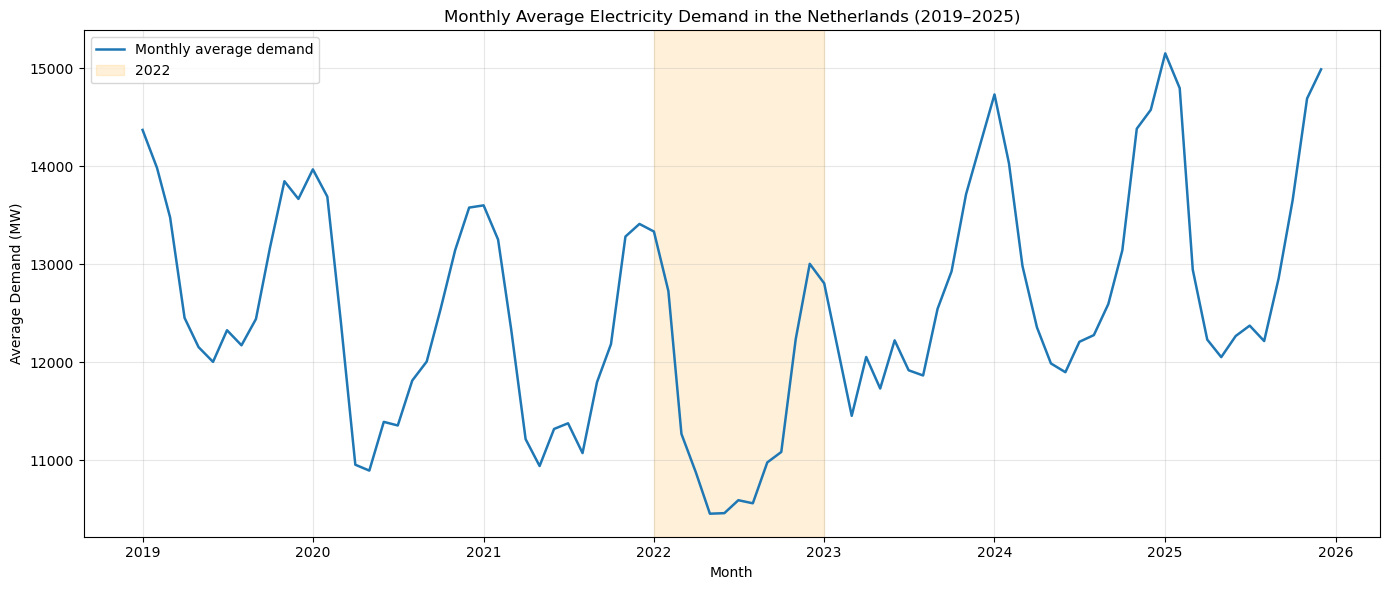

In [3]:
# Calculate average demand for each month
monthly_demand_2019_2025 = (
    df.loc[df["Timestamp"].dt.year.between(2019, 2025)]
      .set_index("Timestamp")["Demand_MW"]
      .resample("MS")
      .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_demand_2019_2025.index,
    monthly_demand_2019_2025.values,
    linewidth=1.8,
    label="Monthly average demand"
)

plt.axvspan(
    pd.Timestamp("2022-01-01"),
    pd.Timestamp("2023-01-01"),
    alpha=0.15,
    color="orange",
    label="2022"
)

plt.title("Monthly Average Electricity Demand in the Netherlands (2019–2025)")
plt.xlabel("Month")
plt.ylabel("Average Demand (MW)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [4]:
# Compare each month in 2022 with the same month in 2021

monthly_demand = (
    df.set_index("Timestamp")["Demand_MW"]
      .resample("MS")
      .mean()
      .rename("Average_Demand_MW")
)

monthly_comparison = monthly_demand.to_frame()

monthly_comparison["Previous_Year_MW"] = (
    monthly_comparison["Average_Demand_MW"].shift(12)
)

monthly_comparison["Change_MW"] = (
    monthly_comparison["Average_Demand_MW"]
    - monthly_comparison["Previous_Year_MW"]
)

monthly_comparison["Change_Percent"] = (
    monthly_comparison["Change_MW"]
    / monthly_comparison["Previous_Year_MW"]
    * 100
)

# Select 2022 and put months in chronological order
comparison_2022 = monthly_comparison.loc["2022"].copy()

comparison_2022["Month"] = comparison_2022.index.month

comparison_2022 = comparison_2022[
    [
        "Month",
        "Previous_Year_MW",
        "Average_Demand_MW",
        "Change_MW",
        "Change_Percent",
    ]
].sort_values("Month")

display(
    comparison_2022
    .round(2)
    .reset_index(drop=True)
    .rename(columns={"Month": "Month_Number"})
    .style.hide(axis="index")
)

Month_Number,Previous_Year_MW,Average_Demand_MW,Change_MW,Change_Percent
1,13602.390000,13335.450000,-266.950000,-1.960000
2,13253.160000,12728.240000,-524.920000,-3.960000
3,12339.120000,11270.550000,-1068.570000,-8.660000
4,11217.220000,10876.880000,-340.340000,-3.030000
5,10942.830000,10456.370000,-486.460000,-4.450000
6,11321.160000,10462.010000,-859.140000,-7.590000
7,11379.020000,10594.100000,-784.920000,-6.900000
8,11074.720000,10562.640000,-512.080000,-4.620000
9,11797.900000,10979.590000,-818.310000,-6.940000
10,12186.750000,11086.120000,-1100.640000,-9.030000


In [5]:
# Compare annual average demand from 2019 to 2025
annual_comparison = (
    df.assign(Year=df["Timestamp"].dt.year)
      .groupby("Year")["Demand_MW"]
      .mean()
      .loc[2019:2025]
      .rename("Average_Demand_MW")
      .to_frame()
)

annual_comparison["Change_MW"] = (
    annual_comparison["Average_Demand_MW"].diff()
)

annual_comparison["Change_Percent"] = (
    annual_comparison["Average_Demand_MW"].pct_change() * 100
)

display(annual_comparison.round(2))

,Average_Demand_MW,Change_MW,Change_Percent
Year,,,
2019,13002.40,NaN,NaN
2020,12311.84,-690.56,-5.31
2021,12144.60,-167.24,-1.36
2022,11459.63,-684.97,-5.64
2023,12465.18,1005.56,8.77
2024,13096.97,631.79,5.07
2025,13345.21,248.24,1.90


## 2. Feature Engineering

This section prepares the hourly electricity-demand data for supervised machine learning. Lag features, rolling statistics, and calendar variables will be created to help the models learn historical demand patterns while avoiding the use of future information.

In [6]:
# Check data quality before feature engineering
print("Total records:", len(df))
print("Duplicate timestamps:", df["Timestamp"].duplicated().sum())
print("Missing timestamps:", df["Timestamp"].isna().sum())
print("Missing demand values:", df["Demand_MW"].isna().sum())
print("Demand data type:", df["Demand_MW"].dtype)
print("Timestamps in chronological order:", df["Timestamp"].is_monotonic_increasing)


Total records: 175320
Duplicate timestamps: 0
Missing timestamps: 0
Missing demand values: 10
Demand data type: float64
Timestamps in chronological order: True


In [7]:
# Create lag features on the original hourly timeline
feature_df = df.copy()

feature_df["Lag_1h"] = feature_df["Demand_MW"].shift(1)
feature_df["Lag_24h"] = feature_df["Demand_MW"].shift(24)
feature_df["Lag_168h"] = feature_df["Demand_MW"].shift(168)

# Keep only rows with a valid target and all required lag values
model_df = feature_df.dropna(
    subset=["Demand_MW", "Lag_1h", "Lag_24h", "Lag_168h"]
).copy()

# Check the result
print("Original records:", len(df))
print("Records available for modelling:", len(model_df))
print("Missing values in required columns:",
      model_df[["Demand_MW", "Lag_1h", "Lag_24h", "Lag_168h"]].isna().sum().sum())

display(model_df[[
    "Timestamp", "Demand_MW", "Lag_1h", "Lag_24h", "Lag_168h"
]].head())


Original records: 175320
Records available for modelling: 175112
Missing values in required columns: 0


,Timestamp,Demand_MW,Lag_1h,Lag_24h,Lag_168h
168,2006-01-08 00:00:00,10264.0,11054.0,10942.0,10215.0
169,2006-01-08 01:00:00,9467.0,10264.0,10030.0,9979.0
170,2006-01-08 02:00:00,9000.0,9467.0,9472.0,9460.0
171,2006-01-08 03:00:00,8776.0,9000.0,9214.0,8833.0
172,2006-01-08 04:00:00,8689.0,8776.0,9129.0,8525.0


In [8]:
# Create calendar features for the modelling dataset
model_df["Hour"] = model_df["Timestamp"].dt.hour
model_df["DayOfWeek"] = model_df["Timestamp"].dt.dayofweek
model_df["Month"] = model_df["Timestamp"].dt.month
model_df["DayOfYear"] = model_df["Timestamp"].dt.dayofyear
model_df["IsWeekend"] = (model_df["DayOfWeek"] >= 5).astype(int)

# Check the final feature columns
print("Modelling dataset shape:", model_df.shape)
print("Feature columns:", model_df.columns.tolist())

display(model_df.head())

Modelling dataset shape: (175112, 10)
Feature columns: ['Timestamp', 'Demand_MW', 'Lag_1h', 'Lag_24h', 'Lag_168h', 'Hour', 'DayOfWeek', 'Month', 'DayOfYear', 'IsWeekend']


,Timestamp,Demand_MW,Lag_1h,Lag_24h,Lag_168h,Hour,DayOfWeek,Month,DayOfYear,IsWeekend
168,2006-01-08 00:00:00,10264.0,11054.0,10942.0,10215.0,0,6,1,8,1
169,2006-01-08 01:00:00,9467.0,10264.0,10030.0,9979.0,1,6,1,8,1
170,2006-01-08 02:00:00,9000.0,9467.0,9472.0,9460.0,2,6,1,8,1
171,2006-01-08 03:00:00,8776.0,9000.0,9214.0,8833.0,3,6,1,8,1
172,2006-01-08 04:00:00,8689.0,8776.0,9129.0,8525.0,4,6,1,8,1


## 3. Correlation Analysis

A correlation heat map helps us understand the relationships between electricity demand and the engineered features. We use it to identify potentially useful predictors and to examine relationships between features before training our machine learning models.

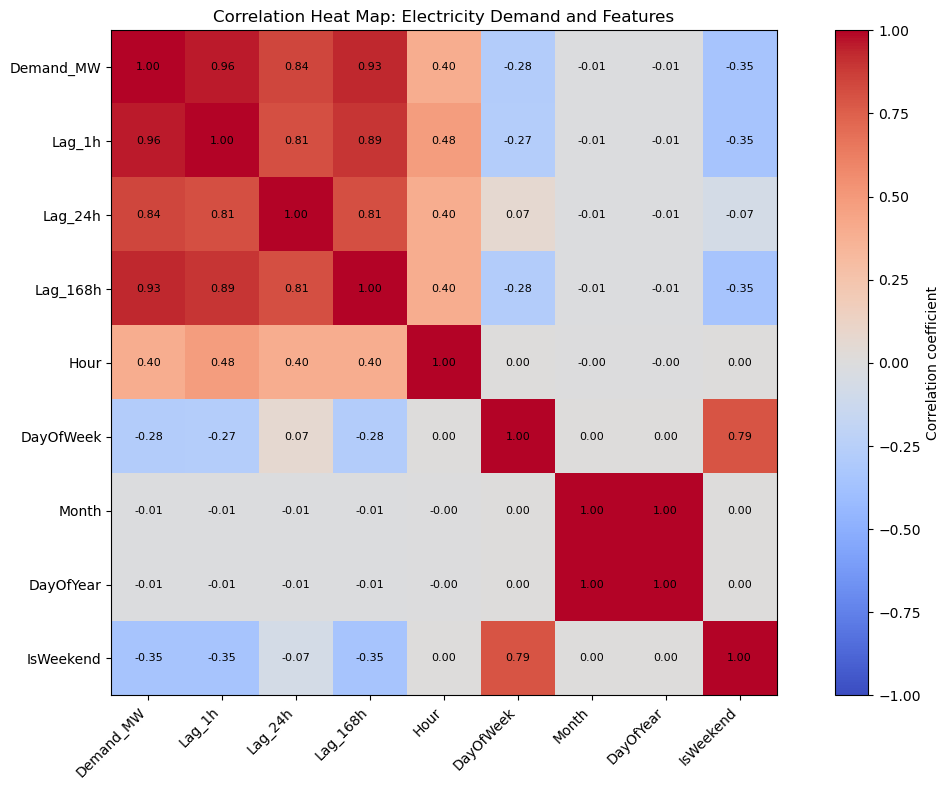

In [9]:
# Select the target and engineered features for correlation analysis
correlation_columns = [
    "Demand_MW",
    "Lag_1h",
    "Lag_24h",
    "Lag_168h",
    "Hour",
    "DayOfWeek",
    "Month",
    "DayOfYear",
    "IsWeekend",
]

# Calculate correlations
correlation_matrix = model_df[correlation_columns].corr()

# Plot the correlation heat map
plt.figure(figsize=(12, 8))

plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation coefficient")

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=45,
    ha="right"
)
plt.yticks(range(len(correlation_columns)), correlation_columns)

# Display correlation values in each cell
for i in range(len(correlation_columns)):
    for j in range(len(correlation_columns)):
        plt.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

plt.title("Correlation Heat Map: Electricity Demand and Features")
plt.tight_layout()
plt.show()


### Interpretation of the Correlation Heat Map

The correlation heat map shows strong positive relationships between electricity demand and the lag features. `Lag_1h` has the strongest correlation (0.96), followed by `Lag_168h` (0.93) and `Lag_24h` (0.84). This suggests that recent demand and demand from the previous day and week may be useful predictors.

`Hour` has a moderate positive correlation (0.40), while `DayOfWeek` (-0.28) and `IsWeekend` (-0.35) show weaker negative relationships with demand. `Month` and `DayOfYear` have correlations close to zero, indicating little linear relationship with demand.

Overall, the lag features appear particularly promising. However, correlation measures linear relationships and does not prove that a feature will improve forecasting accuracy. We will evaluate the features using machine learning models and chronological train/test data.

## Train/Test split

In [10]:
# Split the data chronologically: train on 2006–2024, test on 2025
train_df = model_df[model_df["Timestamp"].dt.year < 2025].copy()
test_df = model_df[model_df["Timestamp"].dt.year == 2025].copy()

# Define the target and input features
feature_columns = [
    "Lag_1h",
    "Lag_24h",
    "Lag_168h",
    "Hour",
    "DayOfWeek",
    "Month",
    "DayOfYear",
    "IsWeekend",
]

X_train = train_df[feature_columns]
y_train = train_df["Demand_MW"]

X_test = test_df[feature_columns]
y_test = test_df["Demand_MW"]

# Check the split
print("Training period:", train_df["Timestamp"].min(), "to", train_df["Timestamp"].max())
print("Testing period:", test_df["Timestamp"].min(), "to", test_df["Timestamp"].max())
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training features:", X_train.shape[1])


Training period: 2006-01-08 00:00:00 to 2024-12-31 23:00:00
Testing period: 2025-01-01 00:00:00 to 2025-12-31 23:00:00
Training records: 166352
Testing records: 8760
Training features: 8


### Evaluation design: 2006–2024 training, 2025 testing

The data are split by time, not randomly. Rows before 2025 are used to fit the initial models; 2025 is held aside for evaluation. This makes the test period resemble a future period and avoids training on later observations before predicting earlier ones.

The metrics below are **MAE** (average absolute error, in MW) and **RMSE** (which penalises larger errors more strongly). Lower values indicate better predictions on this test period.

## 4. Model Training and Evaluation

### 4.1 Linear Regression

Linear Regression is our baseline model. It estimates the relationship between electricity demand and the selected lag and calendar features. We will evaluate its predictions on the unseen 2025 test data using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

In [11]:
# Train the Linear Regression baseline model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Predict electricity demand for the test period
y_pred_linear = linear_model.predict(X_test)

# Evaluate model performance
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))

# Display the results
print("Linear Regression — Test Results (2025)")
print(f"MAE:  {mae_linear:.2f} MW")
print(f"RMSE: {rmse_linear:.2f} MW")


Linear Regression — Test Results (2025)
MAE:  308.27 MW
RMSE: 401.28 MW


**Interpretation of the Linear Regression**

The model's predictions differ from actual electricity demand by an average absolute amount of approximately 308 MW. The RMSE is higher, at 401 MW, which suggests that some larger prediction errors are contributing more heavily to the total error.
These results give us a baseline to compare against Random Forest and XGBoost. We cannot yet say whether the accuracy is good or poor without comparing it with other models and a simple benchmark.

### 4.2 Naive Forecasting Benchmark

A naive forecast provides a simple baseline for evaluating machine learning models. In this project, we use the electricity demand from the same hour one week earlier (168 hours ago) as the prediction for the current hour.

This benchmark captures recurring weekly demand patterns without training a machine learning model. We will evaluate its performance on the 2025 test set using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

In [12]:
# Naive benchmark: use demand from the same hour one week earlier
y_pred_naive = test_df["Lag_168h"]

# Evaluate benchmark performance
mae_naive = mean_absolute_error(y_test, y_pred_naive)
rmse_naive = np.sqrt(mean_squared_error(y_test, y_pred_naive))

# Display the results
print("Naive Benchmark — Test Results (2025)")
print(f"MAE:  {mae_naive:.2f} MW")
print(f"RMSE: {rmse_naive:.2f} MW")


Naive Benchmark — Test Results (2025)
MAE:  540.45 MW
RMSE: 750.46 MW


**Interpretation of the Naive Benchmark**

The naive benchmark achieved an MAE of 540.45 MW and an RMSE of 750.46 MW on the 2025 test set. Linear Regression performed better, achieving an MAE of 308.27 MW and an RMSE of 401.28 MW.

This indicates that combining recent demand lags with calendar features improves predictions compared with using demand from the same hour in the previous week. The naive benchmark provides a useful reference point for evaluating more advanced machine learning models.

### 4.3 Random Forest Regression

Random Forest is an ensemble machine learning model that combines predictions from multiple decision trees. Unlike Linear Regression, it can capture nonlinear relationships and interactions between lag and calendar features.

We will train the model using the same training data and evaluate its performance on the unseen 2025 test set using MAE and RMSE.

In [13]:
# Train the Random Forest regression model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=SEED,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predict electricity demand for the test period
y_pred_rf = rf_model.predict(X_test)

# Evaluate model performance
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

# Display the results
print("Random Forest — Test Results (2025)")
print(f"MAE:  {mae_rf:.2f} MW")
print(f"RMSE: {rmse_rf:.2f} MW")


Random Forest — Test Results (2025)
MAE:  192.36 MW
RMSE: 270.13 MW


**Interpretation of Random Forest Results**

Random Forest achieved an MAE of 192.36 MW and an RMSE of 270.13 MW on the 2025 test set, outperforming both the naive benchmark and Linear Regression. Its MAE was approximately 38% lower than Linear Regression's and 64% lower than the naive benchmark's.

These results suggest that Random Forest captures nonlinear relationships between historical electricity demand and calendar features more effectively than the other approaches tested so far. We will investigate whether hyperparameter tuning can improve its performance further.

### 4.4 XGBoost Regression

XGBoost is a gradient-boosting machine learning algorithm that builds decision trees sequentially. Each new tree aims to improve on the errors made by the existing trees. It can capture nonlinear relationships and interactions between historical demand and calendar features.

We will train an initial XGBoost model and evaluate its performance on the 2025 test set using MAE and RMSE. Hyperparameter tuning will be considered later using chronological validation.

In [14]:
# Train the initial XGBoost regression model
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=SEED,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

# Predict electricity demand for the test period
y_pred_xgb = xgb_model.predict(X_test)

# Evaluate model performance
mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

# Display the results
print("XGBoost — Test Results (2025)")
print(f"MAE:  {mae_xgb:.2f} MW")
print(f"RMSE: {rmse_xgb:.2f} MW")

XGBoost — Test Results (2025)
MAE:  207.37 MW
RMSE: 280.29 MW


**Interpretation of XGBoost Results**

XGBoost achieved an MAE of 207.37 MW and an RMSE of 280.29 MW on the 2025 test set. It outperformed Linear Regression and the naive benchmark but performed slightly worse than the initial Random Forest model.

The results show that both tree-based models are promising for electricity-demand prediction. We will use chronological validation to tune their hyperparameters and compare their performance more reliably before selecting a model for forecasting.

### 4.5 Initial Model Comparison

We evaluated four forecasting approaches on the 2025 test set: a naive benchmark, Linear Regression, Random Forest, and XGBoost. The initial models use their current settings without hyperparameter tuning.

We compare their performance using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE). Lower values indicate better predictive accuracy. These results provide a baseline for evaluating whether hyperparameter tuning improves model performance.

In [15]:
# Compare the initial model results
initial_results = pd.DataFrame({
    "Model": [
        "Naive Benchmark",
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE (MW)": [
        mae_naive,
        mae_linear,
        mae_rf,
        mae_xgb
    ],
    "RMSE (MW)": [
        rmse_naive,
        rmse_linear,
        rmse_rf,
        rmse_xgb
    ]
})

# Sort models by MAE, from best to worst
initial_results = initial_results.sort_values(
    by="MAE (MW)"
).reset_index(drop=True)

display(initial_results.round(2))


,Model,MAE (MW),RMSE (MW)
0,Random Forest,192.36,270.13
1,XGBoost,207.37,280.29
2,Linear Regression,308.27,401.28
3,Naive Benchmark,540.45,750.46


### Interpretation of the initial comparison evaluated on 2025 data

The initial evaluation on 2025 electricity-demand data shows that Random Forest achieved the best performance, with an MAE of 192.36 MW and an RMSE of 270.13 MW. XGBoost ranked second, with an MAE of 207.37 MW and an RMSE of 280.29 MW, followed by Linear Regression. The Naive Benchmark performed worst, producing an MAE of 540.45 MW and an RMSE of 750.46 MW.

These results suggest that the tree-based models capture patterns in electricity demand more effectively than the simple linear and weekly-naive approaches under their initial settings. Random Forest outperformed XGBoost in this first comparison, although further tuning may change their relative performance. Linear Regression provides an interpretable baseline, while the Naive Benchmark provides a seasonal reference by using demand from the same hour one week earlier.

This comparison establishes the baseline performance against which the tuned models will be assessed. The next step is to optimise the model hyperparameters and evaluate whether this improves forecast accuracy on the same 2025 test period. MAE measures average absolute prediction error, while RMSE gives greater weight to larger errors.

## 5. Hyperparameter Tuning

Hyperparameter tuning is the process of finding the model settings that produce the best predictive performance.

In this project, we will tune Random Forest and XGBoost using chronological cross-validation on the 2006–2024 training period. We will use `TimeSeriesSplit` and `RandomizedSearchCV` to test different combinations of hyperparameters while preserving the time order of the data.

After selecting the best hyperparameters, we will retrain each model using the full training period (2006–2024) and evaluate its performance on the unseen 2025 test set using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

Finally, we will compare the tuned models with the initial models to determine whether hyperparameter tuning improves predictive performance.

In [16]:
# Define chronological cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Define the hyperparameter search space
rf_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, 30, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 1.0]
}

# Create the Random Forest model
rf_base_model = RandomForestRegressor(
    random_state=SEED,
    n_jobs=-1
)

# Set up randomized hyperparameter search
rf_search = RandomizedSearchCV(
    estimator=rf_base_model,
    param_distributions=rf_param_grid,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

# Run the search using only the training period (2006–2024)
rf_search.fit(X_train, y_train)

# Display the best settings and validation score
print("Best Random Forest hyperparameters:")
print(rf_search.best_params_)

print(f"Best cross-validation MAE: {-rf_search.best_score_:.2f} MW")


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best Random Forest hyperparameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 30}
Best cross-validation MAE: 200.17 MW


In [17]:
# Retrieve the best Random Forest model
best_rf_model = rf_search.best_estimator_

# Predict electricity demand for the 2025 test period
y_pred_rf_tuned = best_rf_model.predict(X_test)

# Evaluate the tuned model
mae_rf_tuned = mean_absolute_error(y_test, y_pred_rf_tuned)
rmse_rf_tuned = np.sqrt(mean_squared_error(y_test, y_pred_rf_tuned))

# Display the results
print("Tuned Random Forest — Test Results (2025)")
print(f"MAE:  {mae_rf_tuned:.2f} MW")
print(f"RMSE: {rmse_rf_tuned:.2f} MW")


Tuned Random Forest — Test Results (2025)
MAE:  188.26 MW
RMSE: 262.55 MW


In [18]:
# Experiment 2: Expand the Random Forest hyperparameter search

rf_param_grid_2 = {
    "n_estimators": [150, 250, 400],
    "max_depth": [15, 25, 35, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 3, 5],
    "max_features": [0.5, 0.7, 0.9, 1.0]
}

rf_search_2 = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=SEED,
        n_jobs=1
    ),
    param_distributions=rf_param_grid_2,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

# Fit using only the 2006–2024 training period
rf_search_2.fit(X_train, y_train)

print("Best Random Forest hyperparameters — Experiment 2:")
print(rf_search_2.best_params_)

print(
    f"Best cross-validation MAE: "
    f"{-rf_search_2.best_score_:.2f} MW"
)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best Random Forest hyperparameters — Experiment 2:
{'n_estimators': 250, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 35}
Best cross-validation MAE: 198.29 MW


In [19]:
# Retrieve the best model from Random Forest Experiment 2
best_rf_model_2 = rf_search_2.best_estimator_

# Predict electricity demand for 2025
y_pred_rf_tuned_2 = best_rf_model_2.predict(X_test)

# Evaluate the model
mae_rf_tuned_2 = mean_absolute_error(y_test, y_pred_rf_tuned_2)
rmse_rf_tuned_2 = np.sqrt(
    mean_squared_error(y_test, y_pred_rf_tuned_2)
)

print("Random Forest — Experiment 2 Test Results (2025)")
print(f"MAE:  {mae_rf_tuned_2:.2f} MW")
print(f"RMSE: {rmse_rf_tuned_2:.2f} MW")


Random Forest — Experiment 2 Test Results (2025)
MAE:  188.38 MW
RMSE: 261.65 MW


**Interpretation of Random Forest Hyperparameter Tuning by training on 2006-2024 data and testing on 2025 data**

Two hyperparameter tuning experiments were conducted for Random Forest using chronological cross-validation on the 2006–2024 training data.

Experiment 1 achieved an MAE of 188.26 MW and an RMSE of 262.55 MW on the 2025 test set. Experiment 2 achieved an MAE of 188.38 MW and an RMSE of 261.65 MW.

Compared with the initial Random Forest model, both tuned models improved predictive performance. Experiment 1 achieved the lowest MAE, while Experiment 2 achieved the lowest RMSE. The differences between the two experiments are small, suggesting that both parameter configurations perform similarly. Experiment 1 is preferred if minimising average absolute error is the main objective.

### 5.2 XGBoost Hyperparameter Tuning

We use `RandomizedSearchCV` and chronological cross-validation to identify promising XGBoost hyperparameters using the 2006–2024 training period. The search explores different combinations of tree depth, learning rate, number of boosting rounds, and sampling settings.

The best parameter combination will be selected based on validation MAE. We will then evaluate the tuned model on the unseen 2025 test set using MAE and RMSE.

In [20]:
# Define the XGBoost hyperparameter search space
xgb_param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [3, 4, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5]
}

# Create the base XGBoost model
xgb_base_model = XGBRegressor(
    objective="reg:squarederror",
    random_state=SEED,
    n_jobs=1
)

# Set up randomized hyperparameter search
xgb_search = RandomizedSearchCV(
    estimator=xgb_base_model,
    param_distributions=xgb_param_grid,
    n_iter=15,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

# Run the search using only the training period (2006–2024)
xgb_search.fit(X_train, y_train)

# Display the best settings and validation score
print("Best XGBoost hyperparameters:")
print(xgb_search.best_params_)

print(f"Best cross-validation MAE: {-xgb_search.best_score_:.2f} MW")


Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best XGBoost hyperparameters:
{'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Best cross-validation MAE: 199.77 MW


In [21]:
# Retrieve the best XGBoost model
best_xgb_model = xgb_search.best_estimator_

# Predict electricity demand for the 2025 test period
y_pred_xgb_tuned = best_xgb_model.predict(X_test)

# Evaluate the tuned model
mae_xgb_tuned = mean_absolute_error(y_test, y_pred_xgb_tuned)
rmse_xgb_tuned = np.sqrt(mean_squared_error(y_test, y_pred_xgb_tuned))

# Display the results
print("Tuned XGBoost — Test Results (2025)")
print(f"MAE:  {mae_xgb_tuned:.2f} MW")
print(f"RMSE: {rmse_xgb_tuned:.2f} MW")


Tuned XGBoost — Test Results (2025)
MAE:  197.77 MW
RMSE: 267.81 MW


In [22]:
# Experiment 2: Expand the XGBoost hyperparameter search

xgb_param_grid_2 = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [2, 3, 4, 5, 6],
    "learning_rate": [0.01, 0.02, 0.03, 0.05],
    "subsample": [0.7, 0.8, 0.9],
    "colsample_bytree": [0.7, 0.8, 0.9],
    "min_child_weight": [3, 5, 7],
    "reg_lambda": [1, 5, 10],
    "reg_alpha": [0, 0.1, 1]
}

xgb_search_2 = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=1
    ),
    param_distributions=xgb_param_grid_2,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

# Fit using only the 2006–2024 training period
xgb_search_2.fit(X_train, y_train)

print("Best XGBoost hyperparameters — Experiment 2:")
print(xgb_search_2.best_params_)

print(
    f"Best cross-validation MAE: "
    f"{-xgb_search_2.best_score_:.2f} MW"
)


Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best XGBoost hyperparameters — Experiment 2:
{'subsample': 0.9, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 700, 'min_child_weight': 7, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.9}
Best cross-validation MAE: 204.16 MW


In [23]:
# Retrieve the best model from XGBoost Experiment 2
best_xgb_model_2 = xgb_search_2.best_estimator_

# Predict electricity demand for 2025
y_pred_xgb_tuned_2 = best_xgb_model_2.predict(X_test)

# Evaluate the model
mae_xgb_tuned_2 = mean_absolute_error(y_test, y_pred_xgb_tuned_2)
rmse_xgb_tuned_2 = np.sqrt(
    mean_squared_error(y_test, y_pred_xgb_tuned_2)
)

# Display the results
print("XGBoost — Experiment 2 Test Results (2025)")
print(f"MAE:  {mae_xgb_tuned_2:.2f} MW")
print(f"RMSE: {rmse_xgb_tuned_2:.2f} MW")


XGBoost — Experiment 2 Test Results (2025)
MAE:  193.50 MW
RMSE: 261.47 MW


**Interpretation of XGBoost Hyperparameter Tuning by training on 2006-2024 data and testing on 2025 data**

Two hyperparameter tuning experiments were conducted for XGBoost using chronological cross-validation on the 2006–2024 training data.

Experiment 1 achieved an MAE of 197.77 MW and an RMSE of 267.81 MW on the 2025 test set. Experiment 2 improved the results, achieving an MAE of 193.50 MW and an RMSE of 261.47 MW.

Compared with the initial XGBoost model, Experiment 2 reduced both MAE and RMSE, indicating improved predictive performance. It also achieved the lowest RMSE among the tuned Random Forest and XGBoost candidates. However, Random Forest Experiment 1 still achieved the lowest MAE overall. Therefore, the preferred model depends on whether average absolute error or the greater sensitivity to larger errors represented by RMSE is prioritised.

## 6. Expanded Features: Second Modelling Stage

The first modelling stage uses one-hour, one-day, and one-week lags plus calendar variables. This second stage adds shorter and longer lags and rolling averages based only on earlier hours. It tests whether richer recent-history information improves hourly predictions.

The expanded feature set is evaluated on the same 2025 period, so its metrics can be compared fairly with the earlier feature set.

## 6.1 Expanded Lag and Rolling Features

Electricity demand often follows daily and weekly patterns. To capture these patterns, we introduce additional lag features and rolling averages.

Lag features represent demand at specific points in the past, while rolling averages summarise demand over a recent period. These features may help machine learning models capture recurring patterns and reduce the influence of short-term fluctuations.

All rolling features will be calculated using past observations only to prevent data leakage.

In [24]:
# Create additional features using past demand values
feature_df = df.copy()

# Additional lag features
feature_df["Lag_2h"] = feature_df["Demand_MW"].shift(2)
feature_df["Lag_48h"] = feature_df["Demand_MW"].shift(48)
feature_df["Lag_336h"] = feature_df["Demand_MW"].shift(336)

# Rolling averages based only on previous hours
feature_df["Rolling_Mean_24h"] = (
    feature_df["Demand_MW"].shift(1).rolling(window=24).mean()
)

feature_df["Rolling_Mean_168h"] = (
    feature_df["Demand_MW"].shift(1).rolling(window=168).mean()
)

# Check the new features
display(
    feature_df[
        [
            "Timestamp",
            "Demand_MW",
            "Lag_2h",
            "Lag_48h",
            "Lag_336h",
            "Rolling_Mean_24h",
            "Rolling_Mean_168h"
        ]
    ].head(10)
)

,Timestamp,Demand_MW,Lag_2h,Lag_48h,Lag_336h,Rolling_Mean_24h,Rolling_Mean_168h
0,2006-01-01 00:00:00,10215.0,NaN,NaN,NaN,NaN,NaN
1,2006-01-01 01:00:00,9979.0,NaN,NaN,NaN,NaN,NaN
2,2006-01-01 02:00:00,9460.0,10215.0,NaN,NaN,NaN,NaN
3,2006-01-01 03:00:00,8833.0,9979.0,NaN,NaN,NaN,NaN
4,2006-01-01 04:00:00,8525.0,9460.0,NaN,NaN,NaN,NaN
5,2006-01-01 05:00:00,8458.0,8833.0,NaN,NaN,NaN,NaN
6,2006-01-01 06:00:00,8526.0,8525.0,NaN,NaN,NaN,NaN
7,2006-01-01 07:00:00,8760.0,8458.0,NaN,NaN,NaN,NaN
8,2006-01-01 08:00:00,9171.0,8526.0,NaN,NaN,NaN,NaN
9,2006-01-01 09:00:00,9600.0,8760.0,NaN,NaN,NaN,NaN


In [25]:
# Create the expanded feature dataset from the original data
feature_df = df.copy()

# Original lag features
feature_df["Lag_1h"] = feature_df["Demand_MW"].shift(1)
feature_df["Lag_24h"] = feature_df["Demand_MW"].shift(24)
feature_df["Lag_168h"] = feature_df["Demand_MW"].shift(168)

# Additional lag features
feature_df["Lag_2h"] = feature_df["Demand_MW"].shift(2)
feature_df["Lag_48h"] = feature_df["Demand_MW"].shift(48)
feature_df["Lag_336h"] = feature_df["Demand_MW"].shift(336)

# Rolling averages using previous hours only
feature_df["Rolling_Mean_24h"] = (
    feature_df["Demand_MW"].shift(1).rolling(window=24).mean()
)
feature_df["Rolling_Mean_168h"] = (
    feature_df["Demand_MW"].shift(1).rolling(window=168).mean()
)

# Calendar features
feature_df["Hour"] = feature_df["Timestamp"].dt.hour
feature_df["DayOfWeek"] = feature_df["Timestamp"].dt.dayofweek
feature_df["Month"] = feature_df["Timestamp"].dt.month
feature_df["DayOfYear"] = feature_df["Timestamp"].dt.dayofyear
feature_df["IsWeekend"] = (feature_df["DayOfWeek"] >= 5).astype(int)

# Define all expanded model features
expanded_feature_columns = [
    "Lag_1h", "Lag_2h", "Lag_24h", "Lag_48h",
    "Lag_168h", "Lag_336h",
    "Rolling_Mean_24h", "Rolling_Mean_168h",
    "Hour", "DayOfWeek", "Month", "DayOfYear", "IsWeekend"
]

# Remove rows with missing target or required features
expanded_model_df = feature_df.dropna(
    subset=["Demand_MW"] + expanded_feature_columns
).copy()

# Check the result
print("Original records:", len(df))
print("Expanded modelling records:", len(expanded_model_df))
print("Number of features:", len(expanded_feature_columns))
print(
    "Missing values in modelling columns:",
    expanded_model_df[
        ["Demand_MW"] + expanded_feature_columns
    ].isna().sum().sum()
)

display(expanded_model_df.head())


Original records: 175320
Expanded modelling records: 173284
Number of features: 13
Missing values in modelling columns: 0


,Timestamp,Demand_MW,Lag_1h,Lag_24h,Lag_168h,Lag_2h,Lag_48h,Lag_336h,Rolling_Mean_24h,Rolling_Mean_168h,Hour,DayOfWeek,Month,DayOfYear,IsWeekend
336,2006-01-15 00:00:00,10212.0,11057.0,10932.0,10264.0,11713.0,10965.0,10215.0,11932.333333,13124.565476,0,6,1,15,1
337,2006-01-15 01:00:00,9517.0,10212.0,10007.0,9467.0,11057.0,10184.0,9979.0,11902.333333,13124.255952,1,6,1,15,1
338,2006-01-15 02:00:00,9147.0,9517.0,9489.0,9000.0,10212.0,9788.0,9460.0,11881.916667,13124.553571,2,6,1,15,1
339,2006-01-15 03:00:00,8916.0,9147.0,9290.0,8776.0,9517.0,9609.0,8833.0,11867.666667,13125.428571,3,6,1,15,1
340,2006-01-15 04:00:00,8832.0,8916.0,9222.0,8689.0,9147.0,9623.0,8525.0,11852.083333,13126.261905,4,6,1,15,1


In [26]:
# Split expanded data chronologically
train_df_expanded = expanded_model_df[
    expanded_model_df["Timestamp"].dt.year < 2025
].copy()

test_df_expanded = expanded_model_df[
    expanded_model_df["Timestamp"].dt.year == 2025
].copy()

# Create training and testing features and targets
X_train_expanded = train_df_expanded[expanded_feature_columns]
y_train_expanded = train_df_expanded["Demand_MW"]

X_test_expanded = test_df_expanded[expanded_feature_columns]
y_test_expanded = test_df_expanded["Demand_MW"]

# Check the split
print("Training records:", len(train_df_expanded))
print("Testing records:", len(test_df_expanded))
print("Training period:",
      train_df_expanded["Timestamp"].min(),
      "to",
      train_df_expanded["Timestamp"].max())
print("Testing period:",
      test_df_expanded["Timestamp"].min(),
      "to",
      test_df_expanded["Timestamp"].max())
print("Number of features:", len(expanded_feature_columns))

Training records: 164524
Testing records: 8760
Training period: 2006-01-15 00:00:00 to 2024-12-31 23:00:00
Testing period: 2025-01-01 00:00:00 to 2025-12-31 23:00:00
Number of features: 13


In [27]:
# Train Random Forest using the expanded features
best_rf_expanded = RandomForestRegressor(
    n_estimators=200,
    max_depth=30,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=SEED,
    n_jobs=-1
)

best_rf_expanded.fit(X_train_expanded, y_train_expanded)

# Predict demand for 2025
y_pred_rf_expanded = best_rf_expanded.predict(X_test_expanded)

# Evaluate predictions
mae_rf_expanded = mean_absolute_error(
    y_test_expanded, y_pred_rf_expanded
)

rmse_rf_expanded = np.sqrt(
    mean_squared_error(y_test_expanded, y_pred_rf_expanded)
)

print(f"Expanded Random Forest MAE: {mae_rf_expanded:.2f} MW")
print(f"Expanded Random Forest RMSE: {rmse_rf_expanded:.2f} MW")

Expanded Random Forest MAE: 164.04 MW
Expanded Random Forest RMSE: 228.63 MW


In [28]:
# Train XGBoost using the expanded features
best_xgb_expanded = XGBRegressor(
    objective="reg:squarederror",
    subsample=0.9,
    reg_lambda=1,
    reg_alpha=1,
    n_estimators=700,
    min_child_weight=7,
    max_depth=6,
    learning_rate=0.05,
    colsample_bytree=0.9,
    random_state=SEED,
    n_jobs=-1
)

best_xgb_expanded.fit(X_train_expanded, y_train_expanded)

# Predict demand for 2025
y_pred_xgb_expanded = best_xgb_expanded.predict(X_test_expanded)

# Evaluate predictions
mae_xgb_expanded = mean_absolute_error(
    y_test_expanded, y_pred_xgb_expanded
)

rmse_xgb_expanded = np.sqrt(
    mean_squared_error(y_test_expanded, y_pred_xgb_expanded)
)

print(f"Expanded XGBoost MAE: {mae_xgb_expanded:.2f} MW")
print(f"Expanded XGBoost RMSE: {rmse_xgb_expanded:.2f} MW")

Expanded XGBoost MAE: 156.43 MW
Expanded XGBoost RMSE: 209.51 MW


,Feature,Importance
0,Lag_1h,0.720668
4,Lag_168h,0.184612
5,Lag_336h,0.036092
2,Lag_24h,0.014263
1,Lag_2h,0.013593
8,Hour,0.011999
9,DayOfWeek,0.006010
6,Rolling_Mean_24h,0.003582
12,IsWeekend,0.003531
11,DayOfYear,0.001857


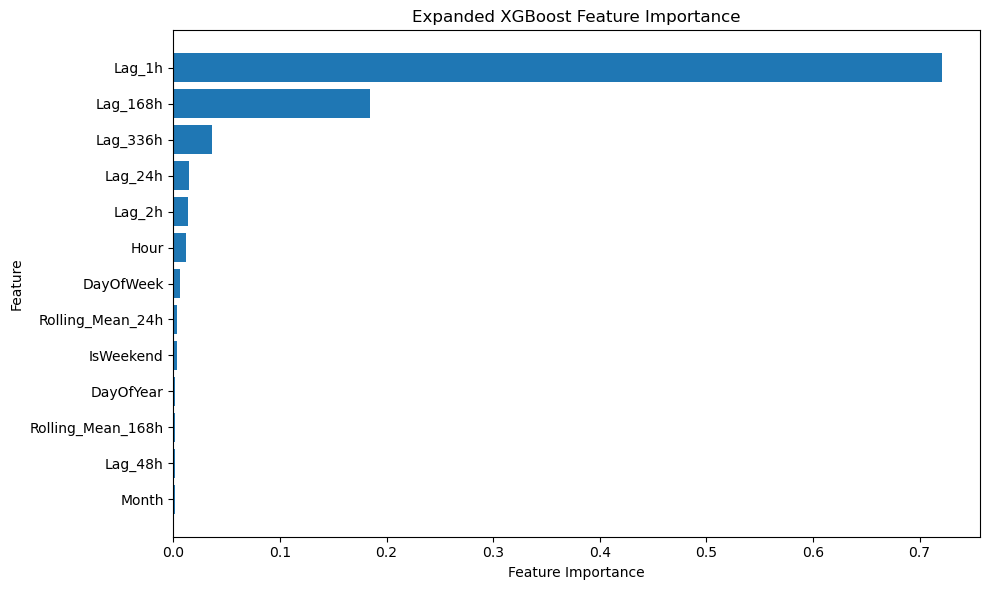

In [29]:
# Examine XGBoost feature importance
feature_importance = pd.DataFrame({
    "Feature": expanded_feature_columns,
    "Importance": best_xgb_expanded.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

display(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Expanded XGBoost Feature Importance")
plt.tight_layout()
plt.show()

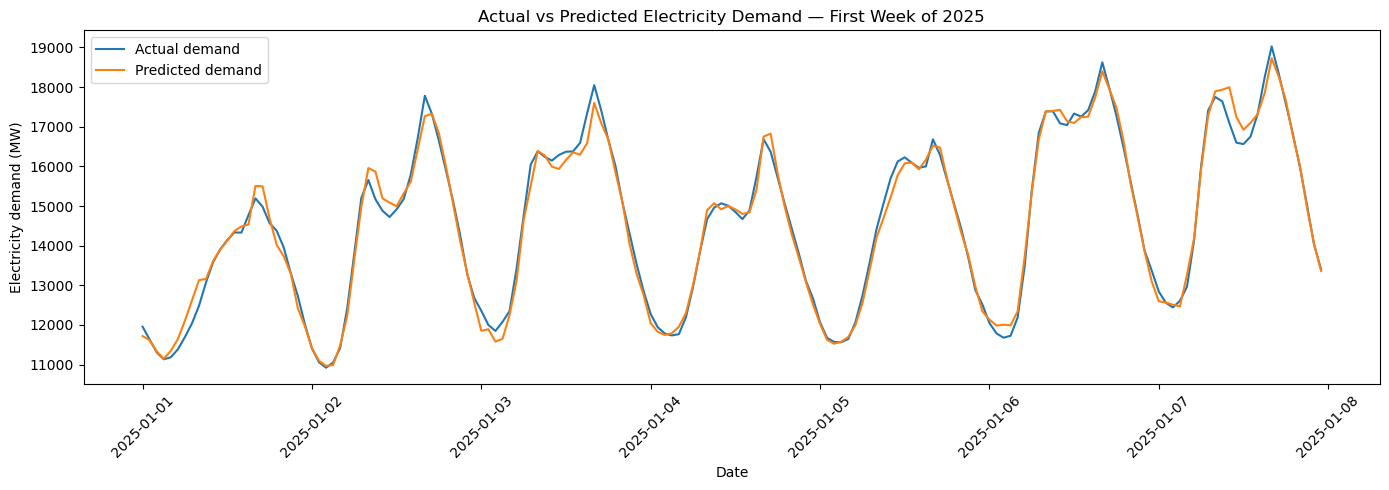

In [30]:
# Select the first week of January 2025
plot_start = pd.Timestamp("2025-01-01")
plot_end = pd.Timestamp("2025-01-08")

mask = (
    (test_df_expanded["Timestamp"] >= plot_start)
    & (test_df_expanded["Timestamp"] < plot_end)
)

plt.figure(figsize=(14, 5))

plt.plot(
    test_df_expanded.loc[mask, "Timestamp"],
    y_test_expanded.loc[mask],
    label="Actual demand"
)

plt.plot(
    test_df_expanded.loc[mask, "Timestamp"],
    y_pred_xgb_expanded[mask.to_numpy()],
    label="Predicted demand"
)

plt.xlabel("Date")
plt.ylabel("Electricity demand (MW)")
plt.title("Actual vs Predicted Electricity Demand — First Week of 2025")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [31]:
# Compare original and expanded XGBoost on the same test period
comparison_df = pd.DataFrame({
    "Model": ["Original XGBoost", "Expanded XGBoost"],
    "MAE_MW": [
        mean_absolute_error(y_test, y_pred_xgb),
        mean_absolute_error(y_test_expanded, y_pred_xgb_expanded)
    ],
    "RMSE_MW": [
        np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
        np.sqrt(mean_squared_error(y_test_expanded, y_pred_xgb_expanded))
    ]
})

display(comparison_df.round(2))

,Model,MAE_MW,RMSE_MW
0,Original XGBoost,207.37,280.29
1,Expanded XGBoost,156.43,209.51


### Interpretation of the expanded-feature comparison 

The expanded XGBoost model outperformed the original model on the 2025 test period. Its MAE decreased from 207.37 MW to 156.43 MW, while its RMSE fell from 280.29 MW to 209.51 MW.

This represents a 24.6% reduction in MAE and a 25.3% reduction in RMSE, indicating that the additional lag and rolling features improved the model's predictive accuracy. The results suggest that incorporating demand information from a wider range of past hours helped XGBoost capture electricity-demand patterns more effectively.

## 7. Chronological Validation and Final XGBoost Selection

The previous experiments compared the original and expanded XGBoost models using the 2025 test period. The expanded feature set improved prediction accuracy, with lower MAE and RMSE.

To further improve the model selection process, we will introduce a separate chronological validation period. The data from 2006 to 2022 will be used to train candidate models, while data from 2023 and 2024 will be used to evaluate different model settings. The year 2025 will remain separate for the final evaluation.

This approach allows us to select promising XGBoost hyperparameters without repeatedly relying on the 2025 test results. We will reuse the expanded feature set developed earlier in the notebook.

In [32]:
# Split the training data into training and validation periods
train_df_cv = expanded_model_df[
    expanded_model_df["Timestamp"].dt.year < 2023
].copy()

validation_df = expanded_model_df[
    expanded_model_df["Timestamp"].dt.year.isin([2023, 2024])
].copy()

# Create training features and target
X_train_cv = train_df_cv[expanded_feature_columns]
y_train_cv = train_df_cv["Demand_MW"]

# Create validation features and target
X_validation = validation_df[expanded_feature_columns]
y_validation = validation_df["Demand_MW"]

# Check the chronological split
print("Training records:", len(train_df_cv))
print("Validation records:", len(validation_df))

print(
    "Training period:",
    train_df_cv["Timestamp"].min(),
    "to",
    train_df_cv["Timestamp"].max()
)

print(
    "Validation period:",
    validation_df["Timestamp"].min(),
    "to",
    validation_df["Timestamp"].max()
)

Training records: 146980
Validation records: 17544
Training period: 2006-01-15 00:00:00 to 2022-12-31 23:00:00
Validation period: 2023-01-01 00:00:00 to 2024-12-31 23:00:00


In [33]:
# Check that the training and validation datasets are ready
print("Training features:", X_train_cv.shape)
print("Validation features:", X_validation.shape)
print("Same feature columns:",
      list(X_train_cv.columns) == list(X_validation.columns))
print("Missing values in training features:",
      X_train_cv.isna().sum().sum())
print("Missing values in validation features:",
      X_validation.isna().sum().sum())

Training features: (146980, 13)
Validation features: (17544, 13)
Same feature columns: True
Missing values in training features: 0
Missing values in validation features: 0


In [34]:
# Tune XGBoost using time-series cross-validation
xgb_param_dist = {
    "n_estimators": [300, 500, 700],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05],
    "subsample": [0.8, 0.9],
    "colsample_bytree": [0.8, 0.9],
    "min_child_weight": [3, 7],
    "reg_alpha": [0, 1],
    "reg_lambda": [1, 5]
}

xgb_tuning = RandomizedSearchCV(
    estimator=XGBRegressor(
        objective="reg:squarederror",
        random_state=SEED,
        n_jobs=1
    ),
    param_distributions=xgb_param_dist,
    n_iter=10,
    scoring="neg_mean_absolute_error",
    cv=TimeSeriesSplit(n_splits=3),
    random_state=SEED,
    n_jobs=-1,
    verbose=1
)

xgb_tuning.fit(X_train_cv, y_train_cv)

print("Best parameters:", xgb_tuning.best_params_)
print("Best cross-validation MAE:", -xgb_tuning.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 700, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.9}
Best cross-validation MAE: 180.04352061947915


In [35]:
# Evaluate the best XGBoost model on the validation period
best_xgb_cv = xgb_tuning.best_estimator_

y_pred_xgb_validation = best_xgb_cv.predict(X_validation)

validation_mae = mean_absolute_error(
    y_validation, y_pred_xgb_validation
)

validation_rmse = np.sqrt(
    mean_squared_error(y_validation, y_pred_xgb_validation)
)

print(f"Validation MAE: {validation_mae:.2f} MW")
print(f"Validation RMSE: {validation_rmse:.2f} MW")

Validation MAE: 159.43 MW
Validation RMSE: 231.51 MW


**Interpretation — 2023–2024 validation**

The 2023–2024 period is used to compare model settings before the final 2025 evaluation. Because this validation period follows the earlier training years, it provides a chronological check on whether the selected settings generalise to more recent data. The results here are for model selection, not the final reported test performance.

### Separate validation results for 2023 and 2024

The combined 2023–2024 validation metrics show average performance across both years. A year-by-year breakdown helps us check whether performance was similar in each year or whether one year was harder to predict. This is useful context because electricity demand conditions can change over time. These yearly results are still validation diagnostics; 2025 remains the final holdout.

In [36]:
# Calculate validation errors separately for 2023 and 2024
validation_predictions_by_year = validation_df[["Timestamp", "Demand_MW"]].copy()
validation_predictions_by_year["Predicted_MW"] = y_pred_xgb_validation
validation_predictions_by_year["Year"] = validation_predictions_by_year["Timestamp"].dt.year

yearly_validation_rows = []
for year, group in validation_predictions_by_year.groupby("Year"):
    yearly_validation_rows.append({
        "Year": int(year),
        "Observations": len(group),
        "MAE (MW)": mean_absolute_error(group["Demand_MW"], group["Predicted_MW"]),
        "RMSE (MW)": np.sqrt(mean_squared_error(group["Demand_MW"], group["Predicted_MW"]))
    })

yearly_validation_results = pd.DataFrame(yearly_validation_rows)
display(yearly_validation_results.round(2))

,Year,Observations,MAE (MW),RMSE (MW)
0,2023,8760,173.91,253.92
1,2024,8784,144.98,206.76


**Interpretation guide:** compare the 2023 and 2024 MAE/RMSE values. Higher errors in one year indicate that the model found that year's demand patterns harder to predict. The table describes differences in predictive difficulty; it does not explain their causes by itself.

In [37]:
# Compare the previous expanded XGBoost with the tuned model on the same 2023–2024 validation period

previous_xgb_expanded = XGBRegressor(
    objective="reg:squarederror",
    subsample=0.9,
    reg_lambda=1,
    reg_alpha=1,
    n_estimators=700,
    min_child_weight=7,
    max_depth=6,
    learning_rate=0.05,
    colsample_bytree=0.9,
    random_state=SEED,
    n_jobs=-1
)

previous_xgb_expanded.fit(X_train_cv, y_train_cv)

y_pred_previous_validation = previous_xgb_expanded.predict(
    X_validation
)

validation_comparison = pd.DataFrame({
    "Model": [
        "Previous Expanded XGBoost",
        "Tuned XGBoost"
    ],
    "MAE_MW": [
        mean_absolute_error(
            y_validation, y_pred_previous_validation
        ),
        validation_mae
    ],
    "RMSE_MW": [
        np.sqrt(mean_squared_error(
            y_validation, y_pred_previous_validation
        )),
        validation_rmse
    ]
})

display(validation_comparison.round(2))

,Model,MAE_MW,RMSE_MW
0,Previous Expanded XGBoost,167.07,239.14
1,Tuned XGBoost,159.43,231.51


In [38]:
# Retrain the selected XGBoost model on all data through 2024
best_xgb_final = XGBRegressor(
    objective="reg:squarederror",
    **xgb_tuning.best_params_,
    random_state=SEED,
    n_jobs=-1
)

best_xgb_final.fit(X_train_expanded, y_train_expanded)

# Evaluate on the held-out 2025 test period
y_pred_xgb_final = best_xgb_final.predict(X_test_expanded)

test_mae = mean_absolute_error(
    y_test_expanded, y_pred_xgb_final
)

test_rmse = np.sqrt(
    mean_squared_error(y_test_expanded, y_pred_xgb_final)
)

print(f"Final test MAE: {test_mae:.2f} MW")
print(f"Final test RMSE: {test_rmse:.2f} MW")

Final test MAE: 147.39 MW
Final test RMSE: 198.91 MW


### Interpretation of the Final Hourly Model Evaluation

Hyperparameter tuning improved the performance of the expanded XGBoost model. Compared with the previous expanded model, the tuned model reduced MAE from 167.07 MW to 159.43 MW and RMSE from 239.14 MW to 231.51 MW. This represents reductions of approximately 4.6% in MAE and 3.2% in RMSE, indicating a modest improvement in prediction accuracy.

After tuning, the model was refitted using the available training observations through 2024 and evaluated on the unseen 2025 test period. The final test results were an MAE of 147.39 MW and an RMSE of 198.91 MW. These are the principal holdout metrics for evaluating the model's rolling one-hour-ahead electricity-demand predictions.

Overall, the results indicate that the expanded features and hyperparameter tuning helped improve XGBoost's predictive performance. However, these metrics apply to the specified one-hour-ahead evaluation task and should not be assumed to represent the accuracy of recursive forecasts extending several years into the future.

### How to Read the Consolidated Model Comparison

The table summarises model performance across different stages of the workflow. Initial and expanded-feature models are evaluated on the 2025 test period, while the validation results cover 2023–2024 and were used for model selection. Lower MAE and RMSE indicate better predictive accuracy within each evaluation period. The final tuned XGBoost results represent the model's performance on the 2025 holdout set.

In [56]:
# Consolidated comparison using metrics calculated in this notebook

def metric_row(model_name, period, actual, predicted):
    return {
        "Model": model_name,
        "Evaluation period": period,
        "MAE (MW)": mean_absolute_error(actual, predicted),
        "RMSE (MW)": np.sqrt(mean_squared_error(actual, predicted))
    }

all_model_results = pd.DataFrame([
    metric_row("Naive weekly benchmark", "2025 test", y_test, y_pred_naive),
    metric_row("Linear Regression", "2025 test", y_test, y_pred_linear),
    metric_row("Random Forest — initial", "2025 test", y_test, y_pred_rf),
    metric_row("XGBoost — initial", "2025 test", y_test, y_pred_xgb),
    metric_row("Random Forest — expanded features", "2025 test", y_test_expanded, y_pred_rf_expanded),
    metric_row("XGBoost — expanded features", "2025 test", y_test_expanded, y_pred_xgb_expanded),
    metric_row("Previous expanded XGBoost", "2023–2024 validation", y_validation, y_pred_previous_validation),
    metric_row("Tuned XGBoost", "2023–2024 validation", y_validation, y_pred_xgb_validation),
    metric_row("Tuned XGBoost — final holdout", "2025 test", y_test_expanded, y_pred_xgb_final)
])

display(all_model_results.round(2))


,Model,Evaluation period,MAE (MW),RMSE (MW)
0,Naive weekly benchmark,2025 test,540.45,750.46
1,Linear Regression,2025 test,308.27,401.28
2,Random Forest — initial,2025 test,192.36,270.13
3,XGBoost — initial,2025 test,207.37,280.29
4,Random Forest — expanded features,2025 test,164.04,228.63
5,XGBoost — expanded features,2025 test,156.43,209.51
6,Previous expanded XGBoost,2023–2024 validation,167.07,239.14
7,Tuned XGBoost,2023–2024 validation,159.43,231.51
8,Tuned XGBoost — final holdout,2025 test,147.39,198.91


## Summary and Interpretation of Model Results

The model comparisons show a clear improvement as the forecasting workflow progresses from simple benchmarks to machine-learning models with expanded features. On the 2025 test period, the weekly naive benchmark achieved an MAE of 540.45 MW, while Linear Regression achieved 308.27 MW. The initial Random Forest and XGBoost models performed substantially better, with MAEs of 192.36 MW and 207.37 MW, respectively.

Adding expanded lag and rolling features improved both tree-based models. Random Forest achieved an MAE of 164.04 MW, while expanded XGBoost achieved 156.43 MW on the 2025 test period. Following hyperparameter tuning, the final XGBoost model achieved a 2025 holdout MAE of **147.39 MW** and RMSE of **198.91 MW**.

The 2023–2024 validation results were used to guide hyperparameter selection, while 2025 was reserved for final holdout evaluation. The validation metrics and 2025 test metrics serve different purposes and should not be treated as a single directly comparable ranking. Similarly, improvements across modelling stages should be interpreted in light of any changes to the training data, feature set and evaluation setup.

The next section investigates whether excluding 2022 target observations affects the final 2025 results. This provides an additional robustness check. The longer-term forecasts to 2030 are considered separately because recursive forecasting introduces additional uncertainty as predictions are used to construct future lag features. The final 2025 one-hour-ahead results should therefore not be assumed to represent the accuracy of multi-year forecasts.

## 8. 2022 Sensitivity Analysis: Does Including 2022 Change 2025 Accuracy?

The demand series shows a marked decline in 2022. We should not automatically remove this year: it is part of the real historical record, and the primary model should learn from the full history. This additional experiment asks a narrower question: **does fitting on 2022 target observations change performance on the same 2025 test period?**

We compare Random Forest and XGBoost under both training setups, using fixed settings selected earlier in the notebook:

- **Scenario A — 2022 included:** fit on all eligible target rows through 2024.
- **Scenario B — 2022 excluded:** use the same training period and features, but omit rows whose target timestamp is in 2022.

Crucially, lag and rolling features are created on the intact hourly timeline before any training rows are excluded. This preserves real temporal context, including observed 2022 values in later lag features. Only the rows used as training targets are excluded for Model B. All four fits (two algorithms × two training setups) are evaluated on exactly the same 2025 observations.

In [57]:
# Keep the same engineered features and 2025 test period

train_2022_exp = expanded_model_df[
    expanded_model_df["Timestamp"].dt.year < 2025
].copy()

test_2022_exp = expanded_model_df[
    expanded_model_df["Timestamp"].dt.year == 2025
].copy()

# Model A: include 2022 target rows
train_with_2022 = train_2022_exp.copy()

# Model B: exclude only target rows from 2022
train_without_2022 = train_2022_exp[
    train_2022_exp["Timestamp"].dt.year != 2022
].copy()

# Prepare features and targets
X_train_with_2022 = train_with_2022[expanded_feature_columns]
y_train_with_2022 = train_with_2022["Demand_MW"]

X_train_without_2022 = train_without_2022[expanded_feature_columns]
y_train_without_2022 = train_without_2022["Demand_MW"]

X_test_2022_exp = test_2022_exp[expanded_feature_columns]
y_test_2022_exp = test_2022_exp["Demand_MW"]

# Confirm dataset sizes and test-period consistency
print("Training rows with 2022 included:", len(train_with_2022))
print("Training rows with 2022 excluded:", len(train_without_2022))
print("2025 test rows:", len(test_2022_exp))

print(
    "Same 2025 timestamps:",
    test_2022_exp["Timestamp"].reset_index(drop=True).equals(
        test_df_expanded["Timestamp"].reset_index(drop=True)
    )
)

Training rows with 2022 included: 164524
Training rows with 2022 excluded: 155764
2025 test rows: 8760
Same 2025 timestamps: True


In [58]:
# Use the same selected hyperparameters for both models

selected_xgb_params = xgb_tuning.best_params_.copy()

def make_2022_comparison_model():
    return XGBRegressor(
        objective="reg:squarederror",
        **selected_xgb_params,
        random_state=SEED,
        n_jobs=-1
    )

# Fit Model A: 2022 included
xgb_with_2022 = make_2022_comparison_model()
xgb_with_2022.fit(
    X_train_with_2022,
    y_train_with_2022
)

# Fit Model B: 2022 target rows excluded
xgb_without_2022 = make_2022_comparison_model()
xgb_without_2022.fit(
    X_train_without_2022,
    y_train_without_2022
)

# Predict on the identical 2025 test set
pred_with_2022 = xgb_with_2022.predict(X_test_2022_exp)
pred_without_2022 = xgb_without_2022.predict(X_test_2022_exp)

print("Both models have been fitted and evaluated on the same test features.")

Both models have been fitted and evaluated on the same test features.


In [59]:
# Calculate sensitivity-analysis metrics

sensitivity_summary = pd.DataFrame({
    "Training setup": [
        "2022 included",
        "2022 target rows excluded"
    ],
    "MAE (MW)": [
        mean_absolute_error(y_test_2022_exp, pred_with_2022),
        mean_absolute_error(y_test_2022_exp, pred_without_2022)
    ],
    "RMSE (MW)": [
        np.sqrt(mean_squared_error(y_test_2022_exp, pred_with_2022)),
        np.sqrt(mean_squared_error(y_test_2022_exp, pred_without_2022))
    ]
})

display(sensitivity_summary.round(2))

,Training setup,MAE (MW),RMSE (MW)
0,2022 included,147.39,198.91
1,2022 target rows excluded,146.25,197.69


### Interpretation of the 2022 Exclusion Sensitivity Analysis

The sensitivity analysis shows that excluding training observations with target timestamps in 2022 resulted in a small improvement in the tuned XGBoost model's performance on the 2025 test set. With 2022 included, the model achieved an MAE of 147.39 MW and an RMSE of 198.91 MW. After excluding the 2022 target rows, the MAE decreased to 146.25 MW and the RMSE to 197.69 MW.

These changes represent reductions of approximately 0.8% in MAE and 0.6% in RMSE. This indicates that removing the 2022 target rows had a modest positive effect on predictive accuracy, while the overall results remained very similar.

The findings suggest that the final model's performance is relatively stable under this change to the training data. However, the improvement is small and does not establish that 2022 observations are inherently less useful or unreliable. This analysis should therefore be treated as a sensitivity check rather than evidence that excluding 2022 is necessarily the better modelling strategy.

### 8.1 Sensitivity Analysis Across Random Forest and XGBoost

This analysis extends the 2022 exclusion experiment to Random Forest. Both models are evaluated with and without training observations whose target timestamps fall in 2022, using the same engineered features and 2025 test set. The comparison examines whether excluding these observations affects the two models similarly. Lower MAE and RMSE indicate better predictive accuracy.

In [60]:
# Random Forest sensitivity analysis: 2022 included vs excluded

rf_params_2022 = {
    "n_estimators": 200,
    "max_depth": 30,
    "min_samples_split": 2,
    "min_samples_leaf": 2,
    "max_features": 0.7,
    "random_state": SEED,
    "n_jobs": -1,
}

# Model A: 2022 target rows included
rf_with_2022 = RandomForestRegressor(**rf_params_2022)
rf_with_2022.fit(X_train_with_2022, y_train_with_2022)

# Model B: 2022 target rows excluded
rf_without_2022 = RandomForestRegressor(**rf_params_2022)
rf_without_2022.fit(X_train_without_2022, y_train_without_2022)

print("Both Random Forest models have been fitted.")

Both Random Forest models have been fitted.


In [61]:
# Predict on the same 2025 test set

rf_pred_with_2022 = rf_with_2022.predict(X_test_2022_exp)
rf_pred_without_2022 = rf_without_2022.predict(X_test_2022_exp)

print("Predictions generated for both Random Forest models.")

Predictions generated for both Random Forest models.


In [62]:
# Compare sensitivity results for both models

sensitivity_all_models = pd.DataFrame([
    {
        "Model": "Random Forest",
        "Training setup": "2022 included",
        "MAE (MW)": mean_absolute_error(
            y_test_2022_exp, rf_pred_with_2022
        ),
        "RMSE (MW)": np.sqrt(mean_squared_error(
            y_test_2022_exp, rf_pred_with_2022
        ))
    },
    {
        "Model": "Random Forest",
        "Training setup": "2022 excluded",
        "MAE (MW)": mean_absolute_error(
            y_test_2022_exp, rf_pred_without_2022
        ),
        "RMSE (MW)": np.sqrt(mean_squared_error(
            y_test_2022_exp, rf_pred_without_2022
        ))
    },
    {
        "Model": "XGBoost",
        "Training setup": "2022 included",
        "MAE (MW)": mean_absolute_error(
            y_test_2022_exp, pred_with_2022
        ),
        "RMSE (MW)": np.sqrt(mean_squared_error(
            y_test_2022_exp, pred_with_2022
        ))
    },
    {
        "Model": "XGBoost",
        "Training setup": "2022 excluded",
        "MAE (MW)": mean_absolute_error(
            y_test_2022_exp, pred_without_2022
        ),
        "RMSE (MW)": np.sqrt(mean_squared_error(
            y_test_2022_exp, pred_without_2022
        ))
    },
])

print(
    "Random Forest and XGBoost: 2022 sensitivity comparison "
    "on the same 2025 test set"
)

display(sensitivity_all_models.round(2))

Random Forest and XGBoost: 2022 sensitivity comparison on the same 2025 test set


,Model,Training setup,MAE (MW),RMSE (MW)
0,Random Forest,2022 included,164.04,228.63
1,Random Forest,2022 excluded,164.70,229.58
2,XGBoost,2022 included,147.39,198.91
3,XGBoost,2022 excluded,146.25,197.69


### Interpretation of the Random Forest and XGBoost Sensitivity Comparison

The results compare the effect of excluding 2022 target rows on Random Forest and XGBoost performance on the same 2025 test set. For each model, changes in MAE and RMSE indicate whether excluding these training observations improved or reduced predictive accuracy.

Compare the results within each model first, then consider whether the effect is similar across the two models. Any differences should be interpreted as sensitivity to the training-data selection rather than proof that 2022 observations are inherently unreliable.

This analysis is a robustness check. It does not establish that excluding 2022 is universally preferable, and it does not remove all possible influence of 2022 from lagged features used in later observations.

In [63]:
# Compare monthly 2025 errors for both training setups

monthly_sensitivity = pd.DataFrame({
    "Timestamp": test_2022_exp["Timestamp"].to_numpy(),
    "Actual_MW": y_test_2022_exp.to_numpy(),
    "Predicted_2022_Included_MW": pred_with_2022,
    "Predicted_2022_Excluded_MW": pred_without_2022
})
monthly_sensitivity["Month"] = monthly_sensitivity["Timestamp"].dt.month

monthly_error_rows = []
for month, group in monthly_sensitivity.groupby("Month"):
    monthly_error_rows.append({
        "Month": month,
        "MAE_2022_Included_MW": mean_absolute_error(
            group["Actual_MW"], group["Predicted_2022_Included_MW"]
        ),
        "MAE_2022_Excluded_MW": mean_absolute_error(
            group["Actual_MW"], group["Predicted_2022_Excluded_MW"]
        ),
        "RMSE_2022_Included_MW": np.sqrt(mean_squared_error(
            group["Actual_MW"], group["Predicted_2022_Included_MW"]
        )),
        "RMSE_2022_Excluded_MW": np.sqrt(mean_squared_error(
            group["Actual_MW"], group["Predicted_2022_Excluded_MW"]
        ))
    })

monthly_sensitivity_results = pd.DataFrame(monthly_error_rows)
display(monthly_sensitivity_results.round(2))

# Positive values mean the model excluding 2022 has higher error; negative means lower error.
monthly_sensitivity_results["MAE_Difference_Excluded_minus_Included_MW"] = (
    monthly_sensitivity_results["MAE_2022_Excluded_MW"]
    - monthly_sensitivity_results["MAE_2022_Included_MW"]
)
monthly_sensitivity_results["RMSE_Difference_Excluded_minus_Included_MW"] = (
    monthly_sensitivity_results["RMSE_2022_Excluded_MW"]
    - monthly_sensitivity_results["RMSE_2022_Included_MW"]
)
display(monthly_sensitivity_results.round(2))

,Month,MAE_2022_Included_MW,MAE_2022_Excluded_MW,RMSE_2022_Included_MW,RMSE_2022_Excluded_MW
0,1,183.79,179.26,248.11,241.99
1,2,200.96,203.15,266.64,266.37
2,3,157.38,160.89,208.84,214.02
3,4,121.88,120.34,157.81,154.36
4,5,117.41,113.78,156.46,152.93
5,6,128.54,127.58,169.70,167.22
6,7,122.63,123.50,164.73,163.78
7,8,113.27,111.42,147.05,146.77
8,9,129.34,127.94,169.53,167.19
9,10,144.00,143.36,192.11,192.74


,Month,MAE_2022_Included_MW,MAE_2022_Excluded_MW,RMSE_2022_Included_MW,RMSE_2022_Excluded_MW,MAE_Difference_Excluded_minus_Included_MW,RMSE_Difference_Excluded_minus_Included_MW
0,1,183.79,179.26,248.11,241.99,-4.53,-6.11
1,2,200.96,203.15,266.64,266.37,2.20,-0.28
2,3,157.38,160.89,208.84,214.02,3.51,5.18
3,4,121.88,120.34,157.81,154.36,-1.54,-3.45
4,5,117.41,113.78,156.46,152.93,-3.63,-3.53
5,6,128.54,127.58,169.70,167.22,-0.96,-2.48
6,7,122.63,123.50,164.73,163.78,0.87,-0.95
7,8,113.27,111.42,147.05,146.77,-1.84,-0.28
8,9,129.34,127.94,169.53,167.19,-1.39,-2.34
9,10,144.00,143.36,192.11,192.74,-0.64,0.63


### Interpretation of the Monthly 2025 Sensitivity Results

The monthly breakdown compares the tuned XGBoost model's errors with and without training target rows from 2022 for each calendar month in 2025. Reviewing the monthly MAE and RMSE values helps identify whether the overall difference in performance is consistent throughout the year or concentrated in particular months.

Negative values in the excluded-minus-included difference columns indicate lower errors when 2022 target rows are excluded, while positive values indicate higher errors. These differences provide additional detail beyond the overall 2025 metrics.

The monthly results should be interpreted alongside the overall sensitivity comparison. Month-to-month variation may reflect changes in demand patterns and forecasting difficulty, but the error differences alone do not establish their causes. This remains a robustness check rather than evidence that 2022 should be removed from the primary training dataset.

## 9. Additional monthly time-series models

This section evaluates Holt–Winters, ARIMA, SARIMA, and Prophet as additional methods. All four use the same target definition: monthly average system load in MW. Historical evaluation uses January 2020–December 2025, with fitting through December 2019. Final forecasts cover January 2026–December 2030, fitted using monthly data through December 2025.

This is a monthly-resolution comparison. Do not rank its error scores directly against the hourly 2025 Random Forest/XGBoost metrics as if the targets and test periods were identical. The purpose is to show what different methods estimate and how they perform on a common monthly holdout.


In [64]:
# Monthly time-series preparation

monthly_demand = (
    df.set_index("Timestamp")["Demand_MW"]
    .resample("MS")
    .mean()
    .asfreq("MS")
)

# Interpolate only internal missing months
monthly_demand = monthly_demand.interpolate(
    method="time",
    limit_area="inside"
)

# Training and evaluation periods
monthly_train = monthly_demand.loc[:"2019-12-01"]
monthly_test = monthly_demand.loc["2020-01-01":"2025-12-01"]

# Forecast horizon: January 2026 to December 2030
forecast_steps = 60

# Validate the data
if monthly_train.isna().any() or monthly_test.isna().any():
    raise ValueError(
        "Monthly series contains missing values in the training "
        "or evaluation period."
    )

if len(monthly_test) != 72:
    raise ValueError(
        f"Expected 72 monthly holdout observations (2020-2025), "
        f"got {len(monthly_test)}."
    )

print(f"Training observations: {len(monthly_train)}")
print(f"Holdout observations: {len(monthly_test)}")
print(f"Future forecast months: {forecast_steps}")
print(f"Training period: {monthly_train.index.min()} to {monthly_train.index.max()}")
print(f"Holdout period: {monthly_test.index.min()} to {monthly_test.index.max()}")

Training observations: 168
Holdout observations: 72
Future forecast months: 60
Training period: 2006-01-01 00:00:00 to 2019-12-01 00:00:00
Holdout period: 2020-01-01 00:00:00 to 2025-12-01 00:00:00


In [65]:
# Holt-Winters: evaluation and future forecast

monthly_classical_predictions = {}
monthly_classical_future = {}

hw_eval = ExponentialSmoothing(
    monthly_train,
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

monthly_classical_predictions["Holt-Winters"] = (
    hw_eval.forecast(len(monthly_test))
)

# Refit using all available history for the 2026-2030 forecast
hw_final = ExponentialSmoothing(
    monthly_demand,
    trend="add",
    damped_trend=True,
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
).fit()

monthly_classical_future["Holt-Winters"] = (
    hw_final.forecast(forecast_steps)
)

print("Holt-Winters evaluation and future forecasts completed.")

Holt-Winters evaluation and future forecasts completed.


In [66]:
# ARIMA(1, 1, 1): evaluation and future forecast

arima_eval = ARIMA(
    monthly_train,
    order=(1, 1, 1)
).fit()

monthly_classical_predictions["ARIMA(1,1,1)"] = (
    arima_eval.forecast(len(monthly_test))
)

# Refit using all available history
arima_final = ARIMA(
    monthly_demand,
    order=(1, 1, 1)
).fit()

monthly_classical_future["ARIMA(1,1,1)"] = (
    arima_final.forecast(forecast_steps)
)

print("ARIMA evaluation and future forecasts completed.")

ARIMA evaluation and future forecasts completed.


In [67]:
# SARIMA with 12-month seasonal terms

sarima_eval = ARIMA(
    monthly_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
).fit()

monthly_classical_predictions[
    "SARIMA(1,1,1)x(1,1,1,12)"
] = sarima_eval.forecast(len(monthly_test))

# Refit using all available history
sarima_final = ARIMA(
    monthly_demand,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12)
).fit()

monthly_classical_future[
    "SARIMA(1,1,1)x(1,1,1,12)"
] = sarima_final.forecast(forecast_steps)

print("SARIMA evaluation and future forecasts completed.")

C:\ProgramData\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMA evaluation and future forecasts completed.


In [68]:
# Prophet: optional evaluation and future forecast

try:
    from prophet import Prophet
    prophet_available = True
except ImportError:
    prophet_available = False
    print(
        "Prophet is not installed. Run %pip install prophet "
        "in a separate cell, then rerun this cell to include it."
    )

if prophet_available:
    prophet_history = (
        monthly_demand
        .rename_axis("ds")
        .reset_index(name="y")
    )

    prophet_train = prophet_history[
        prophet_history["ds"] < pd.Timestamp("2020-01-01")
    ].copy()

    # Evaluation model: training period only
    prophet_eval_model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=10.0,
        seasonality_mode="additive"
    )

    prophet_eval_model.fit(prophet_train)

    prophet_test_dates = pd.DataFrame({
        "ds": monthly_test.index
    })

    prophet_eval_forecast = prophet_eval_model.predict(
        prophet_test_dates
    )

    monthly_classical_predictions["Prophet"] = pd.Series(
        prophet_eval_forecast["yhat"].to_numpy(),
        index=monthly_test.index
    )

    # Final model: all available history
    prophet_final_model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=False,
        daily_seasonality=False,
        changepoint_prior_scale=0.05,
        seasonality_prior_scale=10.0,
        seasonality_mode="additive"
    )

    prophet_final_model.fit(prophet_history)

    prophet_future_dates = (
        prophet_final_model.make_future_dataframe(
            periods=forecast_steps,
            freq="MS"
        )
    )

    prophet_future_prediction = prophet_final_model.predict(
        prophet_future_dates
    )

    prophet_future_prediction = prophet_future_prediction[
        prophet_future_prediction["ds"] >= pd.Timestamp("2026-01-01")
    ].copy()

    monthly_classical_future["Prophet"] = pd.Series(
        prophet_future_prediction["yhat"].to_numpy(),
        index=pd.DatetimeIndex(prophet_future_prediction["ds"])
    )

    print("Prophet evaluation and future forecasts completed.")

23:14:43 - cmdstanpy - INFO - Chain [1] start processing
23:14:43 - cmdstanpy - INFO - Chain [1] done processing
23:14:43 - cmdstanpy - INFO - Chain [1] start processing
23:14:43 - cmdstanpy - INFO - Chain [1] done processing


Prophet evaluation and future forecasts completed.


In [69]:
# Evaluate monthly forecasts using MAE and RMSE

classical_errors = []

for model_name, prediction in monthly_classical_predictions.items():
    prediction = pd.Series(
        np.asarray(prediction),
        index=monthly_test.index
    )

    classical_errors.append({
        "Model": model_name,
        "Evaluation period": "2020-2025 monthly holdout",
        "MAE (MW)": mean_absolute_error(
            monthly_test, prediction
        ),
        "RMSE (MW)": np.sqrt(
            mean_squared_error(monthly_test, prediction)
        )
    })

classical_metrics_df = (
    pd.DataFrame(classical_errors)
    .sort_values("MAE (MW)")
    .reset_index(drop=True)
)

print("Monthly time-series model evaluation (lower errors are better):")

display(classical_metrics_df.round(2))

Monthly time-series model evaluation (lower errors are better):


,Model,Evaluation period,MAE (MW),RMSE (MW)
0,Holt-Winters,2020-2025 monthly holdout,750.84,941.37
1,Prophet,2020-2025 monthly holdout,950.48,1132.51
2,"SARIMA(1,1,1)x(1,1,1,12)",2020-2025 monthly holdout,958.60,1142.71
3,"ARIMA(1,1,1)",2020-2025 monthly holdout,1422.95,1660.30


### Interpretation of the Monthly Time-Series Model Comparison

The evaluation results show that **Holt-Winters Exponential Smoothing performed best** on the monthly 2020–2025 holdout period, achieving an MAE of 750.84 MW and an RMSE of 941.37 MW. Prophet ranked second, with an MAE of 950.48 MW and an RMSE of 1,132.51 MW, followed closely by SARIMA, with an MAE of 958.60 MW and an RMSE of 1,142.71 MW. ARIMA performed worst, recording an MAE of 1,422.95 MW and an RMSE of 1,660.30 MW.

Holt-Winters produced lower errors than the other three models, suggesting that its combination of a damped trend and additive yearly seasonality was better suited to this monthly demand series under the configurations tested. Prophet and SARIMA delivered relatively similar results, while the higher errors from ARIMA suggest that the non-seasonal model struggled to capture the demand patterns as effectively.

These findings establish Holt-Winters as the strongest-performing model in this initial monthly comparison. However, the results reflect the selected model configurations and the specific 2020–2025 evaluation period; they do not guarantee that Holt-Winters will remain the most accurate in future periods.

The annual-average forecasts for 2026–2030 should be examined next to compare the models' projections of future electricity-system load. Differences between these forecasts are expected because each method represents trend and seasonality differently. These values should be treated as exploratory model-based projections rather than confirmed future demand, as actual forecast accuracy for 2026–2030 cannot yet be assessed.

In [70]:
# Calculate annual-average load from each monthly forecast

classical_annual_forecasts = []

for model_name, prediction in monthly_classical_future.items():
    prediction = pd.Series(prediction).copy()
    prediction.index = pd.to_datetime(prediction.index)

    annual = prediction.groupby(prediction.index.year).mean()

    for year in range(2026, 2031):
        classical_annual_forecasts.append({
            "Model": model_name,
            "Year": year,
            "Forecast annual-average load (MW)": float(
                annual.loc[year]
            )
        })

classical_2030_forecasts_df = pd.DataFrame(
    classical_annual_forecasts
)

print(
    "Annual-average load forecasts from monthly time-series "
    "models (2026-2030):"
)

display(
    classical_2030_forecasts_df.pivot(
        index="Year",
        columns="Model",
        values="Forecast annual-average load (MW)"
    ).round(2)
)

Annual-average load forecasts from monthly time-series models (2026-2030):


Model,"ARIMA(1,1,1)",Holt-Winters,Prophet,"SARIMA(1,1,1)x(1,1,1,12)"
Year,,,,
2026,15138.05,13975.45,13701.40,13834.65
2027,15144.66,13975.45,14105.45,14111.93
2028,15144.66,13975.45,14506.61,14361.78
2029,15144.66,13975.45,14913.95,14607.95
2030,15144.66,13975.45,15318.00,14853.61


### Interpretation of the Annual-Average Electricity Load Forecasts (2026–2030)

The annual-average forecasts show different projections of future electricity-system load across the four time-series models. **ARIMA produces the highest forecast for 2026**, at 15,138.05 MW, and remains almost unchanged at approximately 15,144.66 MW from 2027 onwards. In contrast, Holt-Winters forecasts a constant annual-average load of 13,975.45 MW throughout the forecast period.

Prophet and SARIMA project gradual increases in electricity-system load between 2026 and 2030. Prophet forecasts an increase from 13,701.40 MW in 2026 to 15,318.00 MW in 2030, while SARIMA projects growth from 13,834.65 MW to 14,853.61 MW. Prophet therefore shows the strongest upward trend over the five-year period, whereas SARIMA projects more moderate growth.

The differences reflect how each model represents trend and seasonality. Holt-Winters' flat forecast suggests that its damped trend converges to a stable level, while ARIMA's forecast levels off after the initial increase. Prophet and SARIMA retain more visible upward movement over the forecast horizon.

These results highlight the uncertainty associated with long-term demand projections and the importance of comparing multiple modelling approaches. Holt-Winters performed best on the 2020–2025 monthly holdout according to the earlier evaluation, but this does not guarantee that its flat forecast will best represent future demand. The 2026–2030 values are exploratory model-based projections, not official forecasts, and their accuracy can only be evaluated once actual observations become available.

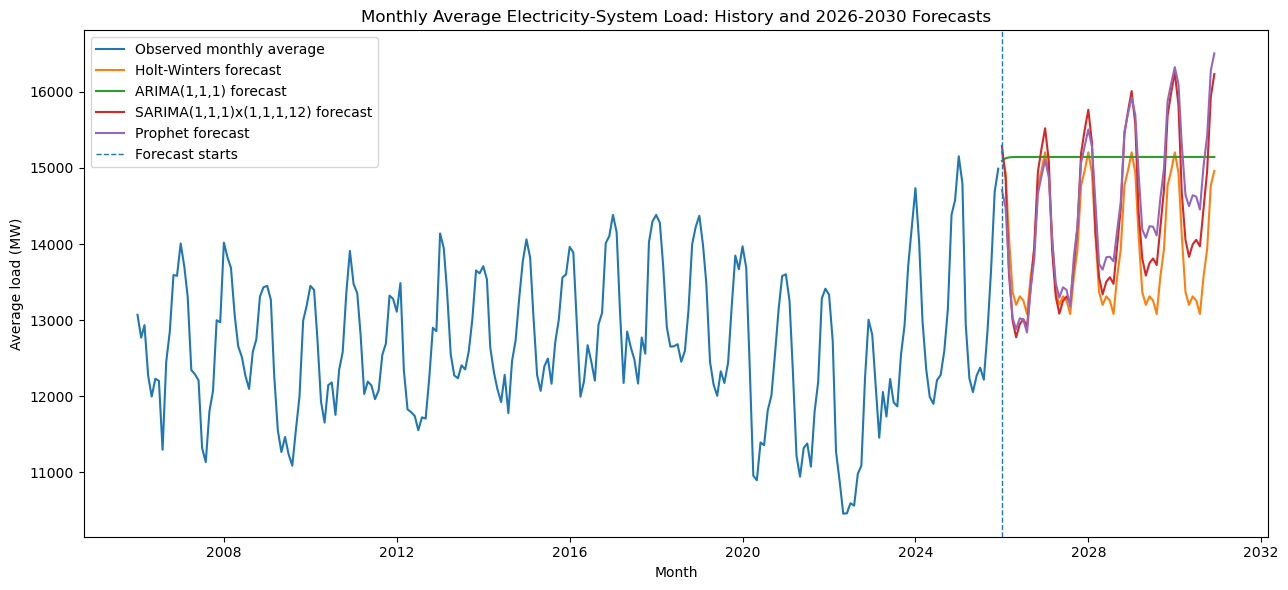

In [71]:
# Plot monthly historical demand and 2026-2030 forecasts

plt.figure(figsize=(13, 6))

plt.plot(
    monthly_demand.index,
    monthly_demand.values,
    label="Observed monthly average",
    linewidth=1.5
)

for model_name, prediction in monthly_classical_future.items():
    prediction = pd.Series(prediction)

    plt.plot(
        prediction.index,
        prediction.values,
        label=f"{model_name} forecast"
    )

plt.axvline(
    pd.Timestamp("2026-01-01"),
    linestyle="--",
    linewidth=1,
    label="Forecast starts"
)

plt.title(
    "Monthly Average Electricity-System Load: "
    "History and 2026-2030 Forecasts"
)
plt.xlabel("Month")
plt.ylabel("Average load (MW)")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Final objective: Forecast electricity demand through 2030

The next stage is to develop a forecasting approach that can estimate electricity demand in 2030 using the selected XGBoost model as a starting point.

The current model predicts demand one hour ahead using recent observed demand. For a forecast extending to 2030, actual future demand values will not be available to calculate the lag features. Therefore, we must decide how to generate future predictions without relying on observations that do not yet exist.

The next steps are:

1. **Review the final model and its limitations.** Confirm the selected features, hyperparameters and 2025 test performance.
2. **Define the long-term forecasting method.** Determine how future lag features will be generated and whether recursive hourly predictions are appropriate.
3. **Generate predictions for the required future period.** Extend the forecasting process from the end of 2025 to 2030, clearly documenting its assumptions and limitations.
4. **Calculate the 2030 annual average demand.** Aggregate the predicted hourly demand values for 2030 and report the result in MW.
5. **Interpret the forecast cautiously.** Explain that a long-term forecast based on historical demand patterns alone may not capture structural changes, economic growth, electrification, weather trends or energy-policy developments.

The final output will be an estimated annual average electricity demand for the Netherlands in 2030, accompanied by a clear explanation of the methodology, assumptions and limitations.

In [72]:
# Check that the data and model are ready for long-term forecasting

print("Last timestamp in dataset:", df["Timestamp"].max())
print("Number of records in 2025:", (df["Timestamp"].dt.year == 2025).sum())

print("\nLast 336 hours of demand:")
print("Number of records:", len(df.tail(336)))
print("Missing demand values:", df.tail(336)["Demand_MW"].isna().sum())

print("\nModel training data:")
print("Last training timestamp:", train_df_expanded["Timestamp"].max())
print("Number of training records:", len(train_df_expanded))

print("\nForecast horizon:")
print("Forecast start: 2030 is the target year; forecasting starts after 2025.")
print("Hours in 2030:", len(pd.date_range(
    start="2030-01-01 00:00:00",
    end="2030-12-31 23:00:00",
    freq="h"
)))

Last timestamp in dataset: 2025-12-31 23:00:00
Number of records in 2025: 8760

Last 336 hours of demand:
Number of records: 336
Missing demand values: 0

Model training data:
Last training timestamp: 2024-12-31 23:00:00
Number of training records: 164524

Forecast horizon:
Forecast start: 2030 is the target year; forecasting starts after 2025.
Hours in 2030: 8760


In [73]:
# Prepare the final XGBoost model for forecasting beyond 2025

forecast_train_df = expanded_model_df.copy()

X_forecast_train = forecast_train_df[expanded_feature_columns]
y_forecast_train = forecast_train_df["Demand_MW"]

final_forecast_model = XGBRegressor(
    objective="reg:squarederror",
    **xgb_tuning.best_params_,
    random_state=SEED,
    n_jobs=-1
)

final_forecast_model.fit(X_forecast_train, y_forecast_train)

print("Final forecasting model trained successfully.")
print("Training records:", len(X_forecast_train))
print("First training timestamp:", forecast_train_df["Timestamp"].min())
print("Last training timestamp:", forecast_train_df["Timestamp"].max())
print("Number of features:", len(expanded_feature_columns))
print("Selected parameters:", xgb_tuning.best_params_)

Final forecasting model trained successfully.
Training records: 173284
First training timestamp: 2006-01-15 00:00:00
Last training timestamp: 2025-12-31 23:00:00
Number of features: 13
Selected parameters: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 700, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


In [74]:
# Create hourly timestamps from the start of 2026 through the end of 2030

future_timestamps = pd.date_range(
    start="2026-01-01 00:00:00",
    end="2030-12-31 23:00:00",
    freq="h"
)

print("Forecast start:", future_timestamps.min())
print("Forecast end:", future_timestamps.max())
print("Total future hours:", len(future_timestamps))
print("Hours in 2030:", (future_timestamps.year == 2030).sum())
print("Missing timestamps:", future_timestamps.isna().sum())

Forecast start: 2026-01-01 00:00:00
Forecast end: 2030-12-31 23:00:00
Total future hours: 43824
Hours in 2030: 8760
Missing timestamps: 0


In [75]:
# Create a separate demand history for recursive forecasting

forecast_history = df.set_index("Timestamp")["Demand_MW"].copy()

print("Historical demand records:", len(forecast_history))
print("First timestamp:", forecast_history.index.min())
print("Last timestamp:", forecast_history.index.max())
print("Missing historical demand values:", forecast_history.isna().sum())
print("History ends at the expected timestamp:",
      forecast_history.index.max() == pd.Timestamp("2025-12-31 23:00:00"))

Historical demand records: 175320
First timestamp: 2006-01-01 00:00:00
Last timestamp: 2025-12-31 23:00:00
Missing historical demand values: 10
History ends at the expected timestamp: True


In [76]:
# Prepare a continuous demand history for recursive forecasting

forecast_history = (
    forecast_history
    .sort_index()
    .interpolate(method="time", limit_area="inside")
)

print("Missing values after interpolation:", forecast_history.isna().sum())
print("Historical records:", len(forecast_history))
print("First timestamp:", forecast_history.index.min())
print("Last timestamp:", forecast_history.index.max())
print("All demand values finite:", np.isfinite(forecast_history).all())

Missing values after interpolation: 0
Historical records: 175320
First timestamp: 2006-01-01 00:00:00
Last timestamp: 2025-12-31 23:00:00
All demand values finite: True


In [77]:
# Build the expanded features for the first forecast hour

next_timestamp = pd.Timestamp("2026-01-01 00:00:00")

forecast_features = pd.DataFrame(
    [{
        "Lag_1h": forecast_history.loc[next_timestamp - pd.Timedelta(hours=1)],
        "Lag_2h": forecast_history.loc[next_timestamp - pd.Timedelta(hours=2)],
        "Lag_24h": forecast_history.loc[next_timestamp - pd.Timedelta(hours=24)],
        "Lag_48h": forecast_history.loc[next_timestamp - pd.Timedelta(hours=48)],
        "Lag_168h": forecast_history.loc[next_timestamp - pd.Timedelta(hours=168)],
        "Lag_336h": forecast_history.loc[next_timestamp - pd.Timedelta(hours=336)],
        "Rolling_Mean_24h": forecast_history.loc[
            next_timestamp - pd.Timedelta(hours=24):
            next_timestamp - pd.Timedelta(hours=1)
        ].mean(),
        "Rolling_Mean_168h": forecast_history.loc[
            next_timestamp - pd.Timedelta(hours=168):
            next_timestamp - pd.Timedelta(hours=1)
        ].mean(),
        "Hour": next_timestamp.hour,
        "DayOfWeek": next_timestamp.dayofweek,
        "Month": next_timestamp.month,
        "DayOfYear": next_timestamp.dayofyear,
        "IsWeekend": int(next_timestamp.dayofweek >= 5)
    }],
    columns=expanded_feature_columns
)

print("Forecast timestamp:", next_timestamp)
print("Feature shape:", forecast_features.shape)
print("Feature columns match training:",
      list(forecast_features.columns) == expanded_feature_columns)
print("Missing feature values:", forecast_features.isna().sum().sum())

display(forecast_features.round(2))

Forecast timestamp: 2026-01-01 00:00:00
Feature shape: (1, 13)
Feature columns match training: True
Missing feature values: 0


,Lag_1h,Lag_2h,Lag_24h,Lag_48h,Lag_168h,Lag_336h,Rolling_Mean_24h,Rolling_Mean_168h,Hour,DayOfWeek,Month,DayOfYear,IsWeekend
0,12769.99,13008.82,12833.4,12710.27,13067.88,12863.08,14621.8,14579.4,0,3,1,1,0


In [78]:
# Recursively forecast hourly electricity demand from 2026 through 2030

future_predictions = []

for timestamp in tqdm(future_timestamps, desc="Forecasting hourly demand", unit="hour"):
    # Build lag features using observed demand and previous predictions
    features = {
        "Lag_1h": forecast_history.loc[timestamp - pd.Timedelta(hours=1)],
        "Lag_2h": forecast_history.loc[timestamp - pd.Timedelta(hours=2)],
        "Lag_24h": forecast_history.loc[timestamp - pd.Timedelta(hours=24)],
        "Lag_48h": forecast_history.loc[timestamp - pd.Timedelta(hours=48)],
        "Lag_168h": forecast_history.loc[timestamp - pd.Timedelta(hours=168)],
        "Lag_336h": forecast_history.loc[timestamp - pd.Timedelta(hours=336)],
        "Rolling_Mean_24h": forecast_history.loc[
            timestamp - pd.Timedelta(hours=24):
            timestamp - pd.Timedelta(hours=1)
        ].mean(),
        "Rolling_Mean_168h": forecast_history.loc[
            timestamp - pd.Timedelta(hours=168):
            timestamp - pd.Timedelta(hours=1)
        ].mean(),
        "Hour": timestamp.hour,
        "DayOfWeek": timestamp.dayofweek,
        "Month": timestamp.month,
        "DayOfYear": timestamp.dayofyear,
        "IsWeekend": int(timestamp.dayofweek >= 5)
    }

    X_next = pd.DataFrame([features], columns=expanded_feature_columns)
    prediction = final_forecast_model.predict(X_next)[0]

    # Store the prediction for use in later hours
    forecast_history.loc[timestamp] = prediction

    future_predictions.append({
        "Timestamp": timestamp,
        "Predicted_Demand_MW": prediction
    })

forecast_df = pd.DataFrame(future_predictions)

print("\nForecast completed.")
print("Number of predictions:", len(forecast_df))
print("Missing predictions:", forecast_df["Predicted_Demand_MW"].isna().sum())
print("Minimum predicted demand (MW):",
      round(forecast_df["Predicted_Demand_MW"].min(), 2))
print("Maximum predicted demand (MW):",
      round(forecast_df["Predicted_Demand_MW"].max(), 2))

Forecasting hourly demand:   0%|          | 0/43824 [00:00<?, ?hour/s]


Forecast completed.
Number of predictions: 43824
Missing predictions: 0
Minimum predicted demand (MW): 8542.64
Maximum predicted demand (MW): 19543.91


### Inspecting the Final 21 Days of the 2030 Electricity Demand Forecast

This section examines the final 21 days of the 2030 hourly electricity demand forecast. It calculates daily average predicted demand and displays the final 48 hourly predictions.

The purpose is to check that the forecast extends to the end of December 2030 and that the predicted demand values are available for the final days of the year. This is a diagnostic check only; it does not change the forecasting model or its predictions.

In [159]:
# Inspect the final 21 days of the 2030 forecast

forecast_check = forecast_2030.copy()

# Ensure timestamps use datetime format
forecast_check["Timestamp"] = pd.to_datetime(
    forecast_check["Timestamp"],
    errors="coerce"
)

# Remove rows with invalid timestamps
forecast_check = forecast_check.dropna(
    subset=["Timestamp"]
).sort_values("Timestamp")

# Select the final 21 days of 2030
end_period = forecast_check[
    forecast_check["Timestamp"] >= pd.Timestamp("2030-12-11")
].copy()

# Display forecast coverage
print("Forecast starts:", forecast_check["Timestamp"].min())
print("Forecast ends:", forecast_check["Timestamp"].max())
print("Rows in final period:", len(end_period))

# Calculate daily average predicted demand
daily_average = (
    end_period
    .set_index("Timestamp")["Predicted_Demand_MW"]
    .resample("D")
    .mean()
)

print("\nDaily average demand — final days of 2030 (MW):")
display(daily_average.round(2).to_frame("Average_Demand_MW"))

# Display the final 48 hourly predictions
print("\nFinal 48 hourly predictions:")
display(
    end_period[
        ["Timestamp", "Predicted_Demand_MW"]
    ].tail(48).round(2)
)

Forecast starts: 2030-01-01 00:00:00
Forecast ends: 2030-12-31 23:00:00
Rows in final period: 504

Daily average demand — final days of 2030 (MW):


,Average_Demand_MW
Timestamp,
2030-12-11,13653.139648
2030-12-12,13666.900391
2030-12-13,13514.280273
2030-12-14,12163.549805
2030-12-15,11567.919922
2030-12-16,13429.809570
2030-12-17,13438.919922
2030-12-18,13395.769531
2030-12-19,13263.919922



Final 48 hourly predictions:


,Timestamp,Predicted_Demand_MW
43776,2030-12-30 00:00:00,9628.389648
43777,2030-12-30 01:00:00,9273.030273
43778,2030-12-30 02:00:00,9105.330078
43779,2030-12-30 03:00:00,9124.049805
43780,2030-12-30 04:00:00,9284.019531
43781,2030-12-30 05:00:00,9727.219727
43782,2030-12-30 06:00:00,10677.309570
43783,2030-12-30 07:00:00,11790.660156
43784,2030-12-30 08:00:00,12711.040039
43785,2030-12-30 09:00:00,13052.730469


In [137]:

# Compare December 2025 with December 2030

dec_2025_values = daily_2025.dropna()
dec_2030_values = daily_2030.dropna()

print("December 2025 — actual demand")
print("Average:", round(dec_2025_values.mean(), 2), "MW")
print("Minimum daily average:", round(dec_2025_values.min(), 2), "MW")
print("Maximum daily average:", round(dec_2025_values.max(), 2), "MW")

print("\nDecember 2030 — predicted demand")
print("Average:", round(dec_2030_values.mean(), 2), "MW")
print("Minimum daily average:", round(dec_2030_values.min(), 2), "MW")
print("Maximum daily average:", round(dec_2030_values.max(), 2), "MW")

print("\nDifference in monthly average:")
print(round(dec_2030_values.mean() - dec_2025_values.mean(), 2), "MW")


December 2025 — actual demand
Average: 14990.21 MW
Minimum daily average: 13276.85 MW
Maximum daily average: 16084.46 MW

December 2030 — predicted demand
Average: 12513.52 MW
Minimum daily average: 10835.34 MW
Maximum daily average: 13666.9 MW

Difference in monthly average:
-2476.69 MW


In [138]:
check = forecast_2025.dropna(
    subset=["Actual_Demand_MW", "Predicted_Demand_MW"]
).copy()

actual = check["Actual_Demand_MW"]
predicted = check["Predicted_Demand_MW"]

print("2025 actual average:", round(actual.mean(), 2), "MW")
print("2025 predicted average:", round(predicted.mean(), 2), "MW")
print("Average prediction bias:", round((predicted - actual).mean(), 2), "MW")
print("MAE:", round(mean_absolute_error(actual, predicted), 2), "MW")
print("RMSE:", round(np.sqrt(mean_squared_error(actual, predicted)), 2), "MW")


2025 actual average: 13345.21 MW
2025 predicted average: 13333.26 MW
Average prediction bias: -11.95 MW
MAE: 147.39 MW
RMSE: 198.91 MW


### Diagnostic Check and Next Steps

The output shows the daily average predicted electricity demand during the final part of December 2030 and the final 48 hourly predictions.

These results help verify the forecast's end date and inspect its final values. They do not, on their own, establish whether the forecast is accurate.

**Next decision:** We will check the annual average demand for 2030 and compare the recursive hourly XGBoost forecast with the annual Linear Regression estimate and the recent historical average baseline. We will then decide which forecast result or scenario is most appropriate to present in Power BI, while keeping the existing dashboard visuals unchanged unless a change is justified.

### Calculating the Annual Average Electricity Demand Forecast for 2030

This section extracts the hourly electricity demand predictions for 2030 from the full forecast dataset. It calculates the annual average, minimum, and maximum predicted demand in megawatts (MW).

These summary statistics help us understand the expected level and range of electricity demand in 2030. They will also be used to compare the hourly XGBoost forecast with the annual Linear Regression forecast and the recent historical average baseline.

This calculation summarizes the existing forecast; it does not retrain or modify the model.

In [79]:
# Calculate the annual average predicted electricity demand for 2030

forecast_df["Timestamp"] = pd.to_datetime(forecast_df["Timestamp"])

forecast_2030 = forecast_df[
    forecast_df["Timestamp"].dt.year == 2030
].copy()

average_demand_2030 = forecast_2030["Predicted_Demand_MW"].mean()

print("Forecast year: 2030")
print("Number of hourly predictions:", len(forecast_2030))
print("Annual average predicted demand (MW):",
      round(average_demand_2030, 2))
print("Minimum hourly predicted demand (MW):",
      round(forecast_2030["Predicted_Demand_MW"].min(), 2))
print("Maximum hourly predicted demand (MW):",
      round(forecast_2030["Predicted_Demand_MW"].max(), 2))

Forecast year: 2030
Number of hourly predictions: 8760
Annual average predicted demand (MW): 11875.98
Minimum hourly predicted demand (MW): 8765.07
Maximum hourly predicted demand (MW): 15948.15


### Interpretation and Next Steps

The output provides three summary statistics for the 2030 hourly demand forecast: the annual average, the minimum hourly prediction, and the maximum hourly prediction.

The annual average represents the mean predicted electricity demand across the forecast hours in 2030. The minimum and maximum show the range of hourly predictions, rather than the range of daily or monthly averages.

**Next step:** Compare this annual average with the annual Linear Regression estimate and the recent historical average baseline. We will use the comparison and historical backtest errors to assess the forecast's reliability before deciding which figures to present in Power BI.

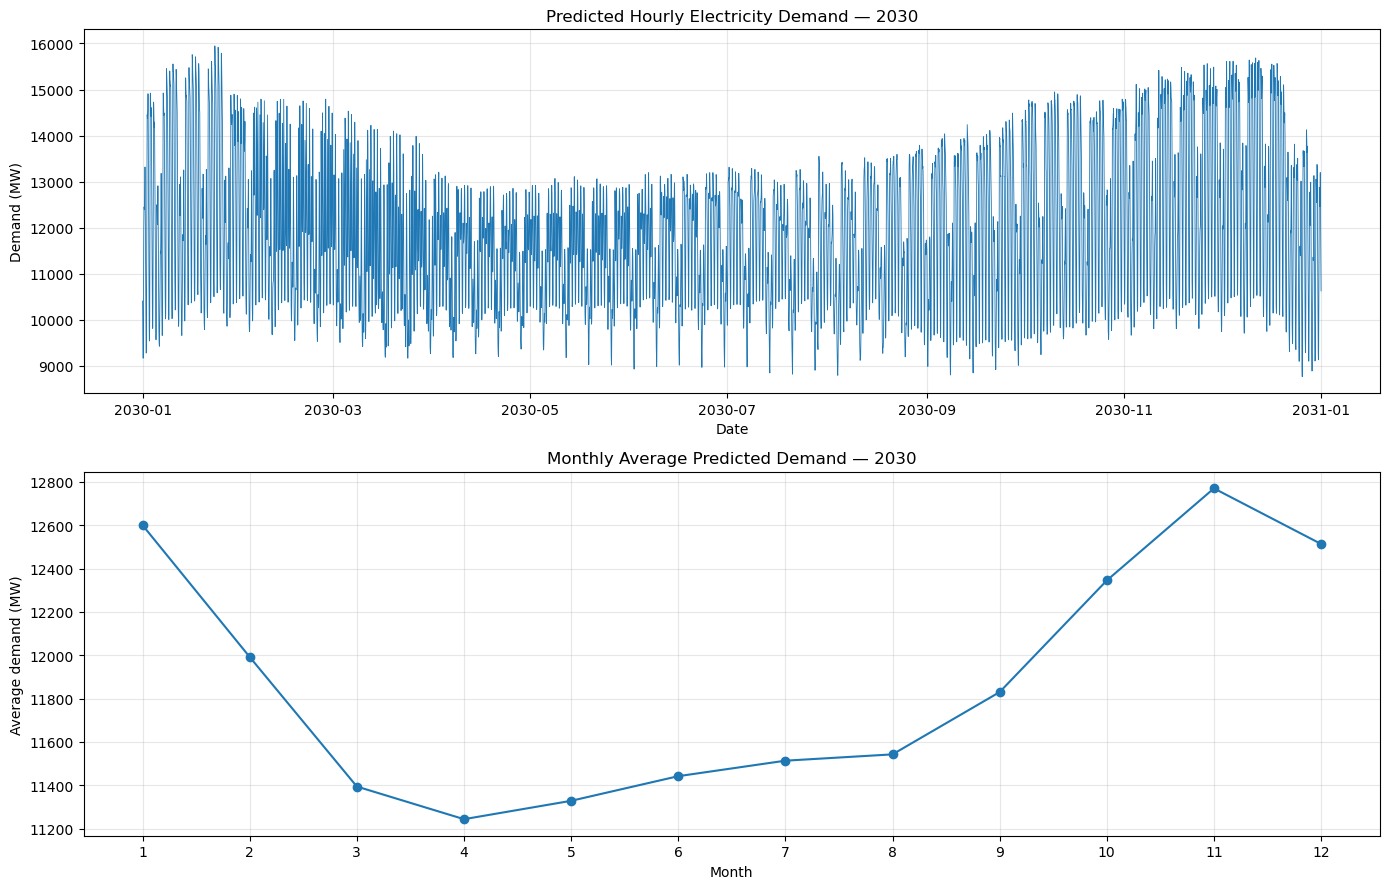

In [80]:
# Visualize hourly and monthly-average predicted demand for 2030

forecast_2030 = forecast_2030.sort_values("Timestamp").copy()

forecast_2030["Month"] = forecast_2030["Timestamp"].dt.month

monthly_average_2030 = (
    forecast_2030
    .groupby("Month")["Predicted_Demand_MW"]
    .mean()
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Hourly demand throughout 2030
axes[0].plot(
    forecast_2030["Timestamp"],
    forecast_2030["Predicted_Demand_MW"],
    linewidth=0.6
)
axes[0].set_title("Predicted Hourly Electricity Demand — 2030")
axes[0].set_ylabel("Demand (MW)")
axes[0].set_xlabel("Date")
axes[0].grid(True, alpha=0.3)

# Monthly average demand
axes[1].plot(
    monthly_average_2030.index,
    monthly_average_2030.values,
    marker="o"
)
axes[1].set_title("Monthly Average Predicted Demand — 2030")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Average demand (MW)")
axes[1].set_xticks(range(1, 13))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

,Historical Average (MW),2030 Forecast Average (MW)
Month,,
1,13859.66,12600.110352
2,13602.26,11991.969727
3,12794.91,11394.299805
4,12069.34,11243.679688
5,11910.22,11328.429688
6,12027.34,11442.139648
7,11984.81,11513.599609
8,11814.11,11542.750000
9,12315.29,11830.200195


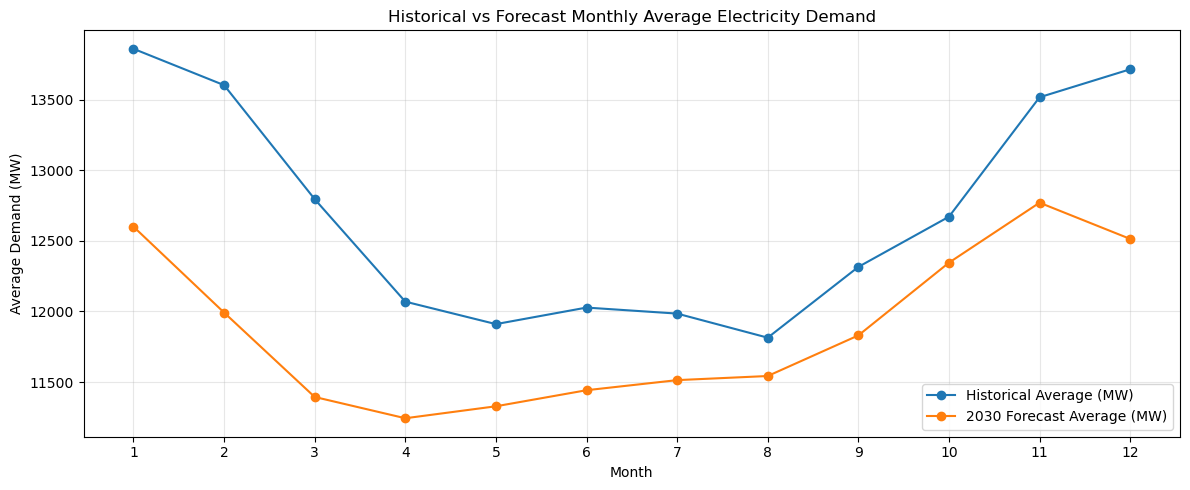

In [81]:
# Compare historical and forecast monthly average demand

historical_monthly = (
    df.assign(Month=df["Timestamp"].dt.month)
      .groupby("Month")["Demand_MW"]
      .mean()
)

forecast_monthly = (
    forecast_2030.assign(Month=forecast_2030["Timestamp"].dt.month)
                 .groupby("Month")["Predicted_Demand_MW"]
                 .mean()
)

monthly_comparison = pd.DataFrame({
    "Historical Average (MW)": historical_monthly,
    "2030 Forecast Average (MW)": forecast_monthly
})

display(monthly_comparison.round(2))

monthly_comparison.plot(
    kind="line",
    marker="o",
    figsize=(12, 5)
)

plt.title("Historical vs Forecast Monthly Average Electricity Demand")
plt.xlabel("Month")
plt.ylabel("Average Demand (MW)")
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

,Year,Average_Demand_MW
0,2015,12928.45
1,2016,13038.55
2,2017,13130.17
3,2018,13301.75
4,2019,13002.40
5,2020,12311.84
6,2021,12144.60
7,2022,11459.63
8,2023,12465.18
9,2024,13096.97


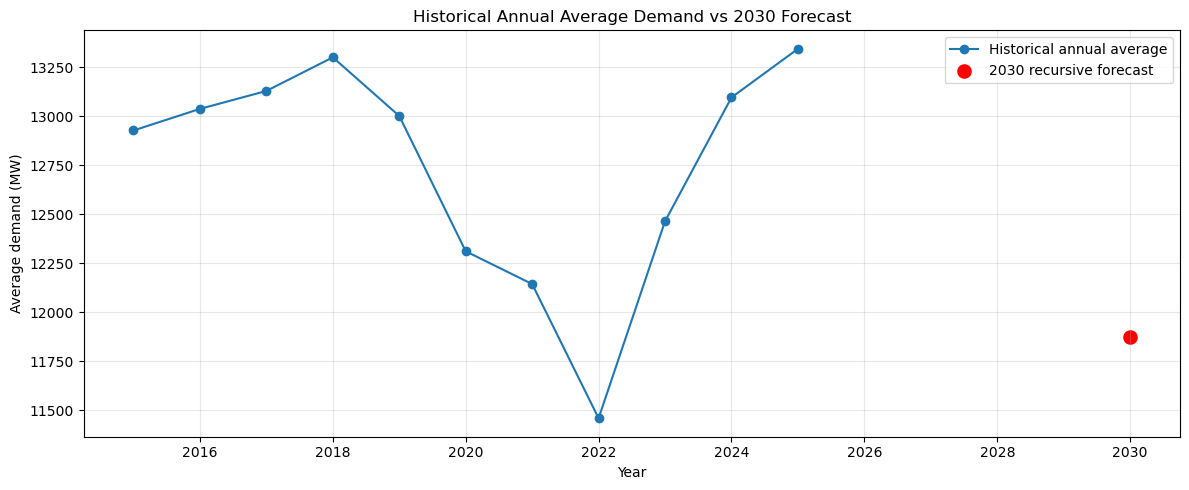

In [82]:
# Compare historical annual average demand with the 2030 forecast

historical_annual = (
    df.assign(Year=df["Timestamp"].dt.year)
      .groupby("Year")["Demand_MW"]
      .mean()
      .reset_index(name="Average_Demand_MW")
)

forecast_2030_annual = pd.DataFrame({
    "Year": [2030],
    "Average_Demand_MW": [average_demand_2030]
})

annual_comparison = pd.concat(
    [
        historical_annual[historical_annual["Year"] >= 2015],
        forecast_2030_annual
    ],
    ignore_index=True
)

display(annual_comparison.round(2))

plt.figure(figsize=(12, 5))

plt.plot(
    historical_annual.loc[historical_annual["Year"] >= 2015, "Year"],
    historical_annual.loc[historical_annual["Year"] >= 2015, "Average_Demand_MW"],
    marker="o",
    label="Historical annual average"
)

plt.scatter(
    [2030],
    [average_demand_2030],
    color="red",
    s=90,
    label="2030 recursive forecast"
)

plt.title("Historical Annual Average Demand vs 2030 Forecast")
plt.xlabel("Year")
plt.ylabel("Average demand (MW)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

,Year,Annual_Average_MW,Minimum_MW,Maximum_MW
0,2026,13161.219727,8542.639648,19543.910156
1,2027,11940.580078,8734.490234,16634.500000
2,2028,11905.990234,8744.290039,16696.019531
3,2029,11945.349609,8763.059570,16124.259766
4,2030,11875.980469,8765.070312,15948.139648


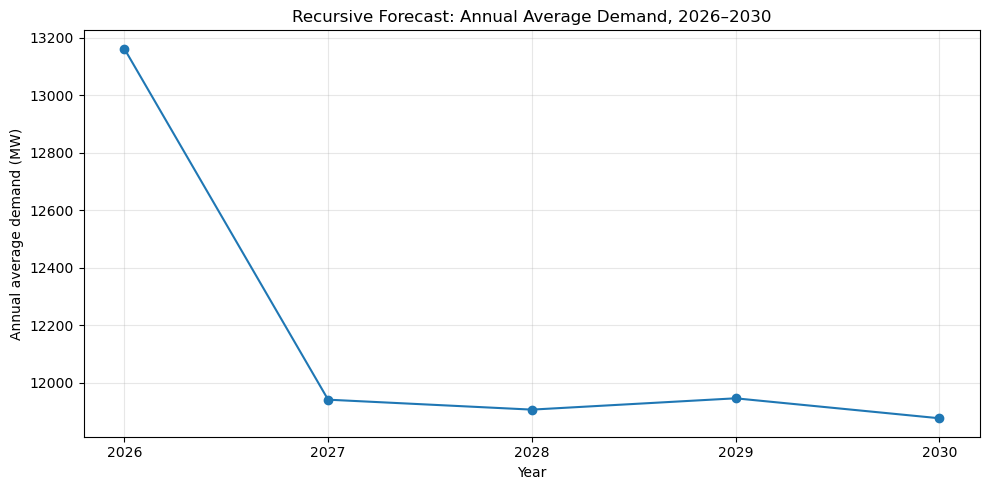

In [83]:
# Examine how the recursive forecast changes year by year

forecast_df["Year"] = forecast_df["Timestamp"].dt.year

forecast_annual = (
    forecast_df
    .groupby("Year")["Predicted_Demand_MW"]
    .agg(
        Annual_Average_MW="mean",
        Minimum_MW="min",
        Maximum_MW="max"
    )
    .reset_index()
)

display(forecast_annual.round(2))

plt.figure(figsize=(10, 5))
plt.plot(
    forecast_annual["Year"],
    forecast_annual["Annual_Average_MW"],
    marker="o"
)
plt.title("Recursive Forecast: Annual Average Demand, 2026–2030")
plt.xlabel("Year")
plt.ylabel("Annual average demand (MW)")
plt.xticks(forecast_annual["Year"])
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Interpretation of the Recursive Forecast for 2030

The selected XGBoost model was retrained using historical data from 2006 to 2025 and used to generate hourly electricity-demand predictions from 2026 through 2030. The recursive forecasting process generated 43,824 hourly predictions, including 8,760 predictions for 2030.

The predicted annual average electricity demand for the Netherlands in 2030 is **11,875.98 MW**. The predicted hourly demand in 2030 ranges from approximately 8,765 MW to 15,948 MW.

The monthly averages show a seasonal pattern, with higher predicted demand during the winter months and lower demand during spring and summer. However, the forecasted monthly averages are below the historical monthly averages for every month.

The annual results also reveal a sharp decrease in predicted average demand between 2026 and 2027, from approximately 13,161 MW to 11,941 MW. The forecast then remains relatively stable, with annual averages close to 11,900 MW through 2030.

This behaviour raises concerns about the reliability of the long-term forecast. The model was evaluated successfully for one-hour-ahead predictions, where actual historical demand was available to calculate lag features. In contrast, the recursive forecast uses its own predictions to construct future lag features. Prediction errors can therefore accumulate, and the model may develop patterns that do not reflect actual future electricity demand.

Consequently, the estimate of 11,875.98 MW should currently be treated as an **exploratory model output rather than a validated forecast for 2030**. Further testing is required before drawing conclusions about future electricity demand.

## Next Approach: Backtesting the Recursive Forecasting Method

The recursive forecast shows a sharp decline between 2026 and 2027, followed by relatively stable annual averages. This raises the question of whether the model can reliably forecast multiple years ahead when actual demand is unavailable.

To investigate this issue, the next step is to perform a historical recursive backtest. This will simulate how the model would have performed if only historical data through 2019 had been available.

The backtesting procedure will be:

1. **Train a separate XGBoost model** using historical data up to 31 December 2019.
2. **Generate recursive hourly predictions** from 1 January 2020 through 31 December 2025, using previous predictions to construct future lag and rolling-average features.
3. **Compare predicted and actual demand** for each year from 2020 to 2025, including annual average demand and prediction errors.
4. **Inspect the forecast behaviour** to determine whether the model exhibits unrealistic declines, drift or loss of seasonal patterns over longer forecast horizons.
5. **Reassess the 2030 forecasting approach** based on the backtesting results.

This experiment will provide evidence about how the recursive forecasting method behaves over a multi-year period. It will help determine whether the current XGBoost approach is suitable for estimating annual average electricity demand in 2030 or whether an alternative approach should be considered.

The backtest will not guarantee future accuracy, because historical conditions may differ from those in the future. However, it will provide a more appropriate evaluation of long-horizon forecasting behaviour than one-hour-ahead test metrics alone.

In [84]:
# Prepare data for a recursive backtest of 2020–2025

backtest_start = pd.Timestamp("2020-01-01 00:00:00")
backtest_end = pd.Timestamp("2025-12-31 23:00:00")

# Training data: everything before 2020
backtest_train_df = expanded_model_df[
    expanded_model_df["Timestamp"] < backtest_start
].copy()

# Evaluation data: 2020 through 2025
backtest_test_df = expanded_model_df[
    (expanded_model_df["Timestamp"] >= backtest_start) &
    (expanded_model_df["Timestamp"] <= backtest_end)
].copy()

print("Training records:", len(backtest_train_df))
print("Training starts:", backtest_train_df["Timestamp"].min())
print("Training ends:", backtest_train_df["Timestamp"].max())

print("\nBacktest records:", len(backtest_test_df))
print("Backtest starts:", backtest_test_df["Timestamp"].min())
print("Backtest ends:", backtest_test_df["Timestamp"].max())

print("\nMissing training feature values:",
      backtest_train_df[expanded_feature_columns].isna().sum().sum())
print("Missing actual demand values:",
      backtest_test_df["Demand_MW"].isna().sum())

Training records: 120676
Training starts: 2006-01-15 00:00:00
Training ends: 2019-12-31 23:00:00

Backtest records: 52608
Backtest starts: 2020-01-01 00:00:00
Backtest ends: 2025-12-31 23:00:00

Missing training feature values: 0
Missing actual demand values: 0


In [85]:
# Train a separate XGBoost model for recursive backtesting

backtest_model = XGBRegressor(
    objective="reg:squarederror",
    **xgb_tuning.best_params_,
    random_state=SEED,
    n_jobs=-1
)

X_backtest_train = backtest_train_df[expanded_feature_columns]
y_backtest_train = backtest_train_df["Demand_MW"]

backtest_model.fit(X_backtest_train, y_backtest_train)

print("Backtesting model trained successfully.")
print("Training records:", len(X_backtest_train))
print("Training ends:", backtest_train_df["Timestamp"].max())
print("Number of features:", len(expanded_feature_columns))
print("Parameters:", xgb_tuning.best_params_)

Backtesting model trained successfully.
Training records: 120676
Training ends: 2019-12-31 23:00:00
Number of features: 13
Parameters: {'subsample': 0.8, 'reg_lambda': 1, 'reg_alpha': 1, 'n_estimators': 700, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.05, 'colsample_bytree': 0.9}


In [86]:
# Initialize the recursive backtest using data available through 2019

backtest_history = (
    df.loc[df["Timestamp"] < pd.Timestamp("2020-01-01 00:00:00"),
           ["Timestamp", "Demand_MW"]]
    .sort_values("Timestamp")
    .set_index("Timestamp")["Demand_MW"]
    .copy()
)

# Fill any missing historical values using time interpolation
backtest_history = backtest_history.interpolate(
    method="time",
    limit_area="inside"
)

print("Historical records:", len(backtest_history))
print("First timestamp:", backtest_history.index.min())
print("Last timestamp:", backtest_history.index.max())
print("Missing values:", backtest_history.isna().sum())
print(
    "History ends on 31 December 2019:",
    backtest_history.index.max()
    == pd.Timestamp("2019-12-31 23:00:00")
)

Historical records: 122712
First timestamp: 2006-01-01 00:00:00
Last timestamp: 2019-12-31 23:00:00
Missing values: 0
History ends on 31 December 2019: True


In [87]:
# Recursively forecast hourly demand from 2020 through 2025

backtest_timestamps = pd.date_range(
    start="2020-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

backtest_predictions = []

for timestamp in tqdm(
    backtest_timestamps,
    desc="Recursive backtest",
    unit="hour"
):
    features = {
        "Lag_1h": backtest_history.loc[
            timestamp - pd.Timedelta(hours=1)
        ],
        "Lag_2h": backtest_history.loc[
            timestamp - pd.Timedelta(hours=2)
        ],
        "Lag_24h": backtest_history.loc[
            timestamp - pd.Timedelta(hours=24)
        ],
        "Lag_48h": backtest_history.loc[
            timestamp - pd.Timedelta(hours=48)
        ],
        "Lag_168h": backtest_history.loc[
            timestamp - pd.Timedelta(hours=168)
        ],
        "Lag_336h": backtest_history.loc[
            timestamp - pd.Timedelta(hours=336)
        ],
        "Rolling_Mean_24h": backtest_history.loc[
            timestamp - pd.Timedelta(hours=24):
            timestamp - pd.Timedelta(hours=1)
        ].mean(),
        "Rolling_Mean_168h": backtest_history.loc[
            timestamp - pd.Timedelta(hours=168):
            timestamp - pd.Timedelta(hours=1)
        ].mean(),
        "Hour": timestamp.hour,
        "DayOfWeek": timestamp.dayofweek,
        "Month": timestamp.month,
        "DayOfYear": timestamp.dayofyear,
        "IsWeekend": int(timestamp.dayofweek >= 5)
    }

    X_next = pd.DataFrame(
        [features],
        columns=expanded_feature_columns
    )

    prediction = backtest_model.predict(X_next)[0]

    # Append the prediction, not actual demand, to the history
    backtest_history.loc[timestamp] = prediction

    backtest_predictions.append({
        "Timestamp": timestamp,
        "Predicted_Demand_MW": prediction
    })

backtest_forecast_df = pd.DataFrame(backtest_predictions)

print("\nBacktest forecasting completed.")
print("Number of predictions:", len(backtest_forecast_df))
print(
    "Missing predictions:",
    backtest_forecast_df["Predicted_Demand_MW"].isna().sum()
)
print(
    "Minimum predicted demand (MW):",
    round(backtest_forecast_df["Predicted_Demand_MW"].min(), 2)
)
print(
    "Maximum predicted demand (MW):",
    round(backtest_forecast_df["Predicted_Demand_MW"].max(), 2)
)

Recursive backtest:   0%|          | 0/52608 [00:00<?, ?hour/s]


Backtest forecasting completed.
Number of predictions: 52608
Missing predictions: 0
Minimum predicted demand (MW): 7357.66
Maximum predicted demand (MW): 17785.92


,Actual_Average_MW,Predicted_Average_MW,Difference_MW,Absolute_Error_MW
Year,,,,
2020,12311.84,12642.639648,330.80,330.80
2021,12144.60,11717.589844,-427.01,427.01
2022,11459.63,12043.830078,584.21,584.21
2023,12465.18,12160.320312,-304.87,304.87
2024,13096.97,11785.969727,-1311.00,1311.00
2025,13345.21,11750.200195,-1595.01,1595.01


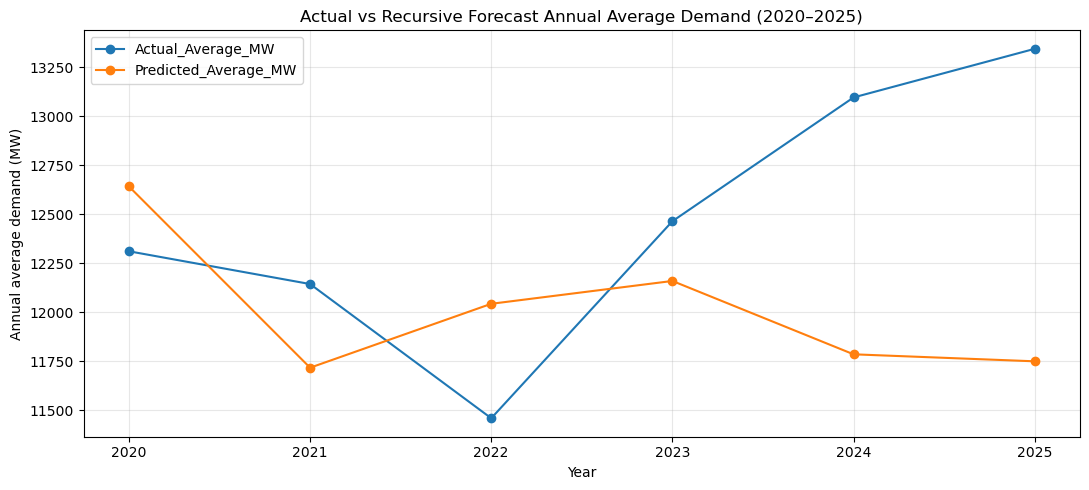

In [88]:
# Compare actual and recursively predicted annual average demand

actual_annual_backtest = (
    df.loc[df["Timestamp"].dt.year.between(2020, 2025)]
    .assign(Year=lambda x: x["Timestamp"].dt.year)
    .groupby("Year")["Demand_MW"]
    .mean()
    .rename("Actual_Average_MW")
)

predicted_annual_backtest = (
    backtest_forecast_df
    .assign(Year=lambda x: x["Timestamp"].dt.year)
    .groupby("Year")["Predicted_Demand_MW"]
    .mean()
    .rename("Predicted_Average_MW")
)

backtest_annual_comparison = pd.concat(
    [actual_annual_backtest, predicted_annual_backtest],
    axis=1
)

backtest_annual_comparison["Difference_MW"] = (
    backtest_annual_comparison["Predicted_Average_MW"]
    - backtest_annual_comparison["Actual_Average_MW"]
)

backtest_annual_comparison["Absolute_Error_MW"] = (
    backtest_annual_comparison["Difference_MW"].abs()
)

display(backtest_annual_comparison.round(2))

backtest_annual_comparison[
    ["Actual_Average_MW", "Predicted_Average_MW"]
].plot(
    kind="line",
    marker="o",
    figsize=(11, 5)
)

plt.title("Actual vs Recursive Forecast Annual Average Demand (2020–2025)")
plt.xlabel("Year")
plt.ylabel("Annual average demand (MW)")
plt.xticks(backtest_annual_comparison.index)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [89]:
# Evaluate errors in the annual-average backtest

annual_mae = mean_absolute_error(
    backtest_annual_comparison["Actual_Average_MW"],
    backtest_annual_comparison["Predicted_Average_MW"]
)

annual_rmse = np.sqrt(mean_squared_error(
    backtest_annual_comparison["Actual_Average_MW"],
    backtest_annual_comparison["Predicted_Average_MW"]
))

print("Annual-average backtest MAE:", round(annual_mae, 2), "MW")
print("Annual-average backtest RMSE:", round(annual_rmse, 2), "MW")
print(
    "Mean annual bias:",
    round(backtest_annual_comparison["Difference_MW"].mean(), 2),
    "MW"
)

Annual-average backtest MAE: 758.82 MW
Annual-average backtest RMSE: 911.85 MW
Mean annual bias: -453.81 MW


## Interpretation of Recursive Backtesting Results

A recursive backtest was conducted to evaluate the selected XGBoost model's ability to forecast electricity demand over multiple years. The model was trained using data through 2019 and generated hourly predictions for the period from 2020 to 2025. Actual demand from the evaluation period was not fed back into the model during forecasting.

The comparison of annual average demand showed that the model did not consistently reproduce the observed year-to-year changes. Although some annual predictions were relatively close to actual demand, the errors increased considerably in later years. In 2024, the model underestimated annual average demand by 1,311.00 MW, and in 2025 it underestimated demand by 1,595.01 MW.

The annual-average backtest metrics were:

- **MAE:** 758.82 MW
- **RMSE:** 911.85 MW
- **Mean annual bias:** −453.81 MW

The negative mean bias indicates that the model underestimated annual average demand overall during the backtest period. The results suggest that a model performing well in rolling one-hour-ahead prediction does not necessarily perform well when recursively forecasting several years into the future.

Consequently, the previously calculated 2030 annual average estimate of 11,875.98 MW should not be treated as a reliable forecast without further investigation. The recursive method appears to struggle with longer-term changes in electricity demand, particularly the recovery observed in 2023–2025.

## Next Approach: Reassessing the 2030 Forecast

The recursive backtest identified a limitation in the current forecasting method: prediction errors can accumulate when the model uses its own outputs to generate future lag features. The model also failed to capture the recovery in annual average demand observed in the later backtest years.

The next step is to investigate a less error-prone approach while retaining the machine-learning methods used in this project.

The proposed approach is:

1. **Review the forecasting objective.** Confirm that the target is annual average electricity demand in MW, rather than annual electricity consumption in MWh or TWh.
2. **Investigate alternative forecasting strategies.** Consider whether a model predicting annual average demand directly, using historical annual averages and a suitable set of time-based features, would be more appropriate for a long-term target.
3. **Evaluate the alternative using chronological backtesting.** Compare predicted and actual annual averages over historical periods that were not used for training.
4. **Compare the approaches.** Assess whether the alternative provides more reliable annual estimates than the recursive hourly model.
5. **Revisit the 2030 estimate.** Report the selected estimate together with its evaluation results, assumptions and limitations.

The goal is not simply to obtain a different 2030 number, but to select a forecasting method whose historical performance provides stronger evidence that its long-term estimates are meaningful.

Number of years: 20
First year: 2006
Last year: 2025


,Year,Annual_Average_Demand_MW
0,2006,12602.59
1,2007,12504.85
2,2008,13014.22
3,2009,12105.70
4,2010,12618.58
5,2011,12652.89
6,2012,12267.64
7,2013,13008.80
8,2014,12706.79
9,2015,12928.45


<function matplotlib.pyplot.ylabel(ylabel: 'str', fontdict: 'dict[str, Any] | None' = None, labelpad: 'float | None' = None, *, loc: "Literal['bottom', 'center', 'top'] | None" = None, **kwargs) -> 'Text'>

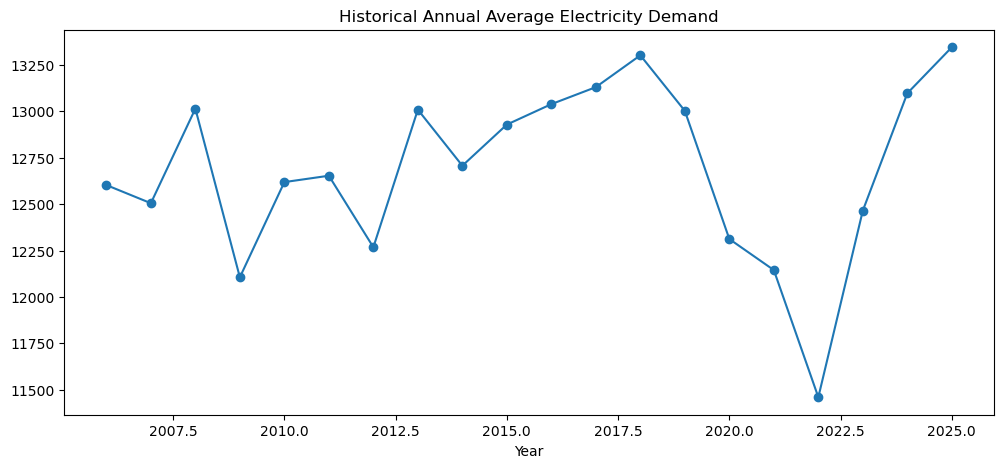

In [90]:
# Calculate annual average electricity demand

annual_demand_df = (
    df.assign(Year=df["Timestamp"].dt.year)
      .groupby("Year")["Demand_MW"]
      .mean()
      .reset_index()
      .rename(columns={"Demand_MW": "Annual_Average_Demand_MW"})
)

print("Number of years:", len(annual_demand_df))
print("First year:", annual_demand_df["Year"].min())
print("Last year:", annual_demand_df["Year"].max())

display(annual_demand_df.round(2))

# Plot the historical annual averages
plt.figure(figsize=(12, 5))
plt.plot(
    annual_demand_df["Year"],
    annual_demand_df["Annual_Average_Demand_MW"],
    marker="o"
)
plt.title("Historical Annual Average Electricity Demand")
plt.xlabel("Year")
plt.ylabel

In [91]:
# Prepare annual data for chronological evaluation

annual_train = annual_demand_df[
    annual_demand_df["Year"] < 2020
].copy()

annual_test = annual_demand_df[
    annual_demand_df["Year"] >= 2020
].copy()

X_annual_train = annual_train[["Year"]]
y_annual_train = annual_train["Annual_Average_Demand_MW"]

X_annual_test = annual_test[["Year"]]
y_annual_test = annual_test["Annual_Average_Demand_MW"]

print("Training years:",
      annual_train["Year"].min(), "to", annual_train["Year"].max())
print("Training observations:", len(annual_train))

print("\nEvaluation years:",
      annual_test["Year"].min(), "to", annual_test["Year"].max())
print("Evaluation observations:", len(annual_test))

Training years: 2006 to 2019
Training observations: 14

Evaluation years: 2020 to 2025
Evaluation observations: 6


In [92]:
# Train an annual Linear Regression model

annual_model = LinearRegression()
annual_model.fit(X_annual_train, y_annual_train)

# Predict annual average demand for 2020–2025
annual_test = annual_test.copy()
annual_test["Predicted_Demand_MW"] = annual_model.predict(
    X_annual_test
)

# Evaluate annual predictions
annual_lr_mae = mean_absolute_error(
    y_annual_test,
    annual_test["Predicted_Demand_MW"]
)

annual_lr_rmse = np.sqrt(mean_squared_error(
    y_annual_test,
    annual_test["Predicted_Demand_MW"]
))

print("Annual Linear Regression — Backtest Results")
print("MAE:", round(annual_lr_mae, 2), "MW")
print("RMSE:", round(annual_lr_rmse, 2), "MW")

display(
    annual_test[
        ["Year", "Annual_Average_Demand_MW", "Predicted_Demand_MW"]
    ].round(2)
)

Annual Linear Regression — Backtest Results
MAE: 834.05 MW
RMSE: 1004.76 MW


,Year,Annual_Average_Demand_MW,Predicted_Demand_MW
14,2020,12311.84,13172.81
15,2021,12144.60,13225.53
16,2022,11459.63,13278.26
17,2023,12465.18,13330.98
18,2024,13096.97,13383.70
19,2025,13345.21,13436.43


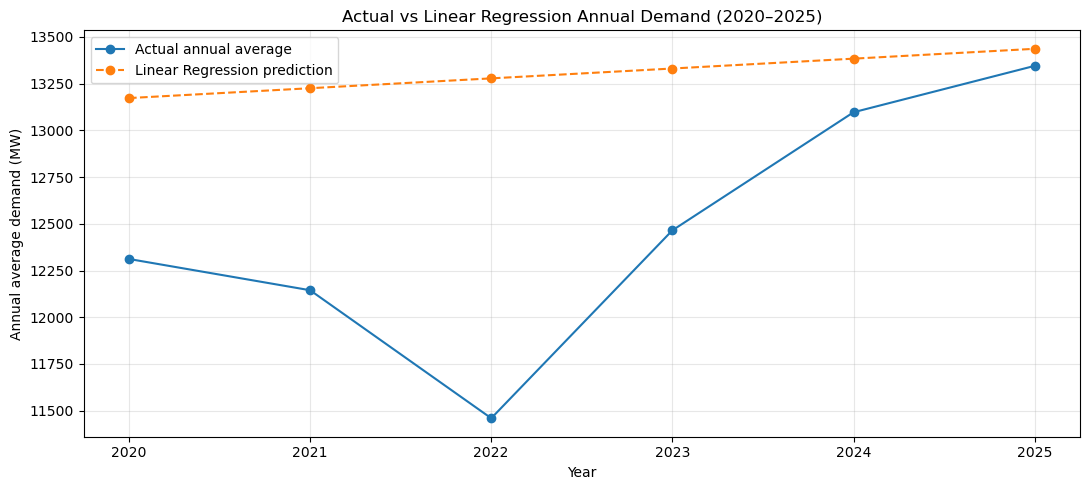

In [93]:
# Plot actual and predicted annual average demand

plt.figure(figsize=(11, 5))

plt.plot(
    annual_test["Year"],
    annual_test["Annual_Average_Demand_MW"],
    marker="o",
    label="Actual annual average"
)

plt.plot(
    annual_test["Year"],
    annual_test["Predicted_Demand_MW"],
    marker="o",
    linestyle="--",
    label="Linear Regression prediction"
)

plt.title("Actual vs Linear Regression Annual Demand (2020–2025)")
plt.xlabel("Year")
plt.ylabel("Annual average demand (MW)")
plt.xticks(annual_test["Year"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [94]:
# Naive annual benchmark: predict each year using the previous year's actual average

annual_naive_test = annual_test.copy()

annual_naive_test["Naive_Prediction_MW"] = (
    annual_demand_df.set_index("Year")["Annual_Average_Demand_MW"]
    .reindex(annual_naive_test["Year"] - 1)
    .to_numpy()
)

naive_annual_mae = mean_absolute_error(
    annual_naive_test["Annual_Average_Demand_MW"],
    annual_naive_test["Naive_Prediction_MW"]
)

naive_annual_rmse = np.sqrt(mean_squared_error(
    annual_naive_test["Annual_Average_Demand_MW"],
    annual_naive_test["Naive_Prediction_MW"]
))

print("Naive Annual Benchmark — 2020–2025")
print("MAE:", round(naive_annual_mae, 2), "MW")
print("RMSE:", round(naive_annual_rmse, 2), "MW")

display(
    annual_naive_test[
        ["Year", "Annual_Average_Demand_MW", "Naive_Prediction_MW"]
    ].round(2)
)

Naive Annual Benchmark — 2020–2025
MAE: 571.39 MW
RMSE: 638.48 MW


,Year,Annual_Average_Demand_MW,Naive_Prediction_MW
14,2020,12311.84,13002.40
15,2021,12144.60,12311.84
16,2022,11459.63,12144.60
17,2023,12465.18,11459.63
18,2024,13096.97,12465.18
19,2025,13345.21,13096.97


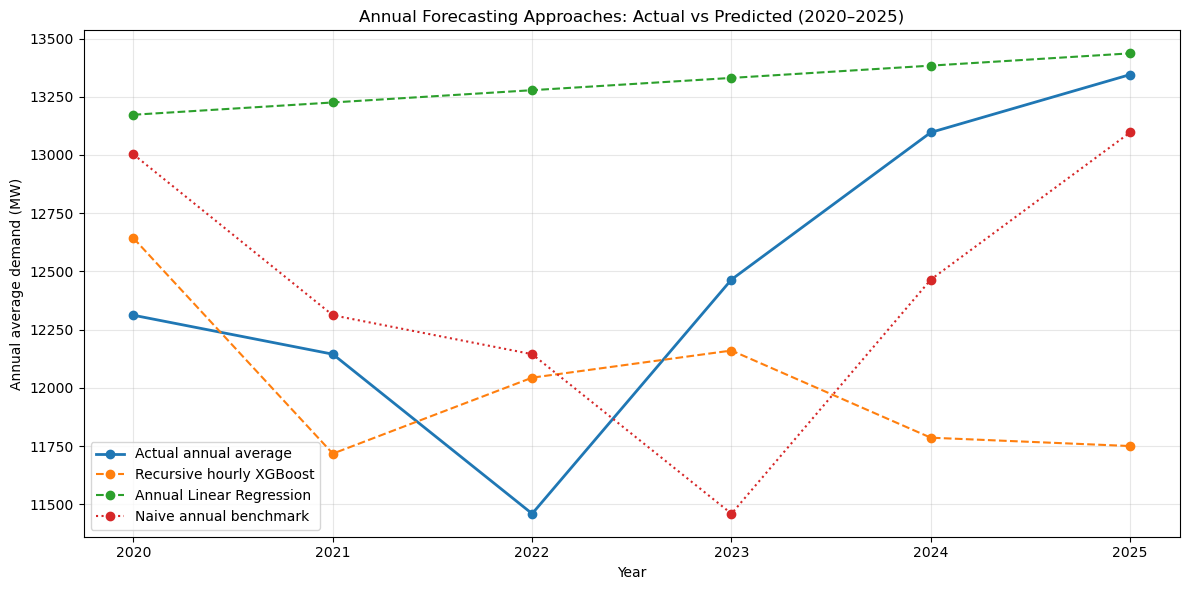

In [95]:
# Compare actual annual demand with all three forecasting approaches

plt.figure(figsize=(12, 6))

plt.plot(
    annual_test["Year"],
    annual_test["Annual_Average_Demand_MW"],
    marker="o",
    linewidth=2,
    label="Actual annual average"
)

plt.plot(
    backtest_annual_comparison.index,
    backtest_annual_comparison["Predicted_Average_MW"],
    marker="o",
    linestyle="--",
    label="Recursive hourly XGBoost"
)

plt.plot(
    annual_test["Year"],
    annual_test["Predicted_Demand_MW"],
    marker="o",
    linestyle="--",
    label="Annual Linear Regression"
)

plt.plot(
    annual_naive_test["Year"],
    annual_naive_test["Naive_Prediction_MW"],
    marker="o",
    linestyle=":",
    label="Naive annual benchmark"
)

plt.title("Annual Forecasting Approaches: Actual vs Predicted (2020–2025)")
plt.xlabel("Year")
plt.ylabel("Annual average demand (MW)")
plt.xticks(annual_test["Year"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## Selecting an Approach for the 2030 Forecast

The comparison of annual forecasting methods showed that the naive annual benchmark achieved the lowest error on the 2020–2025 evaluation period, with an MAE of 571.39 MW and an RMSE of 638.48 MW. Annual Linear Regression and recursive hourly XGBoost performed less well on this period.

However, the naive benchmark uses the previous year's actual annual average as its prediction. It is therefore a one-year-ahead benchmark and cannot be applied directly to forecast several future years when actual demand is unavailable.

The recursive XGBoost backtest also showed increasing underestimation in later years, while annual Linear Regression failed to capture the sharp fall and subsequent recovery in demand.

Given that only 20 annual observations are available, the next step is to evaluate a simple direct annual forecasting model using chronological backtesting. We will assess whether a time-trend model provides reasonably stable results across different historical cutoffs before using it to estimate annual average demand in 2030.

The final estimate will be reported cautiously because a short annual history cannot fully represent future changes in electricity demand, economic conditions, electrification or energy policy.

In [96]:
# Evaluate annual Linear Regression across multiple chronological cutoffs

annual_backtest_results = []

for test_year in range(2015, 2026):
    train = annual_demand_df[
        annual_demand_df["Year"] < test_year
    ].copy()

    test = annual_demand_df[
        annual_demand_df["Year"] == test_year
    ].copy()

    # Train only on years before the test year
    model = LinearRegression()
    model.fit(
        train[["Year"]],
        train["Annual_Average_Demand_MW"]
    )

    prediction = model.predict(test[["Year"]])[0]
    actual = test["Annual_Average_Demand_MW"].iloc[0]

    annual_backtest_results.append({
        "Year": test_year,
        "Actual_Average_MW": actual,
        "Predicted_Average_MW": prediction,
        "Error_MW": prediction - actual,
        "Absolute_Error_MW": abs(prediction - actual)
    })

annual_backtest_df = pd.DataFrame(annual_backtest_results)

display(annual_backtest_df.round(2))

print(
    "\nRolling annual MAE (MW):",
    round(annual_backtest_df["Absolute_Error_MW"].mean(), 2)
)
print(
    "Rolling annual RMSE (MW):",
    round(
        np.sqrt(
            mean_squared_error(
                annual_backtest_df["Actual_Average_MW"],
                annual_backtest_df["Predicted_Average_MW"]
            )
        ),
        2
    )
)

,Year,Actual_Average_MW,Predicted_Average_MW,Error_MW,Absolute_Error_MW
0,2015,12928.45,12691.01,-237.44,237.44
1,2016,13038.55,12802.37,-236.18,236.18
2,2017,13130.17,12917.58,-212.59,212.59
3,2018,13301.75,13028.51,-273.24,273.24
4,2019,13002.40,13160.82,158.42,158.42
5,2020,12311.84,13172.81,860.97,860.97
6,2021,12144.60,12995.94,851.34,851.34
7,2022,11459.63,12814.30,1354.68,1354.68
8,2023,12465.18,12507.98,42.79,42.79
9,2024,13096.97,12484.32,-612.65,612.65



Rolling annual MAE (MW): 507.92
Rolling annual RMSE (MW): 639.12


In [97]:
# Fit annual Linear Regression on all observed years and forecast 2030

annual_final_model = LinearRegression()

annual_final_model.fit(
    annual_demand_df[["Year"]],
    annual_demand_df["Annual_Average_Demand_MW"]
)

annual_2030_input = pd.DataFrame({"Year": [2030]})

annual_lr_forecast_2030 = annual_final_model.predict(
    annual_2030_input
)[0]

print(
    "Annual Linear Regression forecast for 2030:",
    round(annual_lr_forecast_2030, 2),
    "MW"
)
print(
    "Recursive hourly XGBoost forecast for 2030:",
    round(average_demand_2030, 2),
    "MW"
)

Annual Linear Regression forecast for 2030: 12764.34 MW
Recursive hourly XGBoost forecast for 2030: 11875.98 MW


In [151]:
# Test annual Linear Regression using historical years

annual_backtest_results = []

for year in range(2020, 2026):
    train_annual = annual_demand_df[
        annual_demand_df["Year"] < year
    ]

    actual_row = annual_demand_df[
        annual_demand_df["Year"] == year
    ]

    if len(train_annual) > 0 and len(actual_row) > 0:
        model = LinearRegression()

        model.fit(
            train_annual[["Year"]],
            train_annual["Annual_Average_Demand_MW"]
        )

        predicted = model.predict(
            pd.DataFrame({"Year": [year]})
        )[0]

        actual = actual_row[
            "Annual_Average_Demand_MW"
        ].iloc[0]

        annual_backtest_results.append({
            "Year": year,
            "Actual_MW": actual,
            "Predicted_MW": predicted,
            "Error_MW": predicted - actual,
            "Error_Percent": (
                (predicted - actual) / actual
            ) * 100
        })

annual_backtest_df = pd.DataFrame(annual_backtest_results)

print(annual_backtest_df.round(2).to_string(index=False))

 Year  Actual_MW  Predicted_MW  Error_MW  Error_Percent
 2020   12311.84      13172.81    860.97           6.99
 2021   12144.60      12995.94    851.34           7.01
 2022   11459.63      12814.30   1354.68          11.82
 2023   12465.18      12507.98     42.79           0.34
 2024   13096.97      12484.32   -612.65          -4.68
 2025   13345.21      12598.41   -746.80          -5.60


In [152]:
annual_mae = mean_absolute_error(
    annual_backtest_df["Actual_MW"],
    annual_backtest_df["Predicted_MW"]
)

annual_rmse = np.sqrt(mean_squared_error(
    annual_backtest_df["Actual_MW"],
    annual_backtest_df["Predicted_MW"]
))

print("Annual Linear Regression MAE:", round(annual_mae, 2), "MW")
print("Annual Linear Regression RMSE:", round(annual_rmse, 2), "MW")

Annual Linear Regression MAE: 744.87 MW
Annual Linear Regression RMSE: 840.25 MW


In [98]:
# Summarize annual and recursive forecasting backtest results

forecast_model_comparison = pd.DataFrame({
    "Model": [
        "Recursive hourly XGBoost",
        "Annual Linear Regression",
        "Naive annual benchmark",
        "Rolling annual Linear Regression"
    ],
    "MAE_MW": [
        annual_mae,
        annual_lr_mae,
        naive_annual_mae,
        annual_backtest_df["Absolute_Error_MW"].mean()
    ],
    "RMSE_MW": [
        annual_rmse,
        annual_lr_rmse,
        naive_annual_rmse,
        np.sqrt(mean_squared_error(
            annual_backtest_df["Actual_Average_MW"],
            annual_backtest_df["Predicted_Average_MW"]
        ))
    ],
    "Evaluation": [
        "Recursive 2020–2025",
        "Train 2006–2019; test 2020–2025",
        "Previous actual year; test 2020–2025",
        "One-year-ahead rolling evaluation, 2015–2025"
    ]
})

display(
    forecast_model_comparison.sort_values("MAE_MW").round(2)
)

,Model,MAE_MW,RMSE_MW,Evaluation
3,Rolling annual Linear Regression,507.92,639.12,"One-year-ahead rolling evaluation, 2015–2025"
2,Naive annual benchmark,571.39,638.48,Previous actual year; test 2020–2025
0,Recursive hourly XGBoost,758.82,911.85,Recursive 2020–2025
1,Annual Linear Regression,834.05,1004.76,Train 2006–2019; test 2020–2025


## Comparison of Forecasting Approaches and Candidate 2030 Estimates

Several forecasting approaches were evaluated to estimate the Netherlands' annual average electricity demand in 2030.

The recursive hourly XGBoost model produced a 2030 annual average estimate of **11,875.98 MW**. However, its recursive backtest showed a mean annual bias of −453.81 MW and substantial underestimation in 2024 and 2025. This indicates that the model struggled to capture changes in demand over a multi-year horizon.

A direct annual Linear Regression model produced a higher 2030 estimate of **12,764.34 MW**. Its simplicity makes it easier to interpret, but its historical evaluation showed that a linear trend could not consistently capture sharp declines and recoveries in annual demand.

The rolling annual Linear Regression evaluation achieved an MAE of 507.92 MW, while the naive annual benchmark achieved an MAE of 571.39 MW and an RMSE of 638.48 MW. These results provide useful reference points, but the evaluation methods differ and do not establish which approach is most reliable for a five-year forecast.

Therefore, the estimates of 11,875.98 MW and 12,764.34 MW should be treated as candidate model outputs rather than definitive predictions. Further evaluation of multi-year forecasting performance is needed before selecting a final estimate for 2030.

In [99]:
# Compare annual models over the same six-year forecast horizon

annual_train_2019 = annual_demand_df[
    annual_demand_df["Year"] <= 2019
].copy()

annual_test_2020_2025 = annual_demand_df[
    annual_demand_df["Year"].between(2020, 2025)
].copy()

# Annual Linear Regression trained only through 2019
fixed_horizon_model = LinearRegression()
fixed_horizon_model.fit(
    annual_train_2019[["Year"]],
    annual_train_2019["Annual_Average_Demand_MW"]
)

fixed_horizon_predictions = fixed_horizon_model.predict(
    annual_test_2020_2025[["Year"]]
)

# Fixed-level naive baseline: repeat the last observed annual average
last_actual_average = annual_train_2019[
    "Annual_Average_Demand_MW"
].iloc[-1]

fixed_naive_predictions = np.repeat(
    last_actual_average,
    len(annual_test_2020_2025)
)

# Evaluate both approaches on exactly the same years
actual_annual_values = annual_test_2020_2025[
    "Annual_Average_Demand_MW"
].to_numpy()

fixed_horizon_comparison = pd.DataFrame({
    "Year": annual_test_2020_2025["Year"].to_numpy(),
    "Actual_Average_MW": actual_annual_values,
    "Annual_Linear_Regression_MW": fixed_horizon_predictions,
    "Fixed_Naive_MW": fixed_naive_predictions
})

display(fixed_horizon_comparison.round(2))

print("Annual Linear Regression")
print("MAE:", round(mean_absolute_error(
    actual_annual_values, fixed_horizon_predictions
), 2), "MW")
print("RMSE:", round(np.sqrt(mean_squared_error(
    actual_annual_values, fixed_horizon_predictions
)), 2), "MW")

print("\nFixed-level naive baseline")
print("MAE:", round(mean_absolute_error(
    actual_annual_values, fixed_naive_predictions
), 2), "MW")
print("RMSE:", round(np.sqrt(mean_squared_error(
    actual_annual_values, fixed_naive_predictions
)), 2), "MW")

,Year,Actual_Average_MW,Annual_Linear_Regression_MW,Fixed_Naive_MW
0,2020,12311.84,13172.81,13002.4
1,2021,12144.60,13225.53,13002.4
2,2022,11459.63,13278.26,13002.4
3,2023,12465.18,13330.98,13002.4
4,2024,13096.97,13383.70,13002.4
5,2025,13345.21,13436.43,13002.4


Annual Linear Regression
MAE: 834.05 MW
RMSE: 1004.76 MW

Fixed-level naive baseline
MAE: 677.62 MW
RMSE: 817.3 MW


In [100]:
# Five-year annual backtest: train through 2014, forecast 2015–2019

train_2014 = annual_demand_df[
    annual_demand_df["Year"] <= 2014
].copy()

test_2015_2019 = annual_demand_df[
    annual_demand_df["Year"].between(2015, 2019)
].copy()

# Fixed-level baseline
last_average_2014 = train_2014[
    "Annual_Average_Demand_MW"
].iloc[-1]

naive_predictions_2015_2019 = np.repeat(
    last_average_2014,
    len(test_2015_2019)
)

# Linear Regression
model_2014 = LinearRegression()
model_2014.fit(
    train_2014[["Year"]],
    train_2014["Annual_Average_Demand_MW"]
)

linear_predictions_2015_2019 = model_2014.predict(
    test_2015_2019[["Year"]]
)

actual_2015_2019 = test_2015_2019[
    "Annual_Average_Demand_MW"
].to_numpy()

comparison_2015_2019 = pd.DataFrame({
    "Year": test_2015_2019["Year"].to_numpy(),
    "Actual_Average_MW": actual_2015_2019,
    "Fixed_Naive_MW": naive_predictions_2015_2019,
    "Annual_Linear_Regression_MW": linear_predictions_2015_2019
})

display(comparison_2015_2019.round(2))

print("Fixed-level naive MAE:",
      round(mean_absolute_error(
          actual_2015_2019, naive_predictions_2015_2019
      ), 2), "MW")

print("Fixed-level naive RMSE:",
      round(np.sqrt(mean_squared_error(
          actual_2015_2019, naive_predictions_2015_2019
      )), 2), "MW")

print("Annual Linear Regression MAE:",
      round(mean_absolute_error(
          actual_2015_2019, linear_predictions_2015_2019
      ), 2), "MW")

print("Annual Linear Regression RMSE:",
      round(np.sqrt(mean_squared_error(
          actual_2015_2019, linear_predictions_2015_2019
      )), 2), "MW")

,Year,Actual_Average_MW,Fixed_Naive_MW,Annual_Linear_Regression_MW
0,2015,12928.45,12706.79,12691.01
1,2016,13038.55,12706.79,12707.39
2,2017,13130.17,12706.79,12723.77
3,2018,13301.75,12706.79,12740.14
4,2019,13002.40,12706.79,12756.52


Fixed-level naive MAE: 373.47 MW
Fixed-level naive RMSE: 394.92 MW
Annual Linear Regression MAE: 356.5 MW
Annual Linear Regression RMSE: 376.05 MW


In [101]:
# Summarize model performance across both multi-year backtests

backtest_summary = pd.DataFrame({
    "Forecast_Period": ["2015–2019", "2015–2019", "2020–2025", "2020–2025"],
    "Model": [
        "Fixed-level naive",
        "Annual Linear Regression",
        "Fixed-level naive",
        "Annual Linear Regression"
    ],
    "MAE_MW": [
        373.47, 356.50, 677.62, 834.05
    ],
    "RMSE_MW": [
        394.92, 376.05, 817.30, 1004.76
    ]
})

display(backtest_summary)

,Forecast_Period,Model,MAE_MW,RMSE_MW
0,2015–2019,Fixed-level naive,373.47,394.92
1,2015–2019,Annual Linear Regression,356.50,376.05
2,2020–2025,Fixed-level naive,677.62,817.30
3,2020–2025,Annual Linear Regression,834.05,1004.76


In [102]:
# Recent historical annual average demand

recent_annual_demand = annual_demand_df[
    annual_demand_df["Year"].between(2021, 2025)
]

recent_average = recent_annual_demand[
    "Annual_Average_Demand_MW"
].mean()

print(
    "Mean annual average demand (2021–2025):",
    round(recent_average, 2),
    "MW"
)

Mean annual average demand (2021–2025): 12502.32 MW


#### Interpretation of the 2030 electricity-demand forecast

The recursive XGBoost model forecasts an annual average electricity demand of **11,875.98 MW** for the Netherlands in 2030, while the annual Linear Regression model forecasts **12,764.34 MW**. The mean annual average demand from 2021 to 2025 was 12,502.32 MW.

The XGBoost estimate is approximately 5.01% below the recent historical average, whereas the Linear Regression estimate is approximately 2.10% above it. This difference highlights the uncertainty associated with long-term forecasting. Backtesting showed that the recursive XGBoost model struggled to capture the recovery in demand during 2024 and 2025, while annual Linear Regression did not consistently outperform a naive baseline.

Therefore, these results should be interpreted as exploratory model-based estimates rather than precise predictions. The models use historical demand patterns and do not explicitly account for future changes in population, electrification, energy efficiency, economic activity, or energy policy.


---

# 11. Additional Analysis: What Powers the Netherlands?

This section explores the Netherlands' electricity supply and generation mix using data from Statistics Netherlands (CBS).

It examines the contribution of different energy sources, with a particular focus on renewable electricity generation, to understand how the country's electricity system has changed over time.

### Objectives
- Analyse the electricity balance sheet, including production, consumption, imports, and exports.
- Identify the main electricity generation sources.
- Investigate the growth of renewable electricity, particularly solar and wind.
- Prepare key findings and summary tables for the Power BI dashboard.

**Data sources:** CBS — Electricity Balance Sheet; Supply and Consumption, and Electricity Production from Renewable Sources.


In [103]:
# Load the CBS electricity balance and renewable electricity datasets

balance_path = Path(
    "../data/raw/84575ENG_SelectieMetStatSymbol_20261013102003.csv"
)

renewable_path = Path(
    "../data/raw/82610ENG_SelectieMetStatSymbol_20261019150220.csv"
)

# CBS CSV files use semicolons as separators.
balance_df = pd.read_csv(
    balance_path,
    sep=";",
    encoding="utf-8-sig"
)

renewable_df = pd.read_csv(
    renewable_path,
    sep=";",
    encoding="utf-8-sig"
)

# Inspect the datasets
print("ELECTRICITY BALANCE SHEET")
print("Shape:", balance_df.shape)
display(balance_df.head())

print("\nRENEWABLE ELECTRICITY DATA")
print("Shape:", renewable_df.shape)
display(renewable_df.head())


ELECTRICITY BALANCE SHEET
Shape: (20, 31)


,Periods,Gross production (mln kWh),Own consumption for electr. production (mln kWh),"Net production/Net production, total (mln kWh)",Net production/Nuclear energy (mln kWh),"Net production/Fuels/Fuels, total (mln kWh)",Net production/Fuels/Coal (mln kWh),Net production/Fuels/Petroleum products (mln kWh),Net production/Fuels/Natural gas (mln kWh),Net production/Fuels/Biomass (mln kWh),...,Imports/United Kingdom (mln kWh),Imports/Norway (mln kWh),"Exports/Exports, total (mln kWh)",Exports/Belgium (mln kWh),Exports/Denmark (mln kWh),Exports/Germany (mln kWh),Exports/United Kingdom (mln kWh),Exports/Norway (mln kWh),Distribution losses (mln kWh),Net consumption (calculated) (mln kWh)
0,2006,98835,3953,94882,.,.,.,.,.,4703,...,NaN,NaN,5887,5604,NaN,283,NaN,NaN,4537,111804
1,2007,105164,4120,101044,.,.,.,.,.,3556,...,NaN,NaN,5480,5231,NaN,249,NaN,NaN,4626,114027
2,2008,108201,4107,104094,.,.,.,.,.,4562,...,NaN,3155.0,9116,7957,NaN,827,NaN,333.0,4678,115266
3,2009,113503,4250,109253,.,.,.,.,.,5463,...,NaN,2813.0,10564,5792,NaN,3509,NaN,1263.0,4405,109736
4,2010,118150,3781,114369,.,.,.,.,.,6331,...,NaN,1327.0,12808,7390,NaN,3070,NaN,2347.0,4464,112681



RENEWABLE ELECTRICITY DATA
Shape: (49, 10)


,Energy sources / techniques,Periods,Production of electricity/Gross production with normalisation (mln kWh),Production of electricity/Production without normalisation/Gross production of electricity (mln kWh),Production of electricity/Production without normalisation/Net production of electricity (mln kWh),Production of electricity relative/Gross production with normalisation (in % of use),Production of electricity relative/Production without normalisation/Gross production of electricity (in % of use),Production of electricity relative/Production without normalisation/Net production of electricity (in % of use),Installed installations/Installations installed end of year (number),Installed installations/Electrical capacity end of year (megawatt)
0,Total renewable energy sources,2019,22277,22796,22041,18.23,18.65,18.57,.,.
1,Total renewable energy sources,2020,31924,32740,31792,26.41,27.14,27.12,.,.
2,Total renewable energy sources,2021,40706,40433,38888,33.25,33.03,32.91,.,.
3,Total renewable energy sources,2022,46512,48093,46510,39.65,41.00,41.16,.,.
4,Total renewable energy sources,2023,53840,56952,55483,46.42,49.10,49.46,.,.


In [104]:
# Inspect the years and available renewable energy categories

print("YEARS IN ELECTRICITY BALANCE SHEET")
print(sorted(balance_df["Periods"].dropna().unique()))

print("\nRENEWABLE ENERGY CATEGORIES")
print(
    renewable_df["Energy sources / techniques"]
    .dropna()
    .unique()
)

print("\nYEARS IN RENEWABLE ELECTRICITY DATA")
print(sorted(renewable_df["Periods"].dropna().unique()))


YEARS IN ELECTRICITY BALANCE SHEET
['2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021 ', '2022', '2023', '2024**', '2025**']

RENEWABLE ENERGY CATEGORIES
['Total renewable energy sources' 'Hydropower' 'Wind energy, total'
 'Onshore wind energy' 'Offshore wind energy' 'Solar photovoltaic'
 'Total biomass']

YEARS IN RENEWABLE ELECTRICITY DATA
['2019', '2020', '2021', '2022', '2023', '2024**', '2025**']


In [105]:
# Clean year labels and convert numeric columns

# Remove extra spaces and provisional markers from year labels
balance_df["Periods"] = (
    balance_df["Periods"]
    .astype(str)
    .str.strip()
    .str.replace("*", "", regex=False)
)

renewable_df["Periods"] = (
    renewable_df["Periods"]
    .astype(str)
    .str.strip()
    .str.replace("*", "", regex=False)
)

# Convert year columns to integers
balance_df["Periods"] = pd.to_numeric(
    balance_df["Periods"], errors="coerce"
).astype("Int64")

renewable_df["Periods"] = pd.to_numeric(
    renewable_df["Periods"], errors="coerce"
).astype("Int64")

# Convert CBS numeric values to numbers.
# CBS uses "." for unavailable values.
for df in [balance_df, renewable_df]:
    for col in df.columns:
        if col != "Periods" and col != "Energy sources / techniques":
            df[col] = pd.to_numeric(
                df[col].replace(".", pd.NA), errors="coerce"
            )

print("Cleaned electricity balance years:")
print(sorted(balance_df["Periods"].dropna().unique()))

print("\nCleaned renewable electricity years:")
print(sorted(renewable_df["Periods"].dropna().unique()))

print("\nMissing values in renewable data:")
display(renewable_df.isna().sum())


Cleaned electricity balance years:
[np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Cleaned renewable electricity years:
[np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Missing values in renewable data:


Energy sources / techniques                                                                                           0
Periods                                                                                                               0
Production of electricity/Gross production with normalisation (mln kWh)                                               0
Production of electricity/Production without normalisation/Gross production of electricity (mln kWh)                  0
Production of electricity/Production without normalisation/Net production of electricity (mln kWh)                    0
Production of electricity relative/Gross production with normalisation (in % of use)                                  0
Production of electricity relative/Production without normalisation/Gross production of electricity (in % of use)     0
Production of electricity relative/Production without normalisation/Net production of electricity (in % of use)       0
Installed installations/Installations in

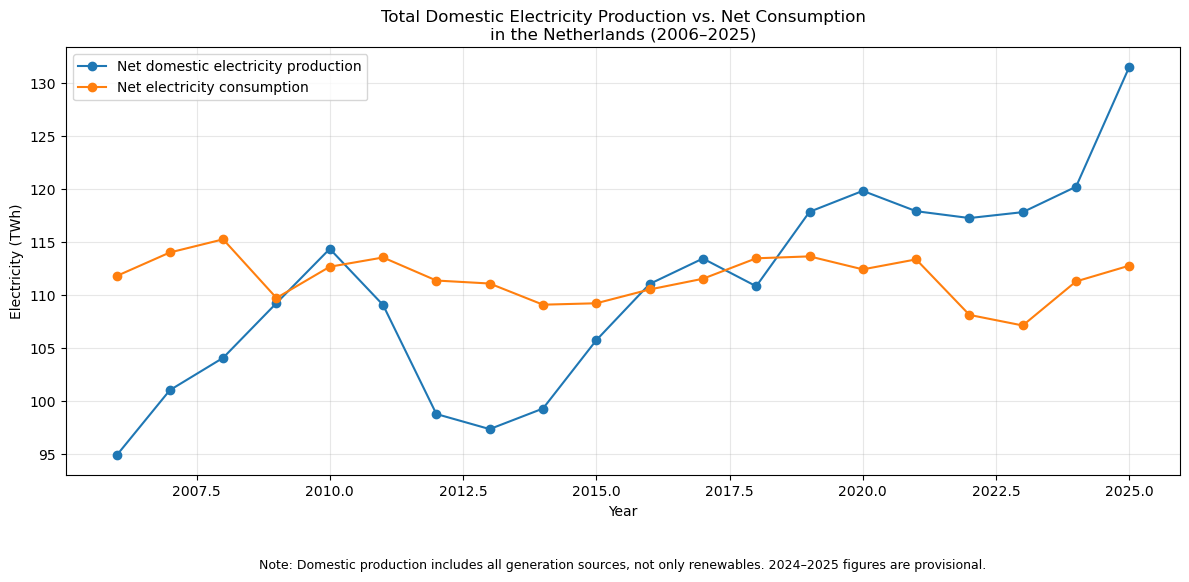

,Year,Net domestic electricity production (TWh),Net electricity consumption (TWh)
0,2006,94.88,111.80
1,2007,101.04,114.03
2,2008,104.09,115.27
3,2009,109.25,109.74
4,2010,114.37,112.68
5,2011,109.07,113.56
6,2012,98.79,111.38
7,2013,97.37,111.10
8,2014,99.31,109.10
9,2015,105.75,109.24


In [106]:
# TOTAL DOMESTIC ELECTRICITY PRODUCTION VS. NET CONSUMPTION
# Source: CBS Electricity Balance Sheet
# Units: TWh (converted from million kWh)
# Note: Production is domestic electricity production, not renewable production alone.

production_col = "Net production/Net production, total (mln kWh)"
consumption_col = "Net consumption (calculated) (mln kWh)"

balance_chart_df = balance_df[
    ["Periods", production_col, consumption_col]
].copy()

balance_chart_df = balance_chart_df.rename(
    columns={
        "Periods": "Year",
        production_col: "Net domestic electricity production (TWh)",
        consumption_col: "Net electricity consumption (TWh)"
    }
)

# Convert million kWh to TWh
balance_chart_df["Net domestic electricity production (TWh)"] /= 1000
balance_chart_df["Net electricity consumption (TWh)"] /= 1000

# Plot the data
ax = balance_chart_df.plot(
    x="Year",
    y=[
        "Net domestic electricity production (TWh)",
        "Net electricity consumption (TWh)"
    ],
    kind="line",
    figsize=(12, 6),
    marker="o"
)

ax.set_title(
    "Total Domestic Electricity Production vs. Net Consumption\n"
    "in the Netherlands (2006–2025)"
)
ax.set_xlabel("Year")
ax.set_ylabel("Electricity (TWh)")
ax.grid(True, alpha=0.3)

ax.legend([
    "Net domestic electricity production",
    "Net electricity consumption"
])

# Add a reminder directly below the chart
ax.text(
    0.5, -0.22,
    "Note: Domestic production includes all generation sources, "
    "not only renewables. 2024–2025 figures are provisional.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    wrap=True
)

plt.tight_layout()
plt.show()

display(balance_chart_df.round(2))


### Interpretation: Total Domestic Electricity Production vs. Net Consumption (2006–2025)

The chart compares total domestic net electricity production with net electricity consumption in the Netherlands between 2006 and 2025. The figures are based on Statistics Netherlands (CBS) electricity balance data and are expressed in terawatt-hours (TWh).

**Key findings**

- **Domestic production increased overall.** Net electricity production rose from 94.88 TWh in 2006 to 131.54 TWh in 2025.
- **Consumption remained relatively stable.** Net electricity consumption increased only slightly, from 111.80 TWh in 2006 to 112.78 TWh in 2025.
- **The relationship changed over time.** In earlier years, consumption was generally higher than domestic production. In recent years, production exceeded consumption.
- **Consumption declined in 2022 and 2023.** It fell to 108.14 TWh in 2022 and 107.14 TWh in 2023, before recovering in 2024 and 2025.
- **Production increased sharply in 2025.** Net domestic production reached 131.54 TWh, while consumption remained much lower at 112.78 TWh.

**Conclusion**

The data show that domestic electricity production has grown considerably faster than net consumption over the period. This indicates a change in the Netherlands' electricity supply position. However, the difference between production and consumption alone does not explain all electricity trade flows, and it should not be interpreted as a direct measure of renewable electricity generation.

**Data limitation:** The 2024 and 2025 figures are provisional and may be revised.

### Prepare the renewable-generation data

The plotting and forecast cells below use `renewable_pivot`. This cell creates that table from the cleaned CBS dataset, selects five individual renewable sources, and converts net production from million kWh to TWh. The total renewable category and total wind category are excluded to avoid mixing totals with individual sources.


In [125]:
# PREPARE RENEWABLE ELECTRICITY DATA FOR PLOTTING
# Source: CBS — Electricity Production from Renewable Sources
# Measure: Net production without normalisation
# Original unit: million kWh
# Converted unit: TWh

renewable_value_col = (
    "Production of electricity/Production without normalisation/"
    "Net production of electricity (mln kWh)"
)

selected_renewable_sources = [
    "Hydropower",
    "Onshore wind energy",
    "Offshore wind energy",
    "Solar photovoltaic",
    "Total biomass",
]

# Select the five individual renewable sources
renewable_plot_df = renewable_df.loc[
    renewable_df["Energy sources / techniques"].isin(
        selected_renewable_sources
    ),
    [
        "Periods",
        "Energy sources / techniques",
        renewable_value_col,
    ],
].copy()

# Reshape the data: one row per year and one column per source
renewable_pivot = renewable_plot_df.pivot(
    index="Periods",
    columns="Energy sources / techniques",
    values=renewable_value_col,
).sort_index()

# Convert million kWh to TWh
renewable_pivot = renewable_pivot / 1000

# IMPORTANT:
# Preserve the original source names expected by Power BI.
# Do not rename "Offshore wind energy" to "Offshore wind".
renewable_pivot = renewable_pivot[
    [
        "Solar photovoltaic",
        "Onshore wind energy",
        "Offshore wind energy",
        "Total biomass",
        "Hydropower",
    ]
]

# Check the resulting data
renewable_pivot.index.name = "Year"

print("Renewable generation data (TWh):")
print("Columns:", renewable_pivot.columns.tolist())
display(renewable_pivot.round(2))

Renewable generation data (TWh):
Columns: ['Solar photovoltaic', 'Onshore wind energy', 'Offshore wind energy', 'Total biomass', 'Hydropower']


Energy sources / techniques,Solar photovoltaic,Onshore wind energy,Offshore wind energy,Total biomass,Hydropower
Year,,,,,
2019,5.40,7.94,3.57,5.06,0.07
2020,8.57,9.79,5.48,7.90,0.05
2021,11.30,9.81,7.86,9.82,0.09
2022,16.66,13.13,7.94,8.73,0.05
2023,19.61,17.48,11.55,6.77,0.07
2024,21.82,17.66,15.18,5.93,0.08
2025,25.88,16.42,15.61,6.30,0.06


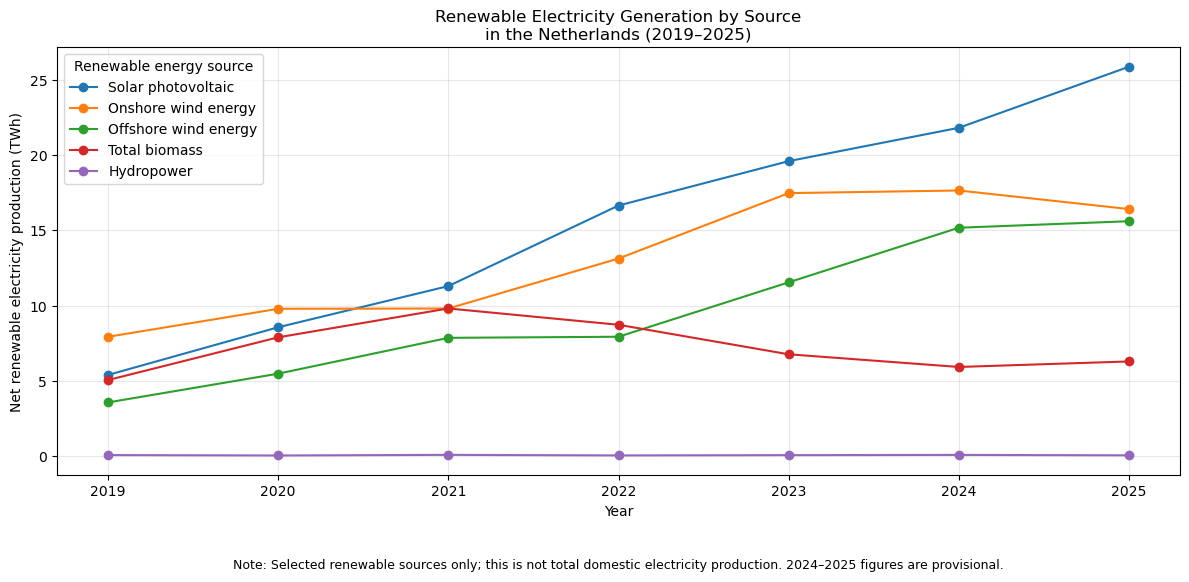

Energy sources / techniques,Solar photovoltaic,Onshore wind energy,Offshore wind energy,Total biomass,Hydropower
Year,,,,,
2019,5.40,7.94,3.57,5.06,0.07
2020,8.57,9.79,5.48,7.90,0.05
2021,11.30,9.81,7.86,9.82,0.09
2022,16.66,13.13,7.94,8.73,0.05
2023,19.61,17.48,11.55,6.77,0.07
2024,21.82,17.66,15.18,5.93,0.08
2025,25.88,16.42,15.61,6.30,0.06


In [126]:
# RENEWABLE ELECTRICITY GENERATION BY SOURCE, 2019–2025
# Source: CBS — Electricity Production from Renewable Sources
# Values show net electricity production in TWh.
# This chart includes selected renewable sources, not total domestic generation.

ax = renewable_pivot.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

ax.set_title(
    "Renewable Electricity Generation by Source\n"
    "in the Netherlands (2019–2025)"
)
ax.set_xlabel("Year")
ax.set_ylabel("Net renewable electricity production (TWh)")
ax.grid(True, alpha=0.3)
ax.legend(title="Renewable energy source")

ax.text(
    0.5, -0.22,
    "Note: Selected renewable sources only; this is not total domestic "
    "electricity production. 2024–2025 figures are provisional.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9,
    wrap=True
)

plt.tight_layout()
plt.show()

display(renewable_pivot.round(2))


### Interpretation: Renewable Electricity Generation by Source (2019–2025)

This chart examines net electricity production from five renewable energy categories in the Netherlands: solar photovoltaic, onshore wind, offshore wind, biomass, and hydropower. The data are from Statistics Netherlands (CBS) and are expressed in terawatt-hours (TWh).

**Key findings**

- **Solar photovoltaic showed the strongest growth.** Net generation increased from 5.40 TWh in 2019 to 25.88 TWh in 2025, making solar the largest of the five sources shown.
- **Wind power expanded considerably.** Offshore wind increased from 3.57 TWh to 15.61 TWh. Onshore wind grew from 7.94 TWh to 16.42 TWh, although it declined between 2024 and 2025.
- **Biomass generation declined after 2021.** It peaked at 9.82 TWh in 2021 and stood at 6.30 TWh in 2025.
- **Hydropower remained a minor contributor.** Generation stayed below 0.10 TWh per year throughout the period.

**Conclusion**

The data show that solar and wind have become increasingly important sources of renewable electricity in the Netherlands. Solar recorded particularly strong growth, while offshore wind also expanded substantially. In contrast, biomass generation was lower in 2025 than at its 2021 peak, and hydropower contributed very little to the total of the sources shown.

**Scope and data limitation:** This chart includes selected renewable sources only; it does not represent total domestic electricity production or the complete electricity generation mix. The 2024 and 2025 figures are provisional and may be revised.

PROJECTED NET RENEWABLE ELECTRICITY PRODUCTION IN 2030 (TWh)


Year,2030 forecast
Solar photovoltaic,43.11
Onshore wind energy,27.14
Offshore wind energy,26.52
Total biomass,6.28
Hydropower,0.07



FULL FORECAST TABLE (TWh)


,Solar photovoltaic,Onshore wind energy,Offshore wind energy,Total biomass,Hydropower
Year,,,,,
2026,29.36,20.16,18.06,6.75,0.07
2027,32.79,21.90,20.17,6.63,0.07
2028,36.23,23.65,22.29,6.51,0.07
2029,39.67,25.39,24.40,6.39,0.07
2030,43.11,27.14,26.52,6.28,0.07


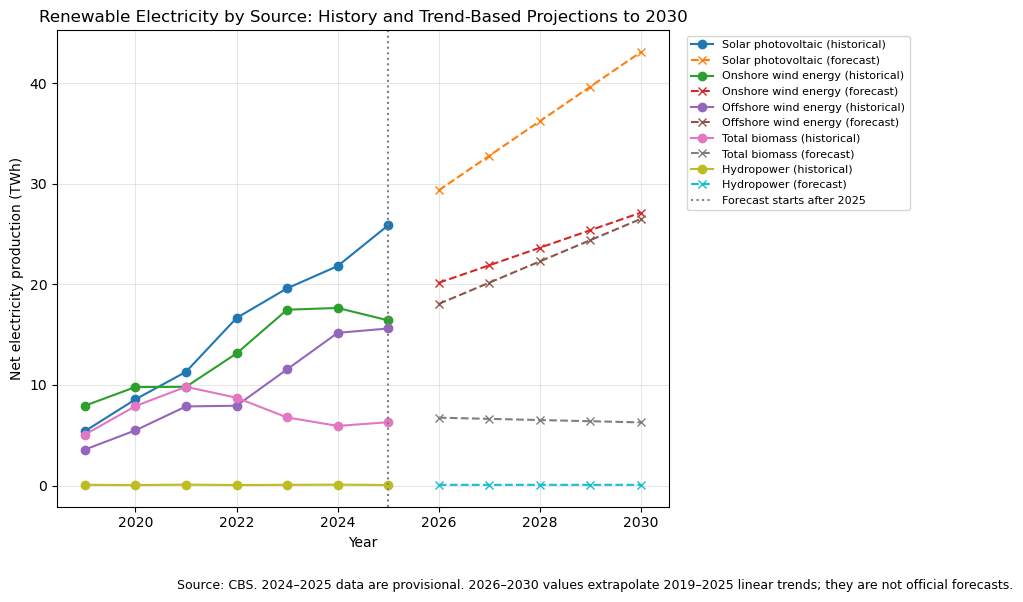

In [127]:
# 2030 FORECAST: INDIVIDUAL RENEWABLE ELECTRICITY SOURCES
# Method: Linear trend fitted to annual net production, 2019–2025
# Units: TWh
# Important: These are trend-based projections, not official forecasts.

historical = renewable_pivot.copy()
historical.index = historical.index.astype(int)
historical = historical.sort_index()

forecast_years = np.arange(2026, 2031)
all_years = np.arange(
    historical.index.min(),
    2031
)

forecast_values = {}

for source in historical.columns:
    # Fit a straight-line trend to the historical observations
    x = historical.index.to_numpy(dtype=float)
    y = historical[source].to_numpy(dtype=float)

    slope, intercept = np.polyfit(x, y, 1)

    # Project production for 2026–2030
    predictions = slope * forecast_years + intercept

    # Electricity production cannot be negative
    predictions = np.maximum(predictions, 0)

    forecast_values[source] = predictions

forecast_df = pd.DataFrame(
    forecast_values,
    index=forecast_years
)
forecast_df.index.name = "Year"

print("PROJECTED NET RENEWABLE ELECTRICITY PRODUCTION IN 2030 (TWh)")
display(forecast_df.loc[[2030]].T.rename(columns={2030: "2030 forecast"}).round(2))

print("\nFULL FORECAST TABLE (TWh)")
display(forecast_df.round(2))

# Plot historical values and future projections
fig, ax = plt.subplots(figsize=(12, 6))

for source in historical.columns:
    ax.plot(
        historical.index,
        historical[source],
        marker="o",
        label=f"{source} (historical)"
    )

    ax.plot(
        forecast_years,
        forecast_df[source],
        linestyle="--",
        marker="x",
        label=f"{source} (forecast)"
    )

ax.axvline(
    2025,
    color="gray",
    linestyle=":",
    label="Forecast starts after 2025"
)

ax.set_title(
    "Renewable Electricity by Source: History and Trend-Based "
    "Projections to 2030"
)
ax.set_xlabel("Year")
ax.set_ylabel("Net electricity production (TWh)")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

fig.text(
    0.5,
    0.01,
    "Source: CBS. 2024–2025 data are provisional. "
    "2026–2030 values extrapolate 2019–2025 linear trends; "
    "they are not official forecasts.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.05, 0.78, 1])
plt.show()


### Methodology and Interpretation: Exploratory Renewable Electricity Projections to 2030

As an additional analysis to the main electricity demand forecasting project, historical renewable electricity generation in the Netherlands was examined to understand how individual energy sources have evolved over time.

**Methodology**

Annual CBS data from 2019 to 2025 were used to create exploratory projections for five renewable electricity sources: solar photovoltaic, onshore wind, offshore wind, biomass, and hydropower.

A simple linear regression trend was fitted separately to each source's historical production values. The estimated trend was then extrapolated to project annual net electricity production from 2026 to 2030. The results are expressed in terawatt-hours (TWh).

**Key observations**

- Solar photovoltaic shows the strongest projected growth, continuing its substantial historical increase.
- Onshore and offshore wind generation are projected to increase if their historical trends continue.
- Biomass generation shows a relatively flat to declining projected trend.
- Hydropower remains a small contributor compared with the other sources shown.

**Limitations**

These projections are exploratory trend-based estimates, not official forecasts or precise predictions of electricity generation in 2030. The model uses only seven annual observations per source and assumes that historical linear trends continue. It does not account for future capacity additions, government policies, weather variability, grid constraints, or changes in energy markets. The 2024 and 2025 CBS observations are provisional and may be revised.

**Conclusion**

This additional analysis provides context for the Netherlands' changing electricity mix and illustrates how the contributions of individual renewable sources could evolve if recent trends continued. It complements the main electricity demand forecasting analysis but should be interpreted separately from the primary forecasting results.

# 12. Additional Analysis: Electricity Consumption by Data Centres in the Netherlands

This section explores the growth of electricity consumption by data centres in the Netherlands and its potential relevance to future electricity demand.

Data centres require electricity to operate servers, store data, and support digital services. As digital infrastructure expands, their electricity consumption is an important factor to consider when examining changes in the Netherlands' electricity system.

The analysis uses data from Statistics Netherlands (CBS) on electricity supplied to data centres through the public electricity grid between 2017 and 2024.

### Objectives

- Examine how data-centre electricity consumption has changed over time.
- Analyse the share of national electricity consumption accounted for by data centres.
- Consider the relevance of this trend to the Netherlands' future electricity demand.

**Data source:** Statistics Netherlands (CBS), *Electricity supplied to data centres, 2017–2024*.

**Scope and limitations:** This is a supporting analysis, not a separate forecasting model. The historical trend provides context but does not establish how much data centres will contribute to future electricity demand.

,Year,Data centre electricity (GWh),Share of national electricity consumption (%)
0,2017,1652.0,1.48
1,2018,2367.0,2.09
2,2019,2747.0,2.42
3,2020,3184.0,2.82
4,2021,3730.0,3.29
5,2022,4306.0,3.98
6,2023,4489.0,4.19
7,2024,5093.0,4.58


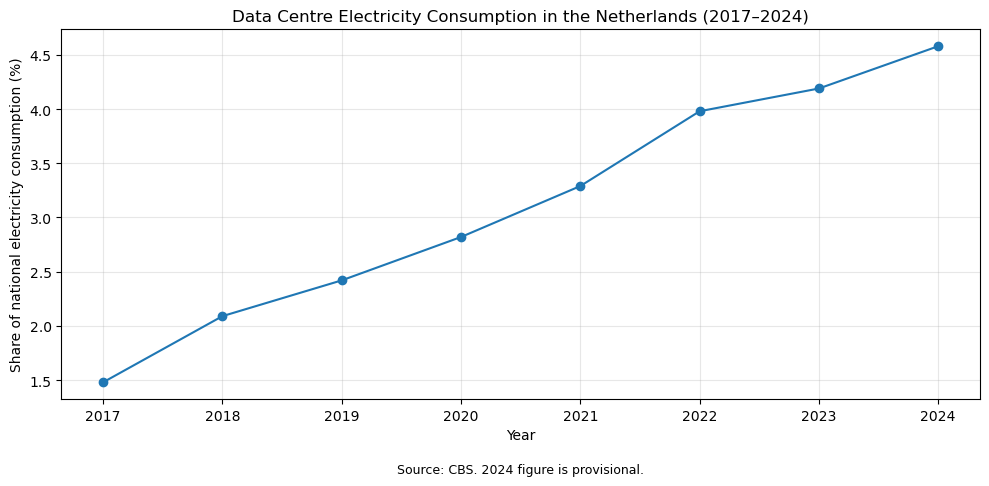

In [128]:
# DATA CENTRE ELECTRICITY CONSUMPTION IN THE NETHERLANDS
# Source: CBS, Electricity supplied to data centres, 2017–2024
# 2024 data are provisional.

datacenter_file = (
    "../data/raw/datacenters_elektriciteitsleveringen_2017_2024.xlsx"
)

# Read the CBS worksheet without changing the original workbook
dc_raw = pd.read_excel(
    datacenter_file,
    sheet_name="Tabel 1",
    header=None
)

# Extract years and the percentage of national electricity consumption
dc_years = [int(year) for year in dc_raw.iloc[4, 3:10]]
dc_years.append(2024)

dc_share = pd.to_numeric(
    dc_raw.iloc[11, 3:11].astype(str).str.replace("*", "", regex=False),
    errors="coerce"
).to_numpy()

dc_gwh = pd.to_numeric(
    dc_raw.iloc[7, 3:11],
    errors="coerce"
).to_numpy()

datacenter_df = pd.DataFrame({
    "Year": dc_years,
    "Data centre electricity (GWh)": dc_gwh,
    "Share of national electricity consumption (%)": dc_share
})

display(datacenter_df)

# Plot the share of national electricity consumption
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    datacenter_df["Year"],
    datacenter_df["Share of national electricity consumption (%)"],
    marker="o"
)

ax.set_title(
    "Data Centre Electricity Consumption in the Netherlands (2017–2024)"
)
ax.set_xlabel("Year")
ax.set_ylabel("Share of national electricity consumption (%)")
ax.grid(True, alpha=0.3)

ax.text(
    0.5, -0.20,
    "Source: CBS. 2024 figure is provisional.",
    transform=ax.transAxes,
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()


### Interpretation: Data Centre Electricity Consumption in the Netherlands (2017–2024)

The data show a steady increase in electricity consumption by data centres in the Netherlands between 2017 and 2024.

**Key findings**

- **Electricity consumption increased substantially.** Data-centre electricity consumption rose from 1,652 GWh in 2017 to 5,093 GWh in 2024.
- **The share of national consumption more than tripled.** Data centres accounted for 1.48% of national electricity consumption in 2017, compared with 4.58% in 2024.
- **Growth continued in recent years.** Consumption increased from 4,489 GWh in 2023 to 5,093 GWh in 2024.

**Conclusion**

The figures show that data centres have become a more significant electricity consumer in the Netherlands. Their growing consumption is relevant when considering factors that may contribute to future electricity demand. However, this analysis does not establish how much data centres contribute to changes in total national demand or predict their future consumption.

**Data source and limitation:** Statistics Netherlands (CBS), electricity supplied to data centres, 2017–2024. The 2024 figure is provisional.

PROJECTED DATA CENTRE ELECTRICITY CONSUMPTION


,Year,Projected data centre electricity (GWh)
0,2025,5585.0
1,2026,6060.0
2,2027,6535.0
3,2028,7010.0
4,2029,7486.0
5,2030,7961.0


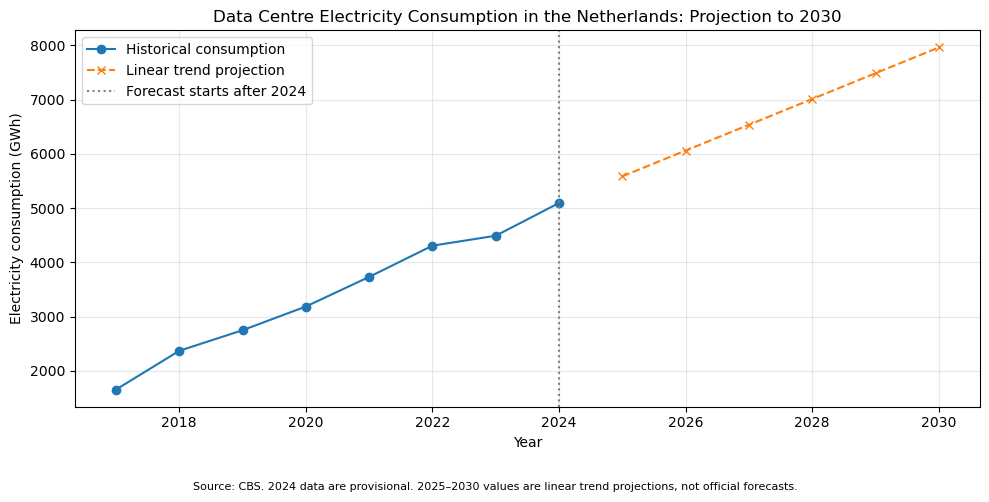

In [129]:
# EXPLORATORY DATA CENTRE ELECTRICITY PROJECTION TO 2030
# Method: Simple linear regression using historical data from 2017–2024
# Units: GWh
# This is a trend-based projection, not an official forecast.

# Prepare historical data
x = datacenter_df["Year"].to_numpy(dtype=float)
y = datacenter_df["Data centre electricity (GWh)"].to_numpy(dtype=float)

# Fit a straight-line trend
slope, intercept = np.polyfit(x, y, 1)

# Project electricity consumption for 2025–2030
forecast_years = np.arange(2025, 2031)
forecast_values = slope * forecast_years + intercept

datacenter_forecast = pd.DataFrame({
    "Year": forecast_years,
    "Projected data centre electricity (GWh)": forecast_values
})

print("PROJECTED DATA CENTRE ELECTRICITY CONSUMPTION")
display(datacenter_forecast.round(0))

# Plot historical data and projections
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    datacenter_df["Year"],
    datacenter_df["Data centre electricity (GWh)"],
    marker="o",
    label="Historical consumption"
)

ax.plot(
    datacenter_forecast["Year"],
    datacenter_forecast["Projected data centre electricity (GWh)"],
    marker="x",
    linestyle="--",
    label="Linear trend projection"
)

ax.axvline(2024, color="gray", linestyle=":", label="Forecast starts after 2024")

ax.set_title(
    "Data Centre Electricity Consumption in the Netherlands: "
    "Projection to 2030"
)
ax.set_xlabel("Year")
ax.set_ylabel("Electricity consumption (GWh)")
ax.grid(True, alpha=0.3)
ax.legend()

fig.text(
    0.5, 0.01,
    "Source: CBS. 2024 data are provisional. "
    "2025–2030 values are linear trend projections, not official forecasts.",
    ha="center",
    fontsize=8
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


### Interpretation: Exploratory Data Centre Electricity Projection to 2030

This analysis uses simple linear regression to extend the historical trend in Dutch data-centre electricity consumption from 2017–2024 to 2030.

**Key finding**

The model projects data-centre electricity consumption to reach approximately **7,961 GWh (7.96 TWh) by 2030**, compared with 5,093 GWh in 2024.

**Methodology**

A straight-line trend was fitted to annual CBS electricity-consumption data from 2017 to 2024. The estimated trend was extrapolated to generate projections for 2025–2030.

**Limitations**

This is an exploratory projection, not an official forecast. It assumes that the historical linear trend continues and does not account for changes in data-centre capacity, energy efficiency, future investment, policy, or other factors that may influence electricity consumption. The 2024 observation is provisional.

**Conclusion**

The projection illustrates how continued growth in data-centre electricity consumption could contribute to future electricity demand in the Netherlands. It provides supporting context for the main electricity-demand forecasting project but should not be interpreted as a precise prediction of consumption in 2030.

## Optional Appendix: Exporting Tables for Power BI

The following cells are retained as an optional hand-off step for the **“What Powers the Netherlands” Power BI dashboard**. They export already-calculated results to CSV; they do not train models or change the analysis.

Run these cells only when you want to refresh the dashboard data files. The files are saved in `data/powerbi/` relative to the project folder. In Power BI, connect to the relevant CSV files and refresh the visuals after regenerating them.

The exports include the 2025 actual-versus-predicted demand comparison, model evaluation metrics, 2030 demand forecast outputs, annual electricity production versus consumption, renewable generation and its exploratory trend projection, and data-centre consumption and projection.

**Note:** The renewable-generation and data-centre projections are exploratory trend-based estimates, not official forecasts. Keep that distinction clear in dashboard titles and explanatory notes.


In [160]:
# Use the current Jupyter working directory as the project root.
# If the notebook was launched from a subfolder, check its parent as well.
project_folder = Path.cwd()
if not (project_folder / "data").exists() and (project_folder.parent / "data").exists():
    project_folder = project_folder.parent

export_folder = project_folder / "data" / "powerbi"
export_folder.mkdir(parents=True, exist_ok=True)

print(f"Power BI exports will be saved to: {export_folder.resolve()}")

# 1. Actual vs predicted demand for 2025
forecast_2025 = pd.DataFrame({
    "Timestamp": test_df["Timestamp"].values,
    "Actual_Demand_MW": y_test,
    "Predicted_Demand_MW": y_pred_xgb_final
})

forecast_2025.to_csv(
    export_folder / "forecast_2025_comparison.csv",
    index=False
)

# 2. Compare the three models
metrics_df = pd.DataFrame([
    {"Model": "Naive weekly baseline", "MAE_MW": 540.45, "RMSE_MW": 750.46},
    {"Model": "Linear Regression", "MAE_MW": 308.27, "RMSE_MW": 401.28},
    {"Model": "Tuned XGBoost", "MAE_MW": 147.39, "RMSE_MW": 198.91}
])

metrics_df.to_csv(
    export_folder / "model_evaluation_metrics_3_methods.csv",
    index=False
)

# 3. Hourly XGBoost forecast for 2030
forecast_2030[
    ["Timestamp", "Predicted_Demand_MW", "Month"]
].to_csv(
    export_folder / "forecast_2030_hourly_xgboost.csv",
    index=False
)

# 4. Compare the three annual-average demand estimates for 2030

annual_2030_df = pd.DataFrame([
    {
        "Method": "Hourly XGBoost",
        "Forecast_2030_MW": average_demand_2030
    },
    {
        "Method": "Annual Linear Regression",
        "Forecast_2030_MW": annual_lr_forecast_2030
    },
    {
        "Method": "Recent average baseline",
        "Forecast_2030_MW": recent_average
    }
])

# Create a Power BI-friendly export without changing
# the original annual_2030_df column names
annual_2030_powerbi = annual_2030_df.rename(
    columns={
        "Method": "Forecast_Method",
        "Forecast_2030_MW": "Annual_Average_Demand_MW"
    }
).copy()

annual_2030_powerbi["Year"] = 2030

# Clarify that XGBoost's value is the annual average
# of its hourly predictions
annual_2030_powerbi["Forecast_Method"] = (
    annual_2030_powerbi["Forecast_Method"].replace({
        "Hourly XGBoost":
            "XGBoost (annual average of hourly predictions)",
        "Annual Linear Regression":
            "Annual Linear Regression",
        "Recent average baseline":
            "Recent historical average baseline"
    })
)

annual_2030_powerbi = annual_2030_powerbi[
    ["Year", "Forecast_Method", "Annual_Average_Demand_MW"]
]

annual_2030_powerbi.to_csv(
    export_folder / "forecast_2030_annual_method_comparison.csv",
    index=False
)

print("2030 annual comparison CSV created:")
display(annual_2030_powerbi.round(2))

Power BI exports will be saved to: C:\Users\Winifred\Ironhack\Part time program\Projects\Final project_v2\data\powerbi
2030 annual comparison CSV created:


,Year,Forecast_Method,Annual_Average_Demand_MW
0,2030,XGBoost (annual average of hourly predictions),11875.98
1,2030,Annual Linear Regression,12764.34
2,2030,Recent historical average baseline,12502.32


In [161]:
# Export combined historical and forecast data-centre consumption
# for Power BI

# Historical data: keep the original values and year
datacenter_history_export = datacenter_df[
    ["Year", "Data centre electricity (GWh)"]
].copy()

datacenter_history_export = datacenter_history_export.rename(
    columns={
        "Data centre electricity (GWh)": "Historical_Consumption_GWh"
    }
)

# Forecast data: keep the original values and year
datacenter_forecast_export = datacenter_forecast[
    ["Year", "Projected data centre electricity (GWh)"]
].copy()

datacenter_forecast_export = datacenter_forecast_export.rename(
    columns={
        "Projected data centre electricity (GWh)": "Projected_Consumption_GWh"
    }
)

# Combine both datasets by year
datacenter_combined = pd.merge(
    datacenter_history_export,
    datacenter_forecast_export,
    on="Year",
    how="outer"
).sort_values("Year")

# Export to the existing Power BI folder
datacenter_combined.to_csv(
    export_folder / "datacenter_history_forecast_combined.csv",
    index=False
)

print("Combined data-centre CSV created:")
print(f"Rows: {len(datacenter_combined)}")
display(datacenter_combined.round(2))

Combined data-centre CSV created:
Rows: 14


,Year,Historical_Consumption_GWh,Projected_Consumption_GWh
0,2017,1652.0,NaN
1,2018,2367.0,NaN
2,2019,2747.0,NaN
3,2020,3184.0,NaN
4,2021,3730.0,NaN
5,2022,4306.0,NaN
6,2023,4489.0,NaN
7,2024,5093.0,NaN
8,2025,NaN,5584.57
9,2026,NaN,6059.81


### Export supporting electricity-system datasets

This second export cell writes the supporting datasets used in the dashboard's electricity-supply and data-centre sections. It is separate from the main demand-forecast exports so these additional analyses can be refreshed together.

The renewable and data-centre projection files should be labelled as **exploratory projections** in Power BI, rather than as official 2030 forecasts.


In [131]:
# Export the five remaining datasets for Power BI
# Use the current Jupyter working directory as the project root.
# If the notebook was launched from a subfolder, check its parent as well.
project_folder = Path.cwd()
if not (project_folder / "data").exists() and (project_folder.parent / "data").exists():
    project_folder = project_folder.parent

export_folder = project_folder / "data" / "powerbi"
export_folder.mkdir(parents=True, exist_ok=True)

print(f"Power BI exports will be saved to: {export_folder.resolve()}")

# 1. Annual electricity production vs. consumption
balance_chart_df.to_csv(
    export_folder / "electricity_balance_annual.csv",
    index=False
)

# 2. Historical renewable electricity generation by source
renewable_pivot_export = renewable_pivot.copy()
renewable_pivot_export.insert(
    0, "Year", renewable_pivot_export.index
)
renewable_pivot_export.to_csv(
    export_folder / "renewable_generation.csv",
    index=False
)

# 3. Exploratory renewable generation projections for 2030
renewable_forecast_export = forecast_df.copy()
renewable_forecast_export.insert(
    0, "Year", renewable_forecast_export.index
)
renewable_forecast_export.to_csv(
    export_folder / "renewable_forecast_2030.csv",
    index=False
)

# 4. Historical data-centre electricity consumption
datacenter_df.to_csv(
    export_folder / "datacenter_consumption.csv",
    index=False
)

# 5. Exploratory data-centre electricity projection to 2030
datacenter_forecast.to_csv(
    export_folder / "datacenter_forecast_2030.csv",
    index=False
)

# Confirm the files
print("Exports saved to:", export_folder)
for file in [
    "electricity_balance_annual.csv",
    "renewable_generation.csv",
    "renewable_forecast_2030.csv",
    "datacenter_consumption.csv",
    "datacenter_forecast_2030.csv"
]:
    path = export_folder / file
    print(f"{file}: {'Created' if path.exists() else 'NOT FOUND'}")

Power BI exports will be saved to: C:\Users\Winifred\Ironhack\Part time program\Projects\Final project_v2\data\powerbi
Exports saved to: C:\Users\Winifred\Ironhack\Part time program\Projects\Final project_v2\data\powerbi
electricity_balance_annual.csv: Created
renewable_generation.csv: Created
renewable_forecast_2030.csv: Created
datacenter_consumption.csv: Created
datacenter_forecast_2030.csv: Created


## Analysis

In [140]:

# Check yearly demand in the 2030 forecast dataframe

forecast_2030_check = forecast_2030.copy()

forecast_2030_check["Timestamp"] = pd.to_datetime(
    forecast_2030_check["Timestamp"],
    errors="coerce"
)

forecast_2030_check = forecast_2030_check.dropna(
    subset=["Timestamp", "Predicted_Demand_MW"]
)

yearly_check = (
    forecast_2030_check
    .groupby(forecast_2030_check["Timestamp"].dt.year)[
        "Predicted_Demand_MW"
    ]
    .agg(["mean", "min", "max"])
    .round(2)
)

yearly_check.columns = [
    "Average_Demand_MW",
    "Minimum_Demand_MW",
    "Maximum_Demand_MW"
]

display(yearly_check)


,Average_Demand_MW,Minimum_Demand_MW,Maximum_Demand_MW
Timestamp,,,
2030,11875.980469,8765.070312,15948.139648


In [141]:

print("Available forecast dataframes:")

for name in ["forecast_2026", "forecast_2027", "forecast_2028",
             "forecast_2029", "forecast_2030"]:
    if name in globals():
        print(name, "exists")
    else:
        print(name, "not found")

print("\nForecast start:", forecast_2030["Timestamp"].min())
print("Forecast end:", forecast_2030["Timestamp"].max())


Available forecast dataframes:
forecast_2026 not found
forecast_2027 not found
forecast_2028 not found
forecast_2029 not found
forecast_2030 exists

Forecast start: 2030-01-01 00:00:00
Forecast end: 2030-12-31 23:00:00


In [144]:

# Safely inspect available historical demand data

print("Checking available dataframes...\n")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        if "Timestamp" in obj.columns:
            demand_cols = [
                col for col in obj.columns
                if "demand" in col.lower() and "mw" in col.lower()
            ]

            if demand_cols:
                print(f"Dataframe: {name}")
                print("Date range:",
                      obj["Timestamp"].min(), "to",
                      obj["Timestamp"].max())
                print("Demand columns:", demand_cols)
                print("Rows:", len(obj))
                print("-" * 40)


Checking available dataframes...

Dataframe: feature_df
Date range: 2006-01-01 00:00:00 to 2025-12-31 23:00:00
Demand columns: ['Demand_MW']
Rows: 175320
----------------------------------------
Dataframe: model_df
Date range: 2006-01-08 00:00:00 to 2025-12-31 23:00:00
Demand columns: ['Demand_MW']
Rows: 175112
----------------------------------------
Dataframe: train_df
Date range: 2006-01-08 00:00:00 to 2024-12-31 23:00:00
Demand columns: ['Demand_MW']
Rows: 166352
----------------------------------------
Dataframe: test_df
Date range: 2025-01-01 00:00:00 to 2025-12-31 23:00:00
Demand columns: ['Demand_MW']
Rows: 8760
----------------------------------------
Dataframe: expanded_model_df
Date range: 2006-01-15 00:00:00 to 2025-12-31 23:00:00
Demand columns: ['Demand_MW']
Rows: 173284
----------------------------------------
Dataframe: train_df_expanded
Date range: 2006-01-15 00:00:00 to 2024-12-31 23:00:00
Demand columns: ['Demand_MW']
Rows: 164524
------------------------------------

In [145]:

# Compare annual average electricity demand:
# historical years versus the 2030 forecast

historical_yearly = (
    forecast_train_df
    .assign(Timestamp=pd.to_datetime(forecast_train_df["Timestamp"]))
    .groupby(forecast_train_df["Timestamp"].dt.year)["Demand_MW"]
    .mean()
)

forecast_yearly = (
    forecast_2030
    .assign(Timestamp=pd.to_datetime(forecast_2030["Timestamp"]))
    .groupby(forecast_2030["Timestamp"].dt.year)["Predicted_Demand_MW"]
    .mean()
)

print("Historical annual average demand:")
display(historical_yearly.tail(5).round(2))

print("2030 forecast annual average demand:")
display(forecast_yearly.round(2))


Historical annual average demand:


Timestamp
2021    12144.60
2022    11459.63
2023    12465.18
2024    13096.97
2025    13345.21
Name: Demand_MW, dtype: float64

2030 forecast annual average demand:


Timestamp
2030    11875.980469
Name: Predicted_Demand_MW, dtype: float32

In [146]:

# Compare the three existing 2030 forecasting methods

display(
    annual_2030_df[
        ["Method", "Forecast_2030_MW"]
    ].round(2)
)


,Method,Forecast_2030_MW
0,Hourly XGBoost,11875.98
1,Annual Linear Regression,12764.34
2,Recent average baseline,12502.32


In [147]:

# Calculate year-to-year changes in annual average demand

trend_check = annual_demand_df[
    annual_demand_df["Year"].between(2021, 2025)
][["Year", "Annual_Average_Demand_MW"]].copy()

trend_check = trend_check.sort_values("Year")

trend_check["Change_MW"] = (
    trend_check["Annual_Average_Demand_MW"].diff().round(2)
)

trend_check["Change_Percent"] = (
    trend_check["Annual_Average_Demand_MW"]
    .pct_change()
    .mul(100)
    .round(2)
)

display(trend_check.round(2))


,Year,Annual_Average_Demand_MW,Change_MW,Change_Percent
15,2021,12144.60,NaN,NaN
16,2022,11459.63,-684.97,-5.64
17,2023,12465.18,1005.56,8.77
18,2024,13096.97,631.79,5.07
19,2025,13345.21,248.24,1.90


In [148]:

# Compare actual and recursive forecast annual averages

actual_backtest = backtest_test_df.copy()
pred_backtest = backtest_forecast_df.copy()

actual_backtest["Timestamp"] = pd.to_datetime(
    actual_backtest["Timestamp"]
)
pred_backtest["Timestamp"] = pd.to_datetime(
    pred_backtest["Timestamp"]
)

actual_yearly = (
    actual_backtest.groupby(
        actual_backtest["Timestamp"].dt.year
    )["Demand_MW"].mean()
)

pred_yearly = (
    pred_backtest.groupby(
        pred_backtest["Timestamp"].dt.year
    )["Predicted_Demand_MW"].mean()
)

backtest_comparison = pd.DataFrame({
    "Actual_MW": actual_yearly,
    "Recursive_Forecast_MW": pred_yearly
})

backtest_comparison["Error_MW"] = (
    backtest_comparison["Recursive_Forecast_MW"]
    - backtest_comparison["Actual_MW"]
)

display(backtest_comparison.round(2))


,Actual_MW,Recursive_Forecast_MW,Error_MW
Timestamp,,,
2020,12311.84,12642.639648,330.80
2021,12144.60,11717.589844,-427.01
2022,11459.63,12043.830078,584.21
2023,12465.18,12160.320312,-304.87
2024,13096.97,11785.969727,-1311.00
2025,13345.21,11750.200195,-1595.01


In [149]:

print("Forecast start:", future_timestamps.min())
print("Forecast end:", future_timestamps.max())
print("Number of forecast hours:", len(future_timestamps))

print(
    "Expected number of hours:",
    len(pd.date_range(
        start="2026-01-01 00:00:00",
        end="2030-12-31 23:00:00",
        freq="h"
    ))
)

print(
    "Forecast starts correctly:",
    future_timestamps.min() == pd.Timestamp("2026-01-01 00:00:00")
)

print(
    "Forecast ends correctly:",
    future_timestamps.max() == pd.Timestamp("2030-12-31 23:00:00")
)


Forecast start: 2026-01-01 00:00:00
Forecast end: 2030-12-31 23:00:00
Number of forecast hours: 43824
Expected number of hours: 43824
Forecast starts correctly: True
Forecast ends correctly: True


In [150]:

# Measure annual recursive forecast errors

diagnostic = backtest_comparison.copy()

diagnostic["Absolute_Error_MW"] = diagnostic["Error_MW"].abs()

diagnostic["Error_Percent"] = (
    diagnostic["Error_MW"] / diagnostic["Actual_MW"] * 100
).round(2)

display(diagnostic.round(2))

print(
    "\nAverage absolute annual error:",
    round(diagnostic["Absolute_Error_MW"].mean(), 2),
    "MW"
)


,Actual_MW,Recursive_Forecast_MW,Error_MW,Absolute_Error_MW,Error_Percent
Timestamp,,,,,
2020,12311.84,12642.639648,330.80,330.80,2.69
2021,12144.60,11717.589844,-427.01,427.01,-3.52
2022,11459.63,12043.830078,584.21,584.21,5.10
2023,12465.18,12160.320312,-304.87,304.87,-2.45
2024,13096.97,11785.969727,-1311.00,1311.00,-10.01
2025,13345.21,11750.200195,-1595.01,1595.01,-11.95



Average absolute annual error: 758.82 MW
